# STELES PIPELINE 

## RED CHANNEL - Wavelength Solution and Spatial Distortion correction

VERSION FOR DATA TAKEN AFTER MISSION 14 - 2026-01-28 OR LATER

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

import sys

# local packages
sys.path.insert(0, '../')
import steles_pipeline_ccd  as steles
import steles_pipeline_spec as steles_spec
    
from astropy.io import fits

def create_directory(directory):
    if not os.path.isdir(directory):
        os.mkdir(directory)
        
        
def write_fits(data, header, output_path, overwrite=True):
    hdu = fits.PrimaryHDU(data, header=header)
    hdul = fits.HDUList([hdu])
    hdul.writeto(output_path, overwrite=overwrite)

print("LOADED")

LOADED


In [42]:
# 1) set directories
raw_directory   = 'D:/SOAR/Steles/2026-06-30_blue/' # directory containing raw data
#raw_directory   = 'D:/SOAR/Steles/2026-06-30_red/' # directory containing raw data
red_directory   = raw_directory + 'RED/'       # directory to store processed data
wave_directory  = red_directory + 'db_dev_wavelength/'  # directory to store wavelength solution information
dist_directory  = red_directory + "db_dev_distortion/"  # directory to store spatial distortion information

# create directories if they do not exist
create_directory(wave_directory)
create_directory(dist_directory)

file_extension = '.fits' # default FITS file extension
plot_extension = '.png'  # default plot extension

trace_suffix = '_rectified'            # suffix of results from STELES_pipeline_(blue/red).ipynb 

channel      = 'red'
channel      = 'blue'
fileout_flat = 'master_flat'
fileout_sci  = 'master_HR1996_600mas'
fileout_arc  = 'master_ThAr_800mas'

flat_extracted = fileout_flat + trace_suffix + file_extension # Quartz lamp
sci_extracted  = fileout_sci  + trace_suffix + file_extension # Sci spectrum
arc_extracted  = fileout_arc  + trace_suffix + file_extension # ThAr lamp (60 sec + 1 sec)
    
with fits.open(red_directory+arc_extracted) as hdul:
    arc2d   = hdul[0].data
    arc2d_header = hdul[0].header

# get number of orders, number of spatial and spectral pixels
n_orders, n_spat, n_spec = arc2d.shape

# define reference spatial pixel at the center of the array
ymid = int(np.round(0.5*n_spat,0))
y_range = [ymid-1,ymid+1]

# create a 1d spectrum to evaluate the wavelength solution
arc1d_mid    = steles_spec.collapse_spectrum2d(arc2d)#, row_range=y_range)
arc1d_header = arc2d_header

fits.writeto(red_directory+arc_extracted.replace(file_extension,"_1d"+file_extension), arc1d_mid, arc1d_header, overwrite=True)

print("DONE")

DONE


In [43]:
# load all parameters for wavelength solution and spatial distortion fitting

# now perform the wavelength solution
#wavelength_info_xlsx = wave_directory + 'red_wavelength_solution.xlsx'

#######################################
# wavelength solution fitting

# fit window for refine_peak_positions(), in pixels
window_fit_peak = 11
# Polynomial degree for wavelength solution (default=3)
ndeg_wavesolution = 3

# Spatial distortion fitting parameters

# measure wavelength solution for every 'n_pix_step' pixels in the spatial direction to correct for distortion
n_pix_step = 1
# polynomial order to fit spatial distortion
ndeg_distortion = 2
saturation_threshold = 500000 # exclude lines brighter than this value (saturated)
sigma_threshold      = 5.     # exclude lines fainter than 'sigma_threshold'-sigma

# apply sigma-clipping on the measurements before fitting (exclude outliers)
fitting_sigma_threshold=3.0
fitting_niter=3

# set reference pixels to show the distortion of the data along the spatial axis
wave_pixel_reference = [2, int(np.round(n_spat * 0.5)), n_spat-1-2]

# set limit on x-axis for plotting the results
spectral_pixel_limits = [1500,2000]

# blaze fitting
blaze_polyfit_min_degree   = 15 # minimum degree for polynomial fitting the blaze
blaze_polyfit_max_degree   = 55 # maximum degree for polynomial fitting the blaze
blaze_polyfit_sigma_thresh = 5  # apply sigma-clipping to exclude outliers before fitting the blaze
blaze_ncols = 7                 # number of columns for plotting the blaze fitting

# output files
wavelength_solution_file    = os.path.join(red_directory, arc_extracted.replace(file_extension,'_wavelength_solution'+file_extension))
wavelength_solution_logfile = os.path.join(red_directory, arc_extracted.replace(file_extension,"_wavelength_solution.log"))

spatdist_csv_prefix = os.path.join(dist_directory,  arc_extracted.replace(file_extension,f"_polyfit"))

spatdist_corrected_2d_file = os.path.join(red_directory, arc_extracted.replace(file_extension,"_spatdist"   +file_extension))
spatdist_corrected_1d_file = os.path.join(red_directory, arc_extracted.replace(file_extension,"_spatdist_1d"+file_extension))

# start a new array to save the wavelength solution in the same format as the input "arc1d_extracted" file.
wave1d = arc1d_mid.copy()


print("DONE")

DONE


Working on order=36...


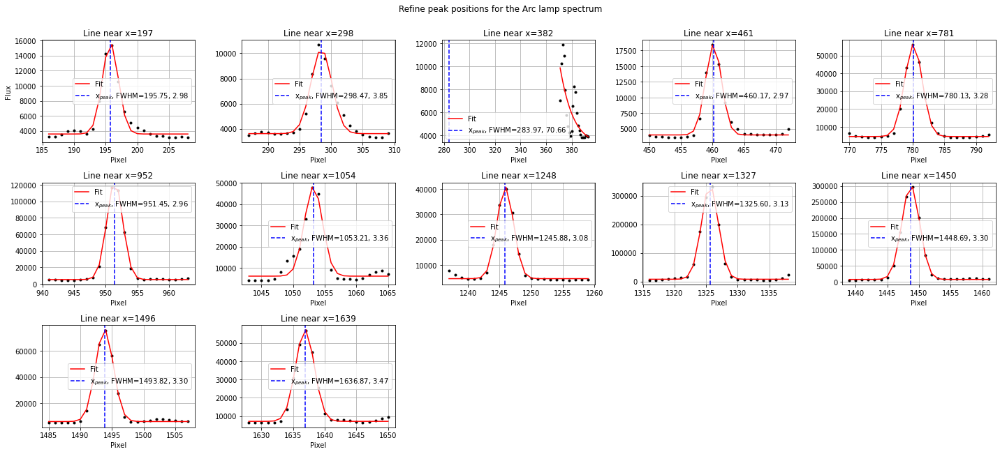

Converged at iteration 2


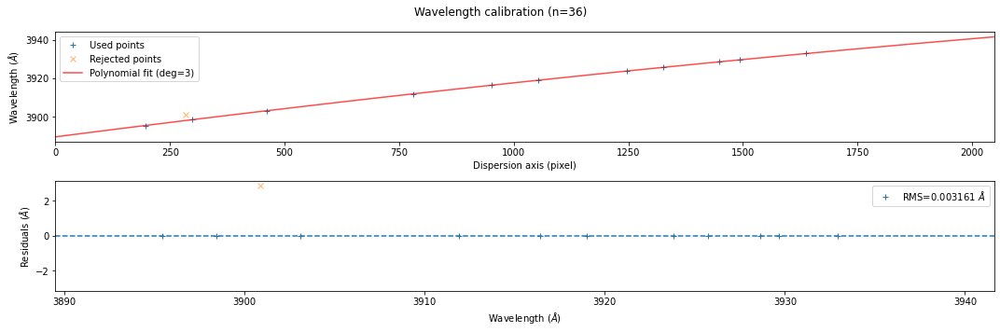

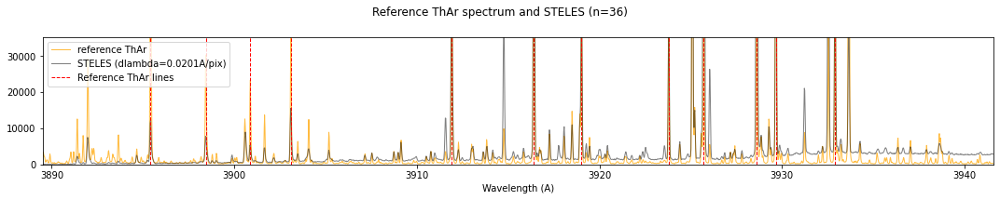

Dispersion=0.0201 A/pix


In [62]:
# open the file containing the information of the order locations at the center of the CCD
wavelength_info_xlsx = f'../db/{channel}_wavelength_solution_2026-06.xlsx'
wavelength_info = pd.read_excel(wavelength_info_xlsx)
order_now =36

n_orders = np.unique(wavelength_info['order'])
for order in n_orders:
    if order == order_now:
        print(f"Working on order={order}...")
        wave_n = wavelength_info[wavelength_info['order'] == order].copy()
        n_order = order
        ThAr_peak_wavelengths = wave_n['wavelength'].to_numpy()
        ThAr_peak_pixels      = wave_n['pixel'].to_numpy()
        
        #ThAr_peak_pixels -= 11
        # now extract the data
        arc_spectrum       = arc1d_mid[order-1,:]
        arc_wavesol_prefix = arc_extracted.replace(file_extension,f'_1d_n{order:02d}')
        # run the wavelength solution fitting
        wavelength_axis, rms_wavesol, wave_polyfit, refined_peaks = steles_spec.fit_wavelength_solution(arc_spectrum, ThAr_peak_wavelengths, ThAr_peak_pixels, order,
                                                                                      fit_window=window_fit_peak, max_fwhm_threshold=10,  wavesolution_ndeg=3, wavesolution_niter=3, wavesolution_rms_threshold=2.,
                                                                                      save_plots=True, plot_directory=wave_directory,  plot_prefix=arc_wavesol_prefix, plot_extension=plot_extension, displ_percent_max=98,                                                                                                  
                                                                                      ref_thar_directory="../db/", ref_thar_file="ThAr_atlas_3000_10600_75k")
        
        # save wavelength as spectral axis
        wave1d[order-1,:] = wavelength_axis
        # information for the header
        # Estimate the dispersion from wavelength axis
        dispersion = abs(np.diff(wavelength_axis))
        # minimum dispersion (A/pix)
        min_disp  = np.nanmin(dispersion)
        # central, min and max wavelength (in A)
        mid_wave  = wavelength_axis[int(0.5*len(arc_spectrum.data))]
        min_wave = np.nanmin(wavelength_axis)
        max_wave = np.nanmax(wavelength_axis)
        # add wavelength solution information on header 
        arc_header_out = arc1d_header.copy()
        arc_header_out
        arc_header_out.set('ST_ORDER', value=order,        comment='Spectral order')
        arc_header_out.set('ST_WVDEG', value=ndeg_wavesolution, comment='Polynomial degree of the wavelength solution')
        arc_header_out.set('ST_WVRMS', value=rms_wavesol,  comment='RMS of the wavelength solution (Angstrom)')
        for m, coeff in enumerate(wave_polyfit.parameters):
            arc_header_out.set(f'ST_WV_C{m}', value=coeff,  comment='n-th order poly. coeff for wavelength solution')
        arc_header_out.set('ST_WVMIN', value=min_wave,     comment='Minimum wavelength (Angstrom)')
        arc_header_out.set('ST_WVMAX', value=max_wave,     comment='Maximum wavelength (Angstrom)')
        arc_header_out.set('ST_WVMID', value=mid_wave,     comment='Central Wavelength of the order (Angstrom)')
        arc_header_out.set('ST_WVDSP', value=min_disp,     comment='Minimum dispersion of the order (A/pix)')
        arc_header_out.set('ST_APER1', value="Flux",       comment='Aperture 1 - array[*,1]')
        arc_header_out.set('ST_APER2', value="Wavelength", comment='Aperture 2 - array[*,2]')
        arc_header_interp_out = arc_header_out.copy()
        del arc_header_interp_out['ST_APER1']
        del arc_header_interp_out['ST_APER2']
        # default saving: [flux, wavelength] x order - do not interpolate!
        #arc_nointerp = [arc_spectrum, wavelength_axis]
        #write_fits(arc_nointerp, arc_header_out, os.path.join(wave_directory, arc_wavesol_prefix + file_extension), overwrite=True)
        arc_interp, wave_linear, arc_header_interp_out = steles_spec.interpolate_wavelength_axis(arc_spectrum, wavelength_axis, arc_header_interp_out, dispersion=None, show_plot=False, figsize=(15,3))
        write_fits(arc_interp, arc_header_interp_out, os.path.join(wave_directory, arc_wavesol_prefix + '_interp' + file_extension), overwrite=True)

In [23]:

# start a new array to save the wavelength solution in the same format as the input "arc1d_extracted" file.
wave1d = arc1d_mid.copy()

# create log file with wavelength solution information
wavesol_log = []
wavesol_log.append("ORDER\tNDEG\tRMS\tDISP\tRMS/DISP\tWAVE_MID\tWAVE_MIN\tWAVE_MAX")

# start loop
for order in np.arange(1,n_orders+1):
    print("")
    print(f"Working on order={order}...")

    # now extract the data
    arc_spectrum       = arc1d_mid[order-1,:]
    arc_wavesol_prefix = arc_extracted.replace(file_extension,f'_1d_n{order:02d}')

    # get information for wavelength solution 
    wave_info_order = wavelength_info[wavelength_info['order'] == order]

    # get central wavelength of the lines and the corresponding pixel position
    ThAr_peak_wavelengths = wave_info_order['wavelength'].to_numpy()
    ThAr_peak_pixels      = wave_info_order['pixel'].to_numpy()

    # if order has wavelength solution, evaluate it:
    if ~np.isnan(ThAr_peak_pixels).any():
    
        # run the wavelength solution fitting
        wavelength_axis, rms_wavesol, wave_polyfit = steles.fit_wavelength_solution(arc_spectrum, ThAr_peak_wavelengths, ThAr_peak_pixels, 
                                                                                      fit_window=window_fit_peak, ndeg_wavesolution=ndeg_wavesolution,
                                                                                      save_plots=True, plot_directory=wave_directory, 
                                                                                      plot_prefix=arc_wavesol_prefix, plot_extension=plot_extension, 
                                                                                      displ_percent_max=99)
    # if order has no wavelength solution, proceed as it is:
    else:
        wavelength_axis = np.arange(len(arc_spectrum))
        rms_wavesol = 0.000
        wave_polyfit = ['NaN']
        
    # save wavelength as spectral axis
    wave1d[order-1,:] = wavelength_axis

    # information for the header
    # Estimate the dispersion from wavelength axis
    dispersion = abs(np.diff(wavelength_axis))
    # minimum dispersion (A/pix)
    min_disp  = np.nanmin(dispersion)
    # central, min and max wavelength (in A)
    mid_wave  = wavelength_axis[int(0.5*len(arc_spectrum.data))]
    min_wave = np.nanmin(wavelength_axis)
    max_wave = np.nanmax(wavelength_axis)

    # save information on log file
    wavesol_log.append(f"{order}\t{ndeg_wavesolution}\t{rms_wavesol:0.5f}\t{min_disp:0.5f}\t{rms_wavesol/min_disp:0.3f}\t{mid_wave:0.5f}\t{min_wave:0.5f}\t{max_wave:0.5f}")

    # add wavelength solution information on header 
    arc_header_out = arc1d_header.copy()
    arc_header_out
    arc_header_out.set('ST_ORDER', value=order,        comment='Spectral order')
    if ~np.isnan(ThAr_peak_pixels).any():
        arc_header_out.set('ST_WVDEG', value=ndeg_wavesolution, comment='Polynomial degree of the wavelength solution')
        arc_header_out.set('ST_WVRMS', value=rms_wavesol,  comment='RMS of the wavelength solution (Angstrom)')
        for m, coeff in enumerate(wave_polyfit.parameters):
            arc_header_out.set(f'ST_WV_C{m}', value=coeff,  comment='n-th order poly. coeff for wavelength solution')
        arc_header_out.set('ST_WVMIN', value=min_wave,     comment='Minimum wavelength (Angstrom)')
        arc_header_out.set('ST_WVMAX', value=max_wave,     comment='Maximum wavelength (Angstrom)')
        arc_header_out.set('ST_WVMID', value=mid_wave,     comment='Central Wavelength of the order (Angstrom)')
        arc_header_out.set('ST_WVDSP', value=min_disp,     comment='Minimum dispersion of the order (A/pix)')
    arc_header_out.set('ST_APER1', value="Flux",       comment='Aperture 1 - array[*,1]')
    arc_header_out.set('ST_APER2', value="Wavelength", comment='Aperture 2 - array[*,2]')
    
    arc_header_interp_out = arc_header_out.copy()
    del arc_header_interp_out['ST_APER1']
    del arc_header_interp_out['ST_APER2']
    
    # default saving: [flux, wavelength] x order - do not interpolate!
    arc_nointerp = [arc_spectrum, wavelength_axis]
    steles.save_spectrum_to_fits(arc_nointerp, os.path.join(wave_directory, arc_wavesol_prefix + file_extension), header=arc_header_out)

    arc_interp, wave_linear, arc_header_interp_out = steles.interpolate_wavelength_axis(arc_spectrum, wavelength_axis, arc_header_interp_out, dispersion=None, show_plot=False, figsize=(15,3))
    steles.save_spectrum_to_fits(arc_interp, os.path.join(wave_directory, arc_wavesol_prefix + '_interp' + file_extension), header=arc_header_interp_out)
    
# save the wave1d data as a fits file
steles.save_spectrum_to_fits(wave1d, wavelength_solution_file, header=None, overwrite=True)

# save a log file containing the wavelength solution outputs
with open(wavelength_solution_logfile, "w") as f:
    for row in wavesol_log:
        f.write(row + "\n")

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

Working on order=1...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<60.44)


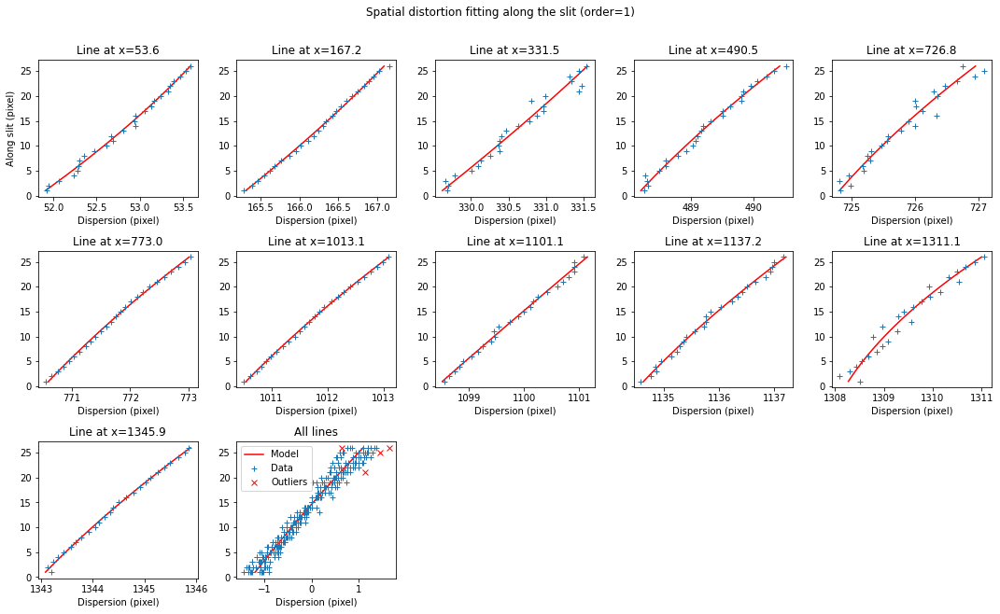

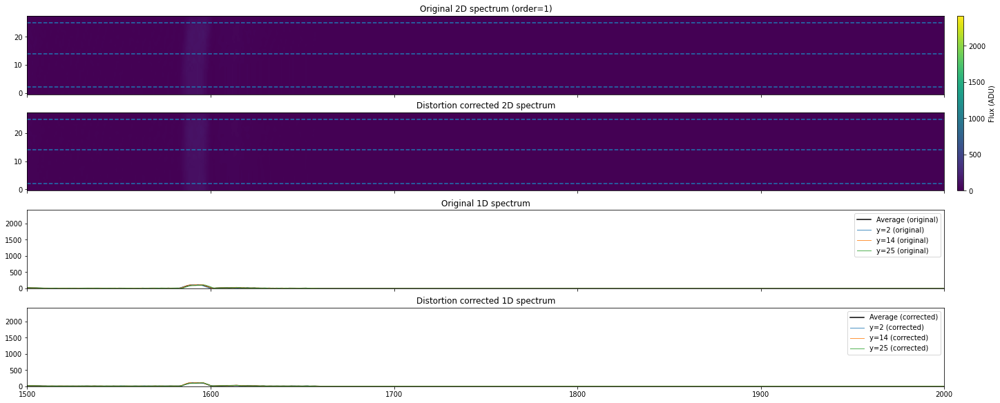

Working on order=2...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<53.32)


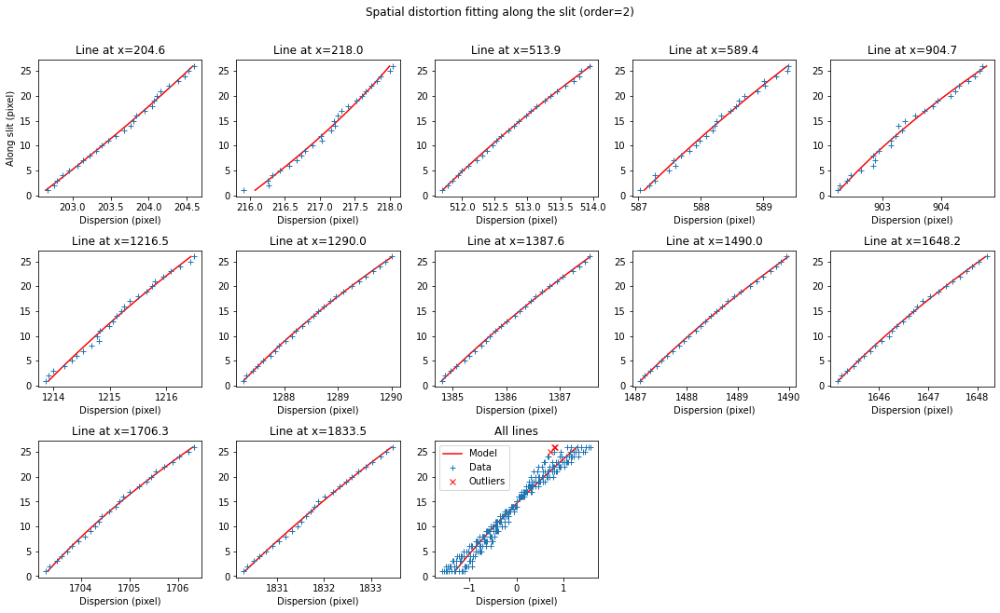

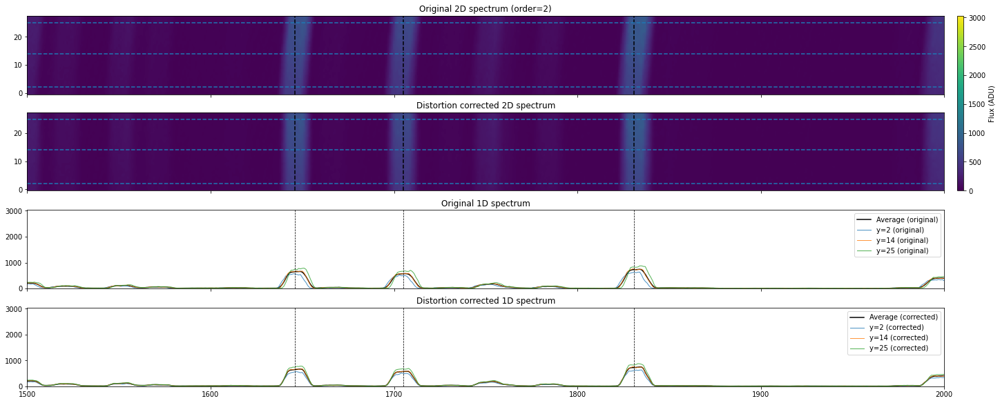

Working on order=3...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<69.77)


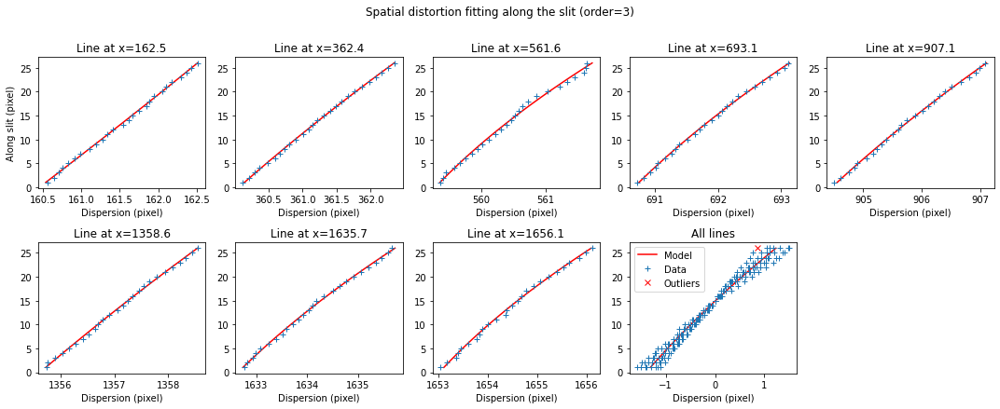

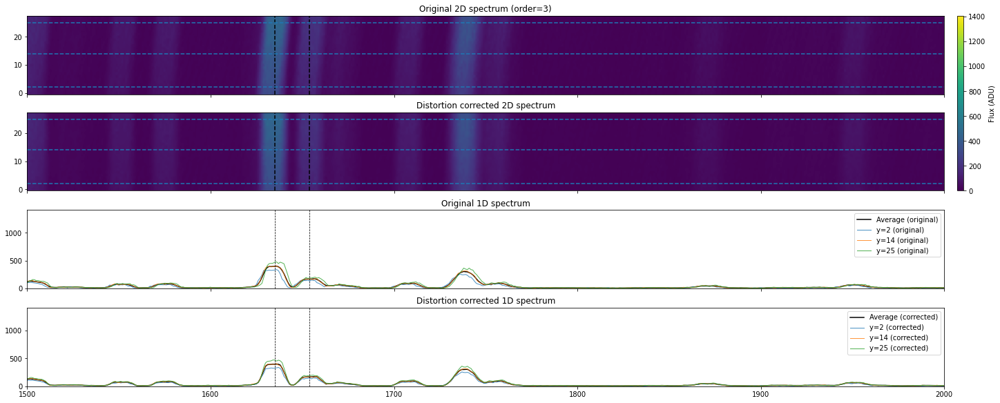

Working on order=4...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<87.15)


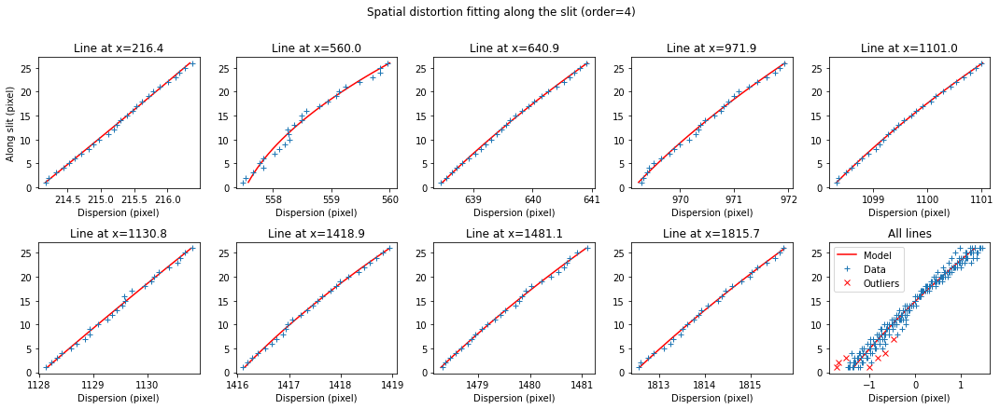

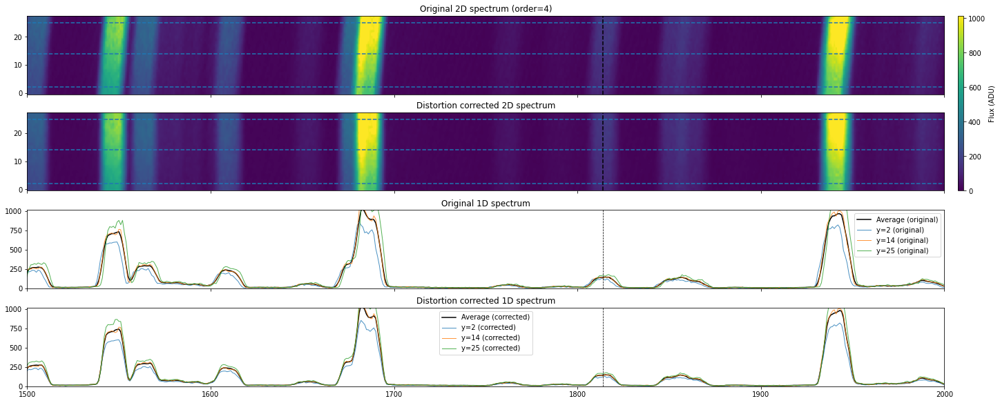

Working on order=5...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<97.02)


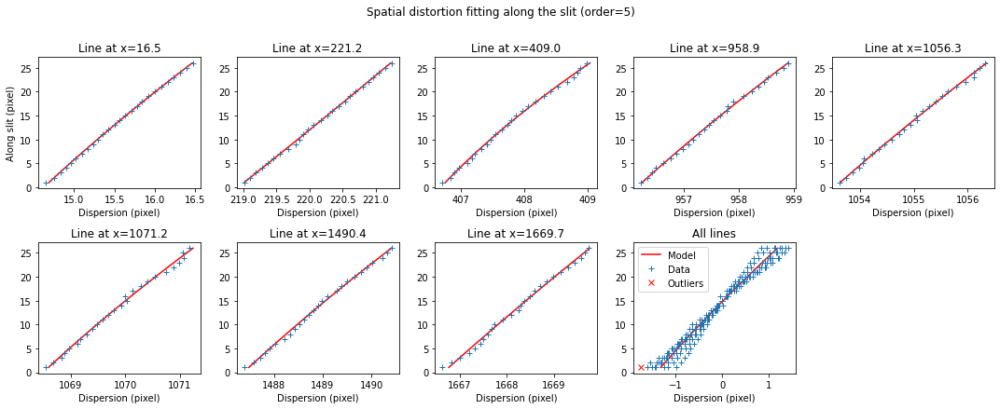

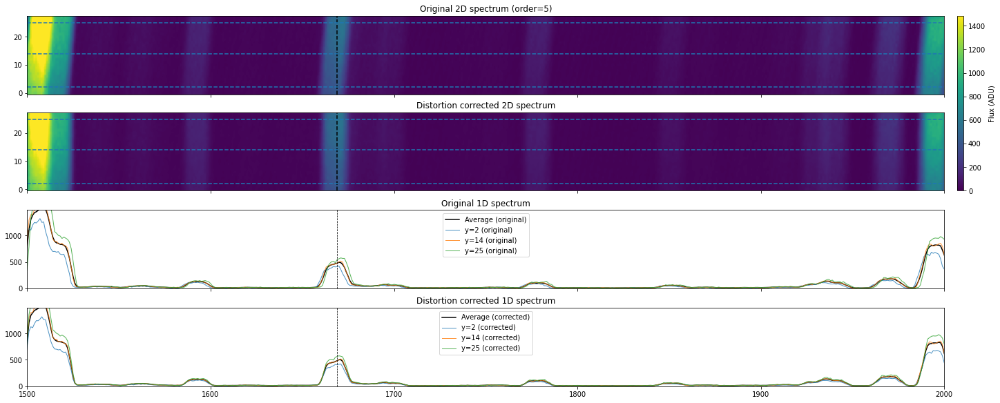

Working on order=6...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<125.52)


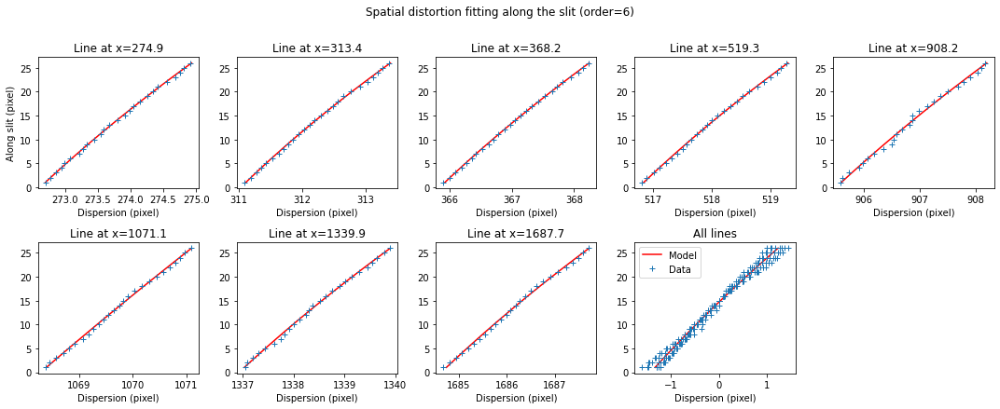

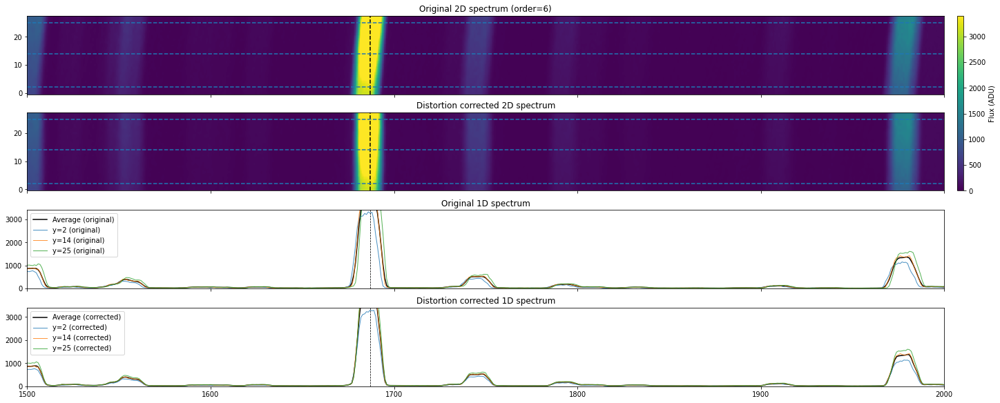

Working on order=7...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<177.92)


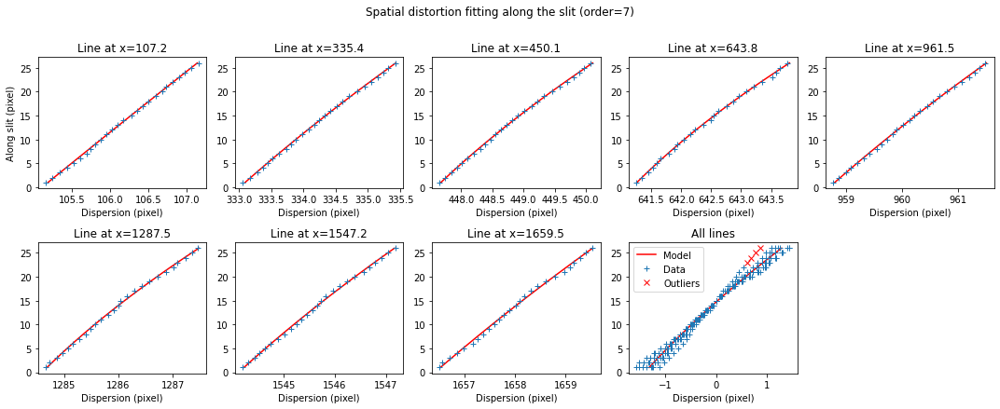

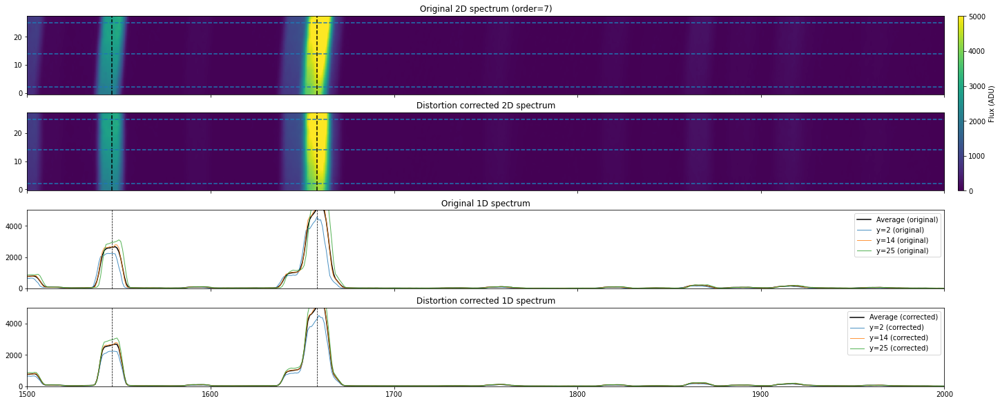

Working on order=8...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<157.36)


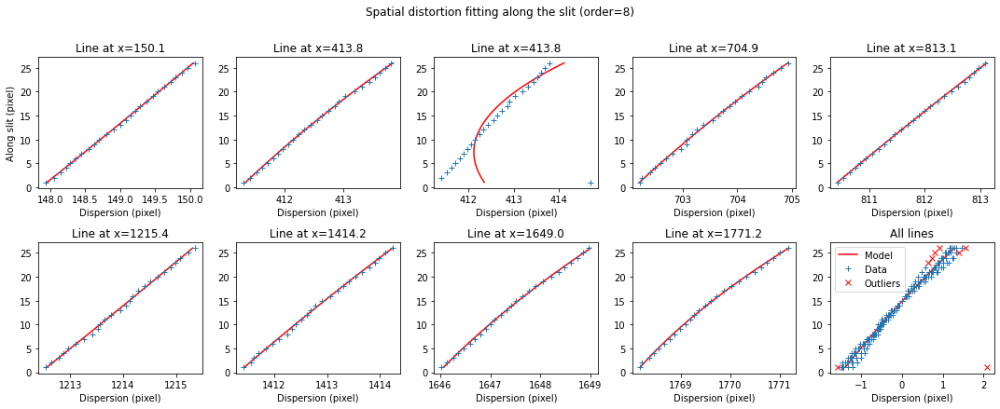

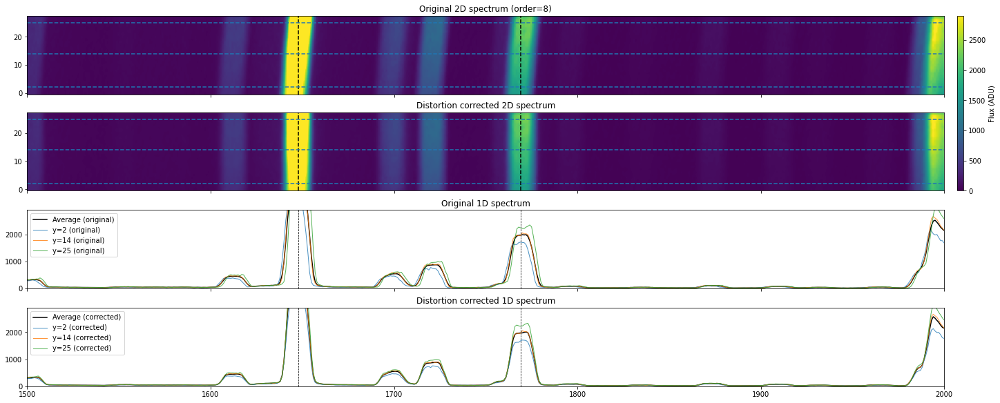

Working on order=9...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<222.37)


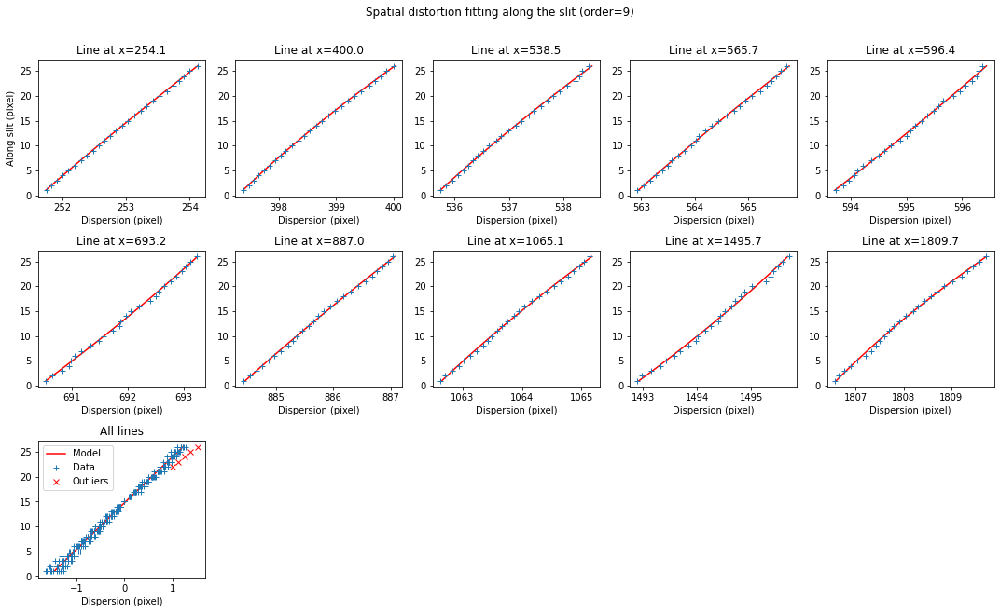

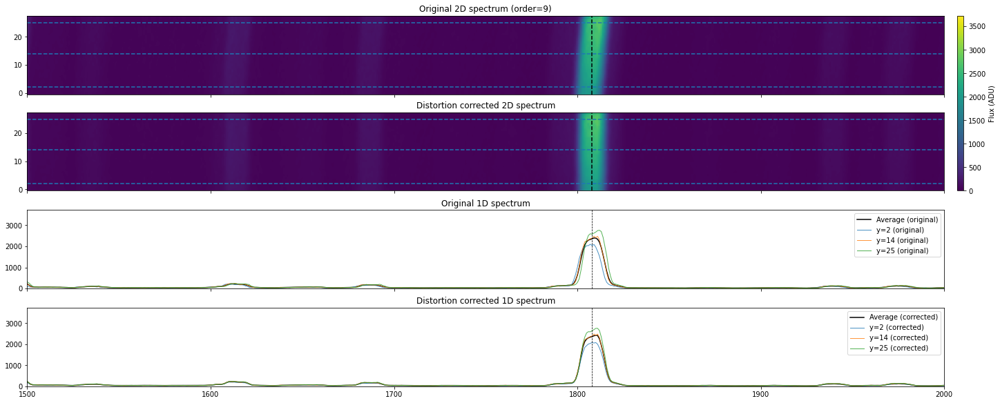

Working on order=10...
Excluding 1 saturated measurements (>500000.0)
Excluding 30 measurements below 5.0-sigma (<196.21)


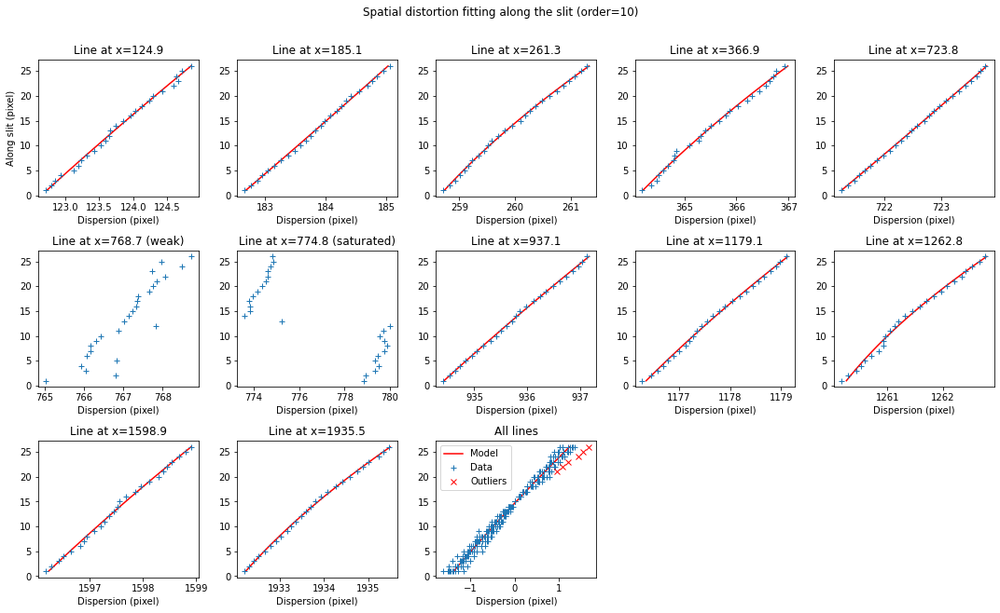

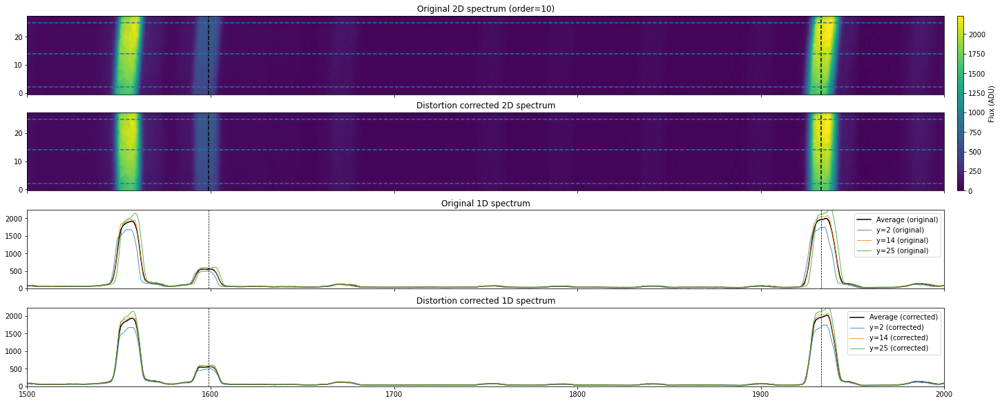

Working on order=11...
Fit failed near x=770
Excluding 1 saturated measurements (>500000.0)
Excluding 25 measurements below 5.0-sigma (<203.11)


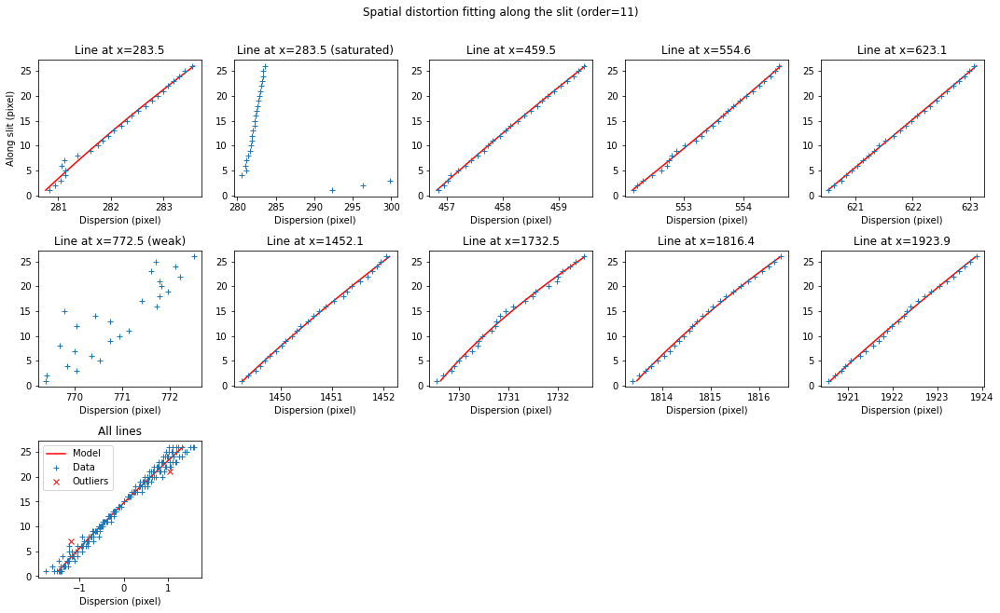

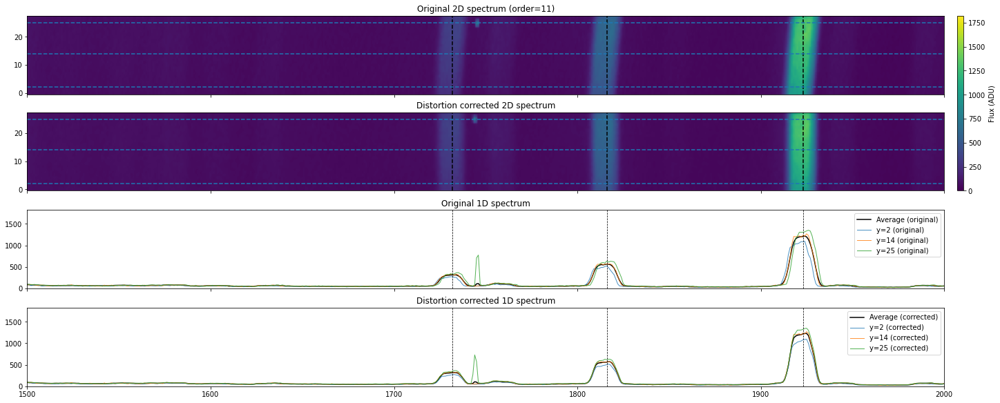

Working on order=12...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<227.44)


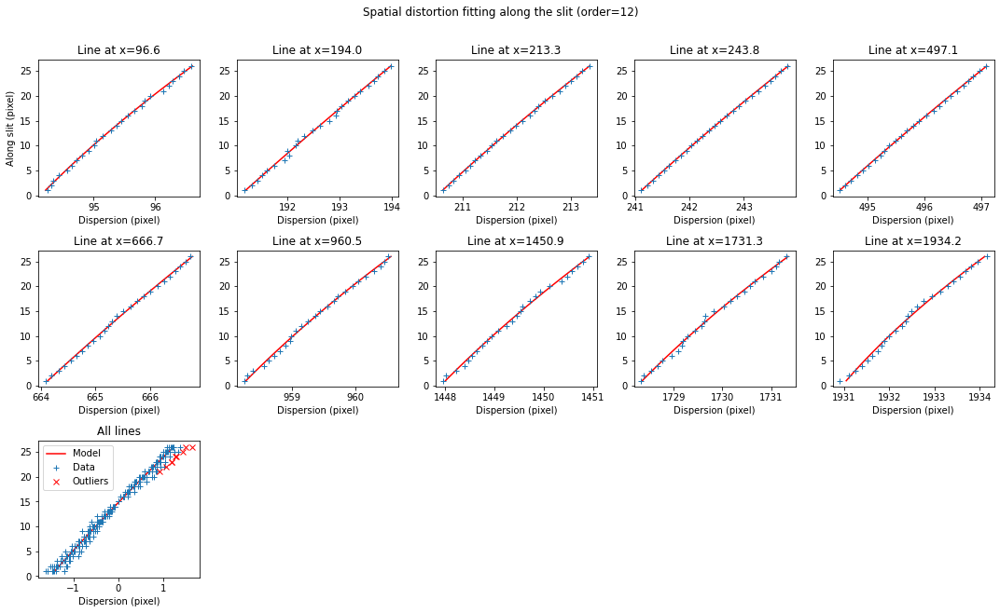

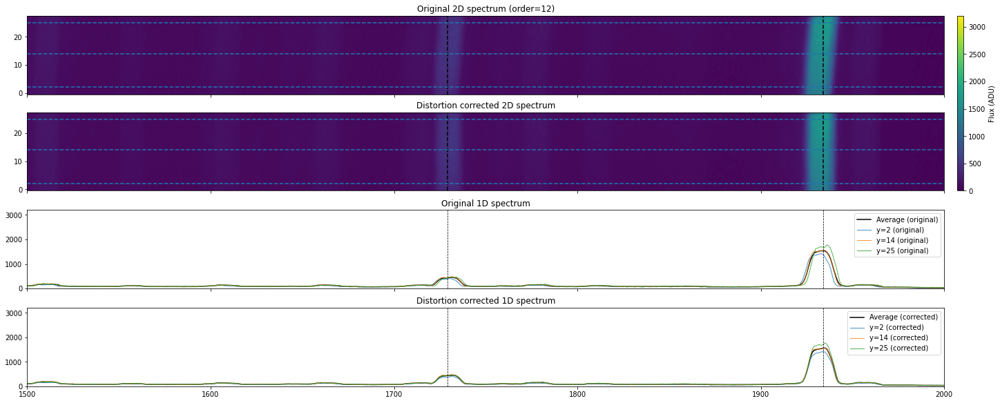

Working on order=13...
Excluding 0 saturated measurements (>500000.0)
Excluding 52 measurements below 5.0-sigma (<301.71)


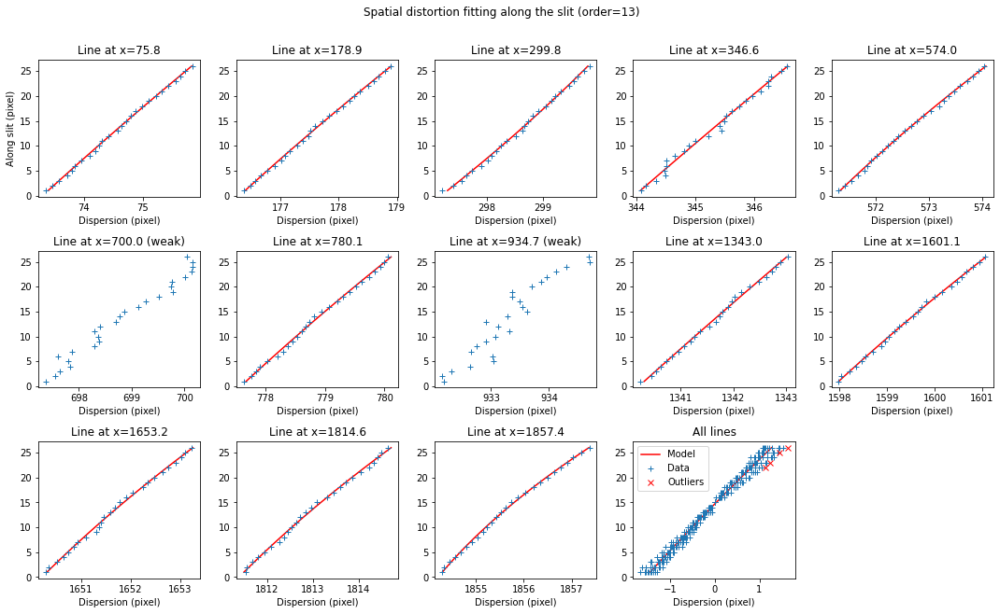

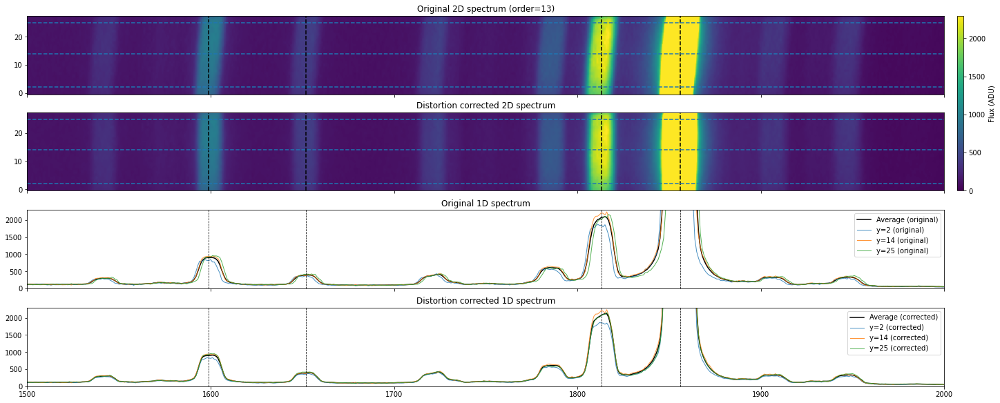

Working on order=14...
Excluding 0 saturated measurements (>500000.0)
Excluding 51 measurements below 5.0-sigma (<291.67)


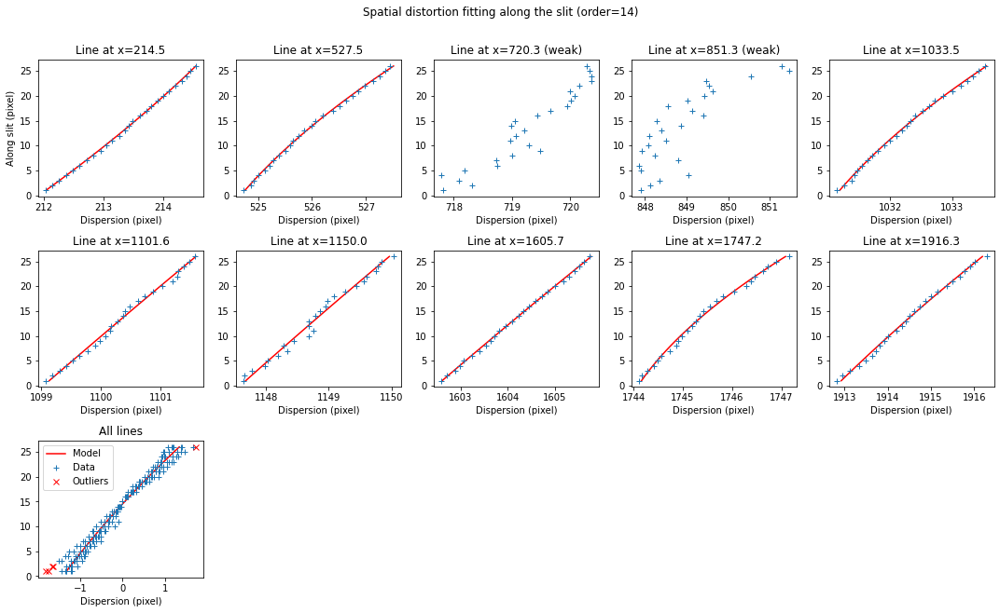

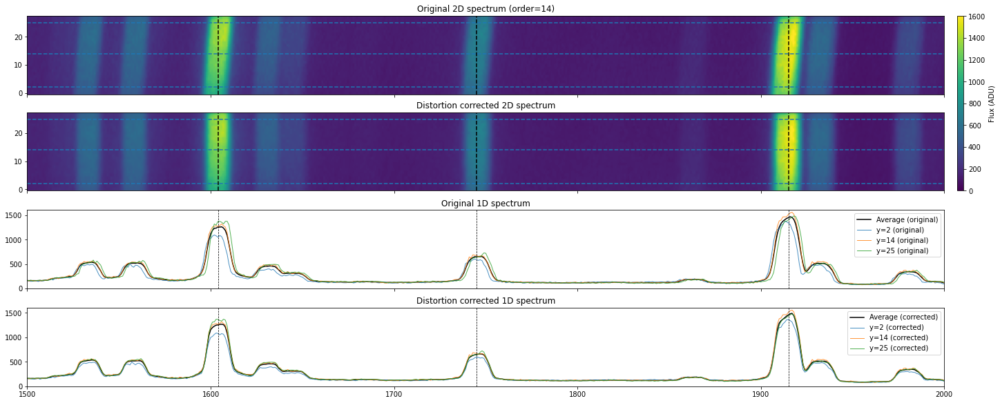

Working on order=15...
Excluding 0 saturated measurements (>500000.0)
Excluding 55 measurements below 5.0-sigma (<352.41)


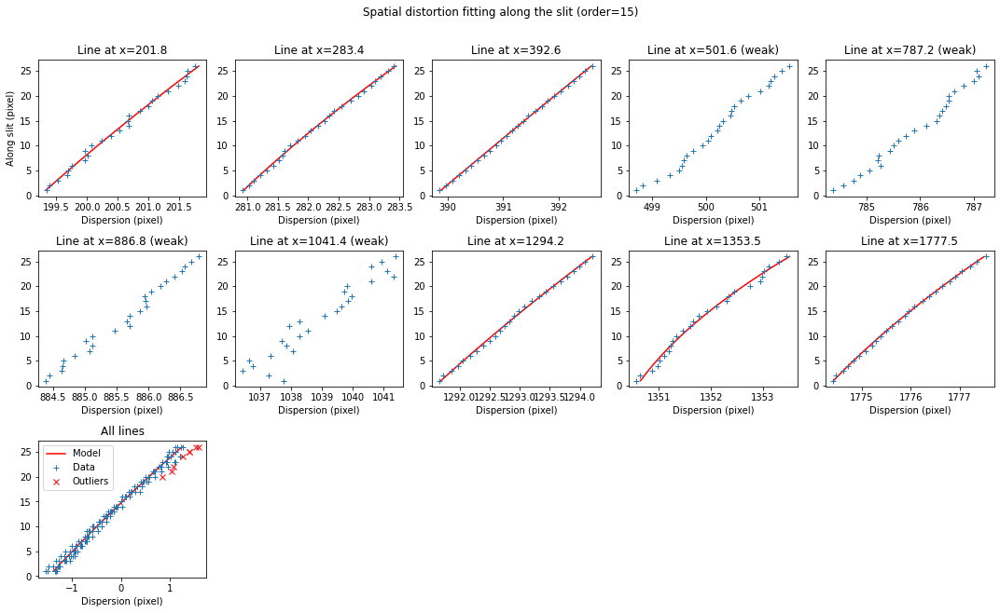

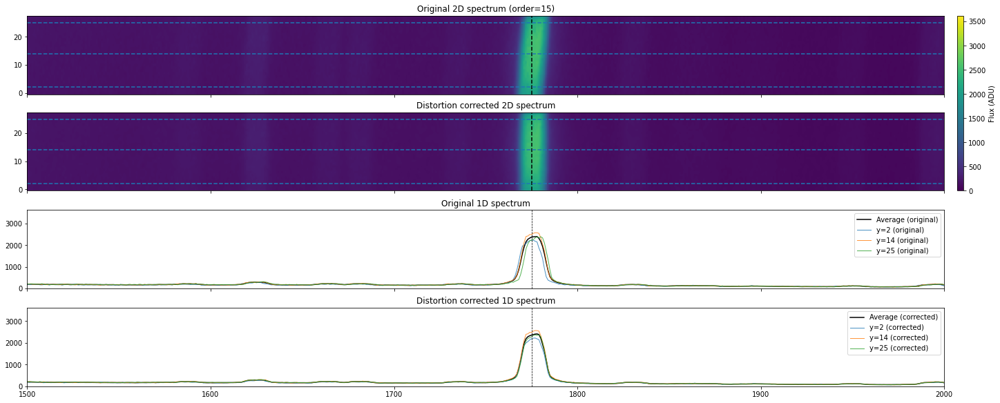

Working on order=16...
Excluding 0 saturated measurements (>500000.0)
Excluding 78 measurements below 5.0-sigma (<399.69)


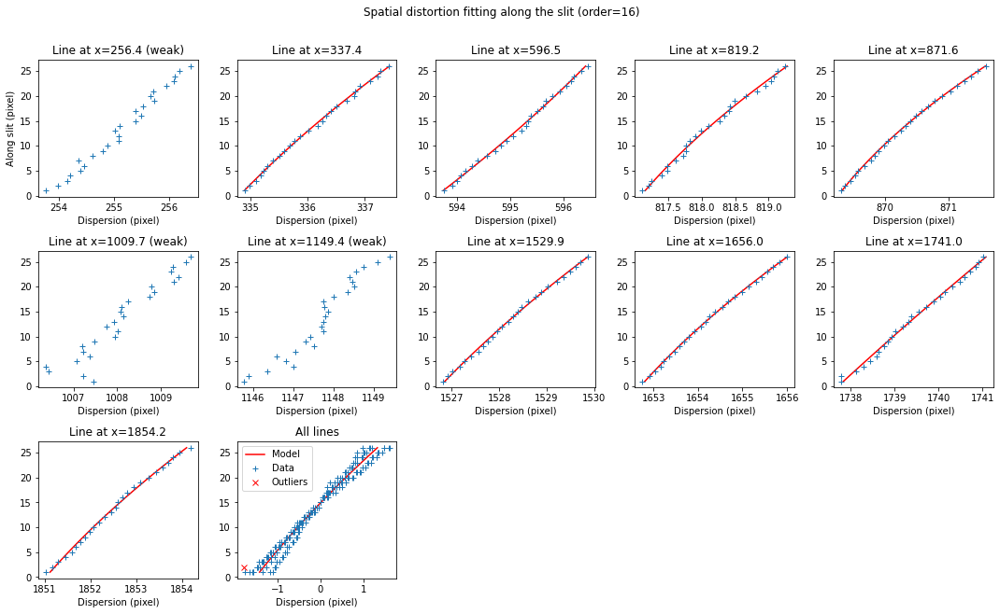

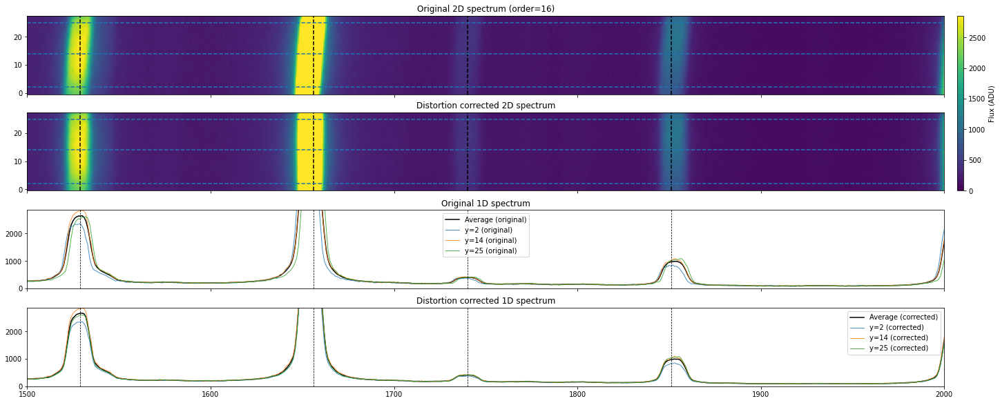

Working on order=17...
Excluding 0 saturated measurements (>500000.0)
Excluding 100 measurements below 5.0-sigma (<332.84)


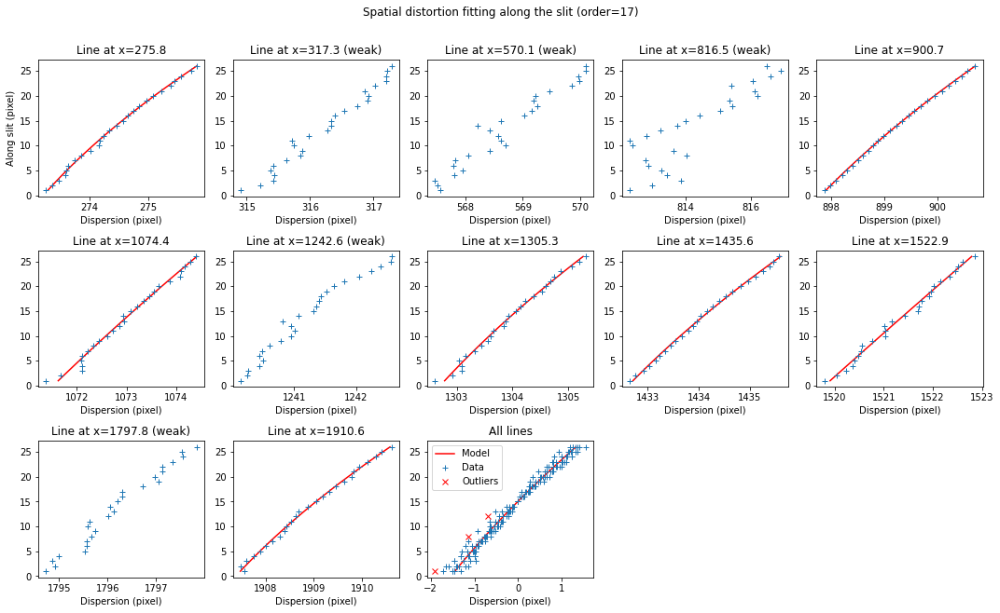

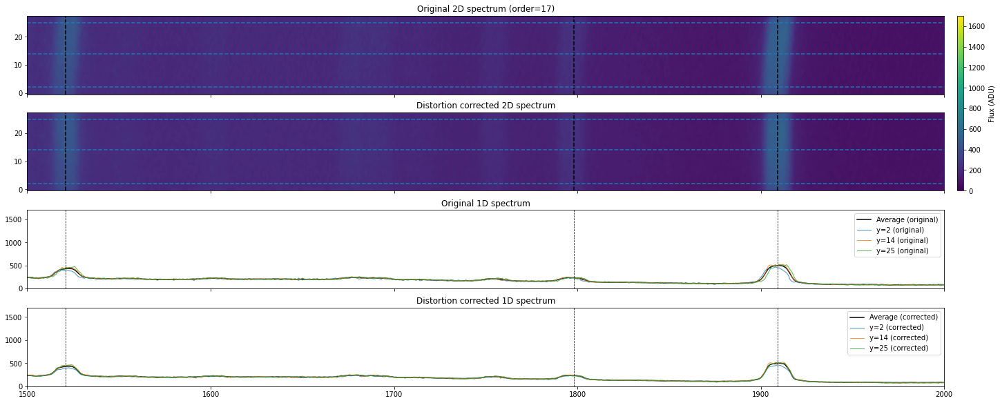

Working on order=18...
Excluding 0 saturated measurements (>500000.0)
Excluding 91 measurements below 5.0-sigma (<239.00)


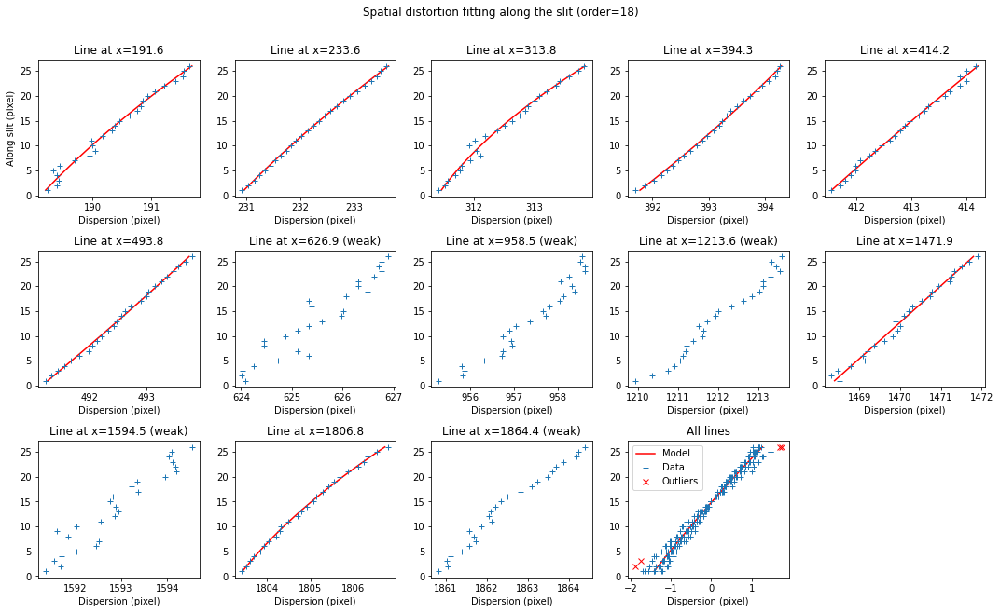

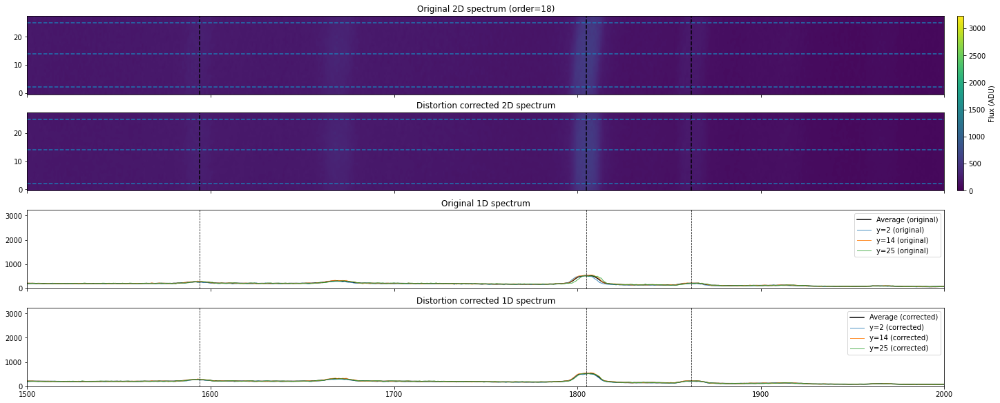

Working on order=19...
Fit failed near x=256
Fit failed near x=256
Fit failed near x=256
Excluding 1 saturated measurements (>500000.0)
Excluding 22 measurements below 5.0-sigma (<248.16)


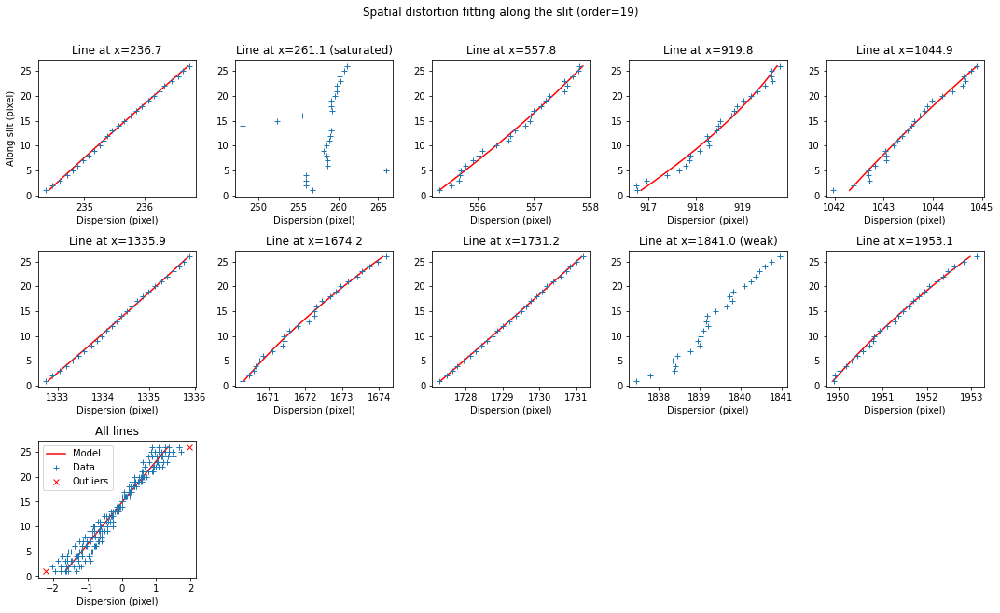

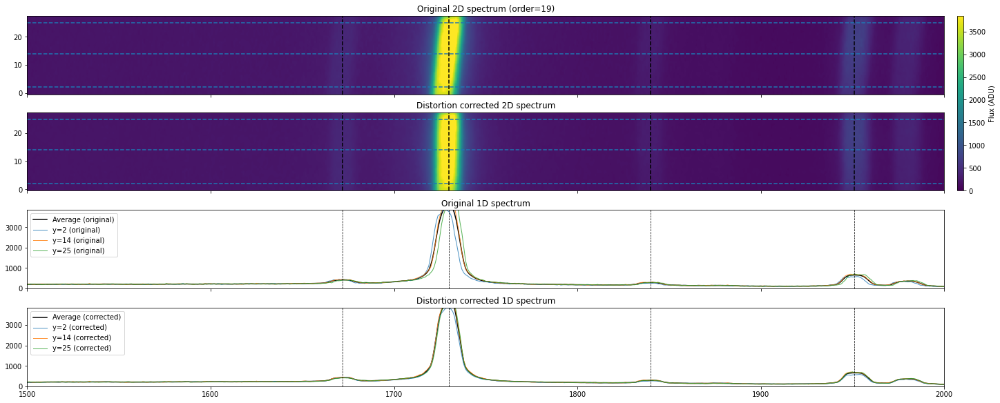

Working on order=20...
Excluding 4 saturated measurements (>500000.0)
Excluding 50 measurements below 5.0-sigma (<222.12)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


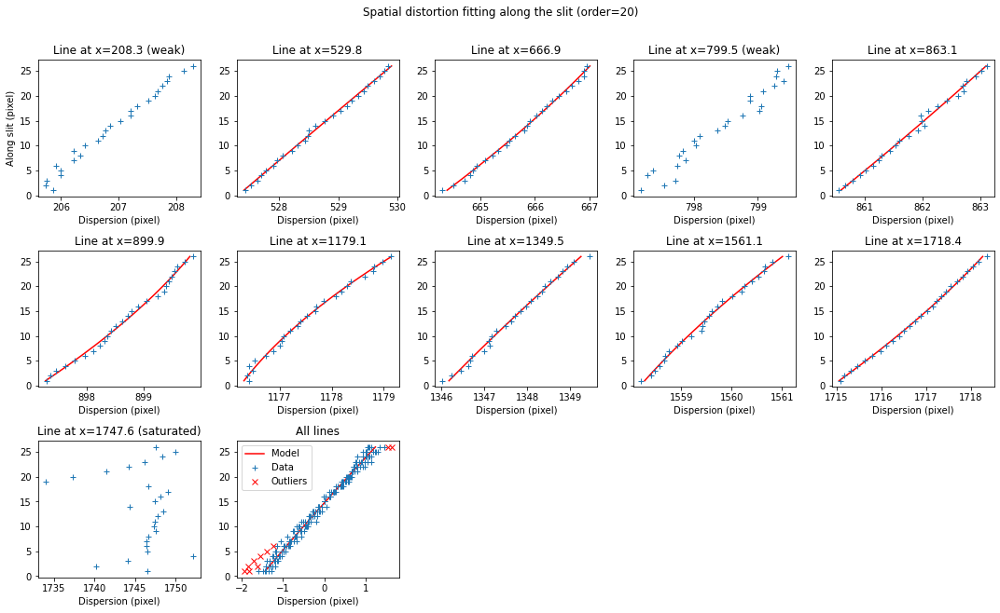

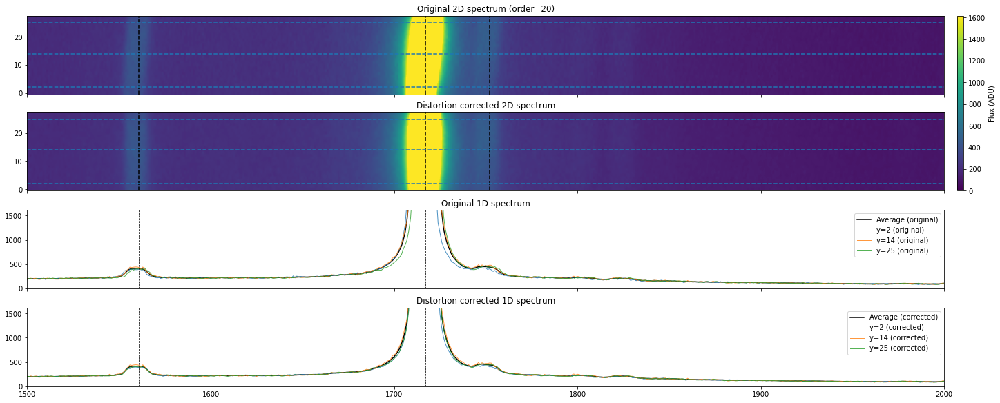

Working on order=21...
Fit failed near x=1604
Fit failed near x=1645

C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)



Excluding 0 saturated measurements (>500000.0)
Excluding 108 measurements below 5.0-sigma (<251.47)


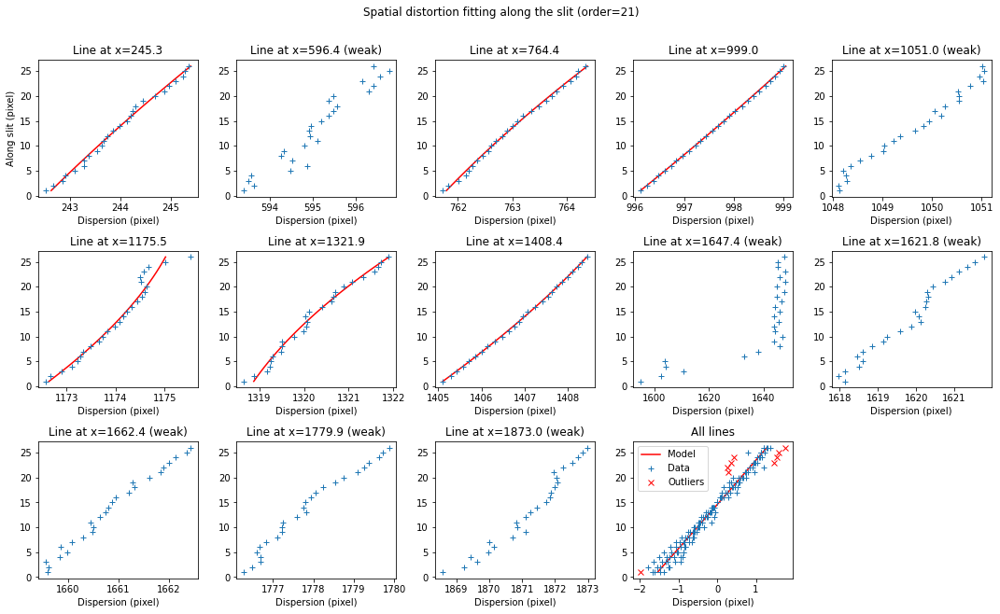

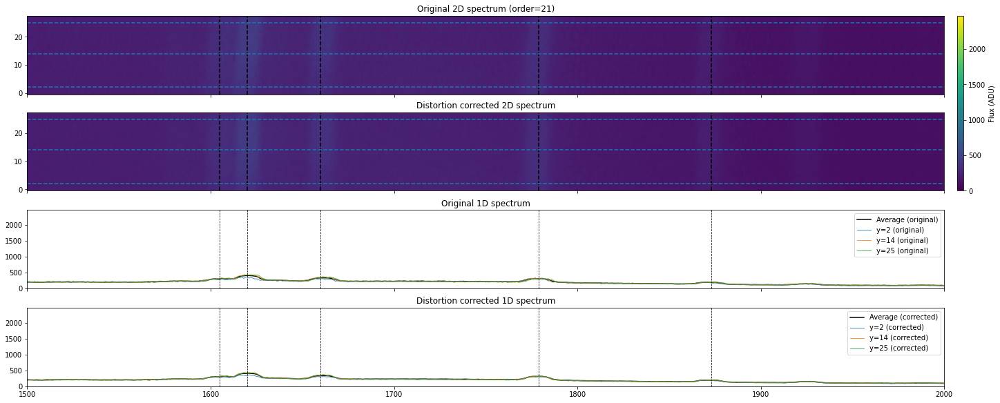

Working on order=22...
Excluding 0 saturated measurements (>500000.0)
Excluding 52 measurements below 5.0-sigma (<311.92)


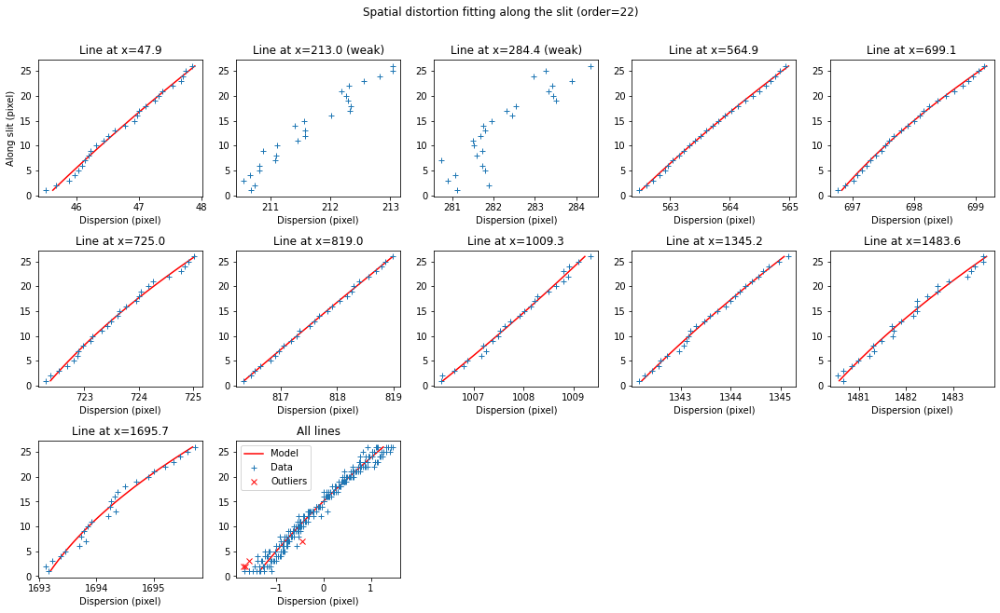

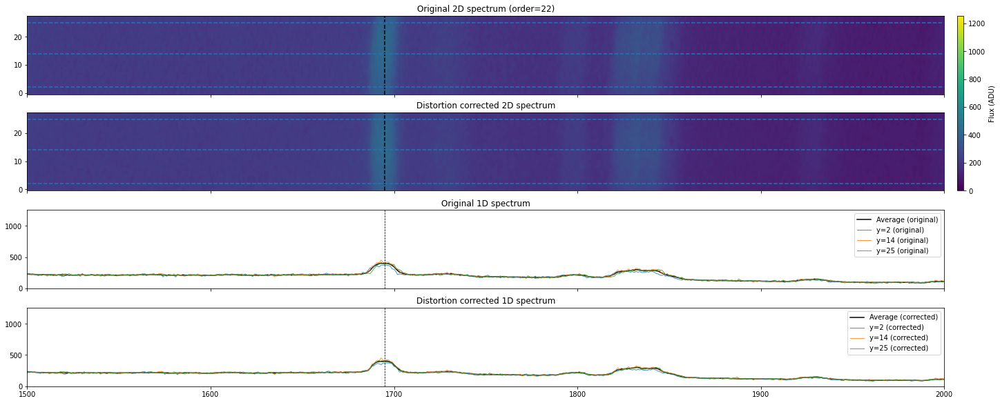

Working on order=23...
Excluding 0 saturated measurements (>500000.0)
Excluding 109 measurements below 5.0-sigma (<319.85)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


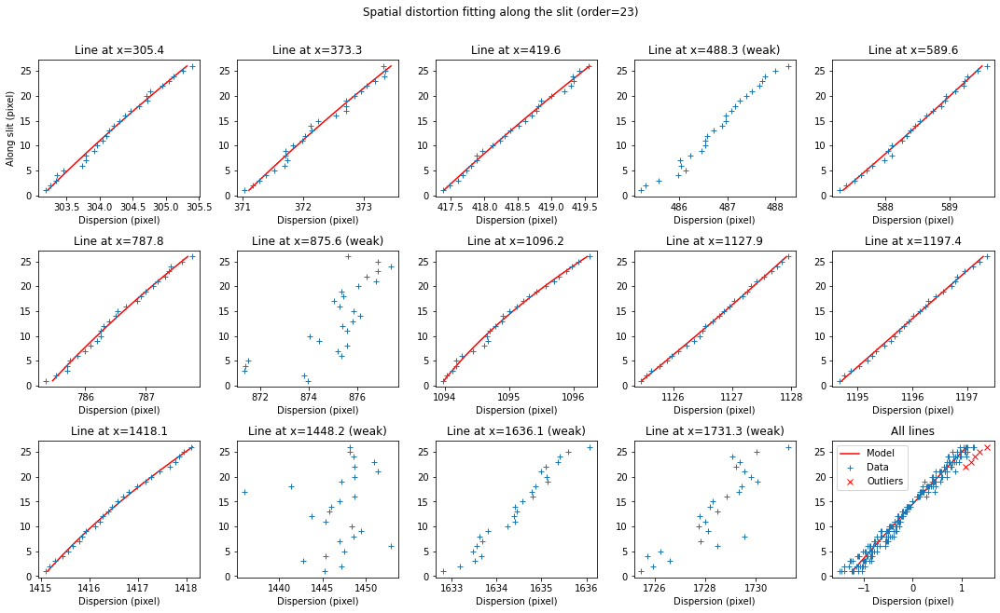

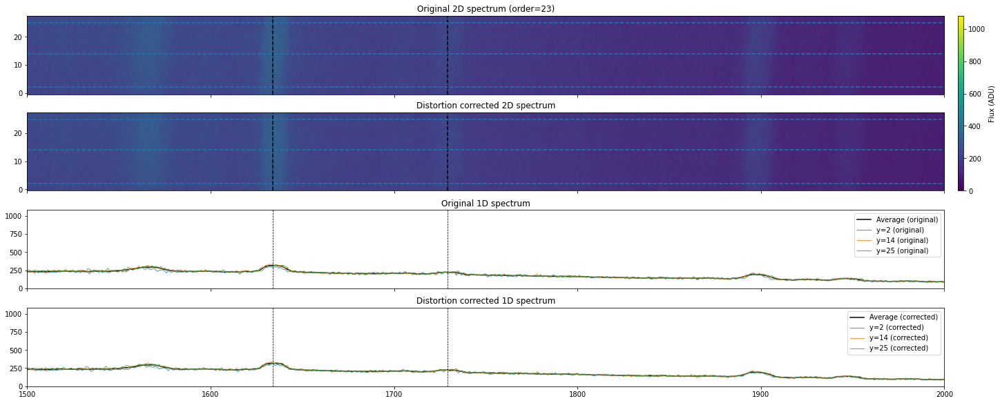

Working on order=24...
Excluding 0 saturated measurements (>500000.0)
Excluding 86 measurements below 5.0-sigma (<413.78)


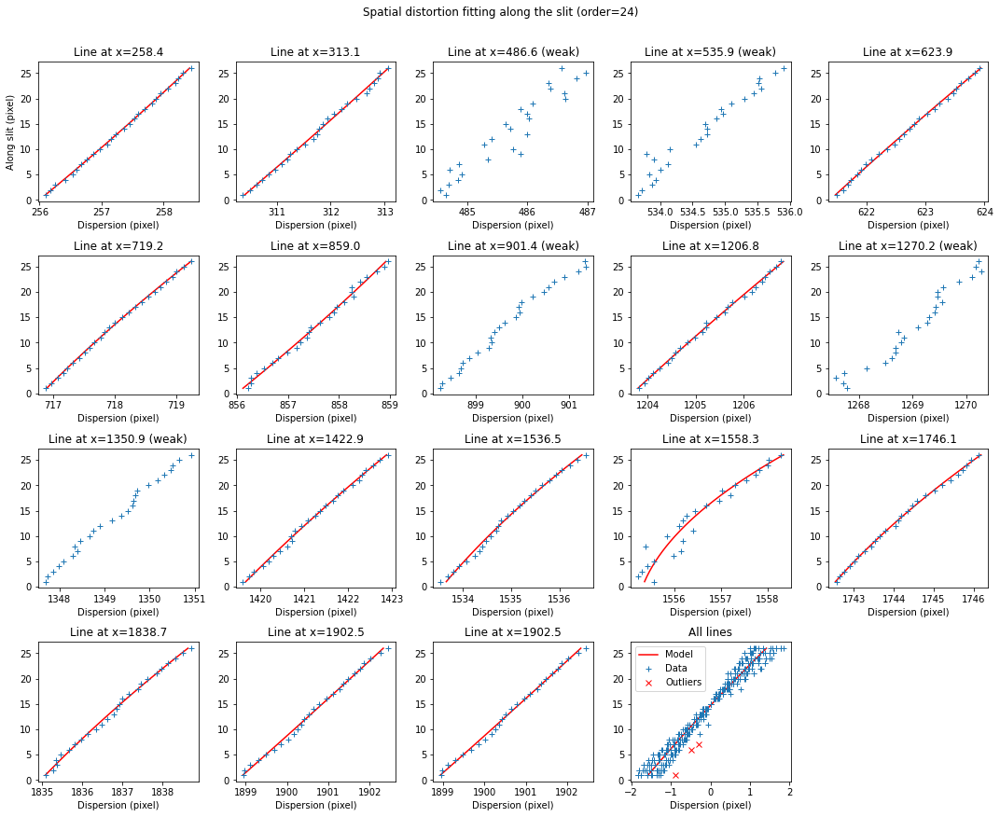

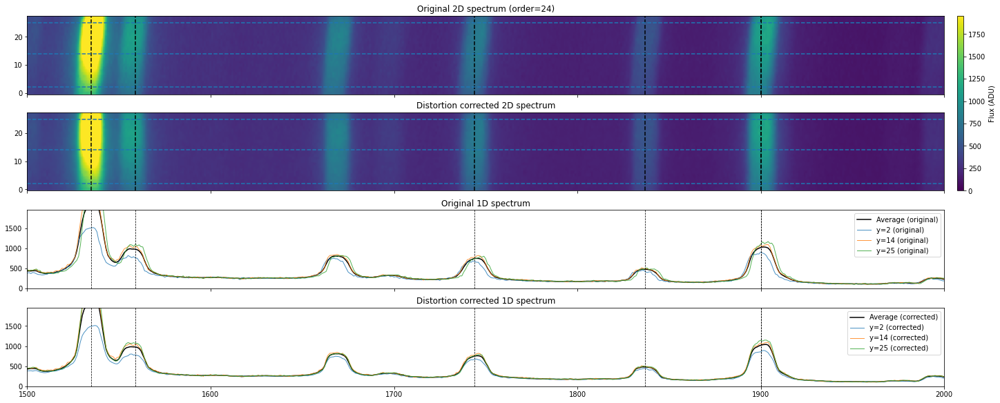

Working on order=25...
Fit failed near x=1083
Excluding 1 saturated measurements (>500000.0)
Excluding 125 measurements below 5.0-sigma (<511.51)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


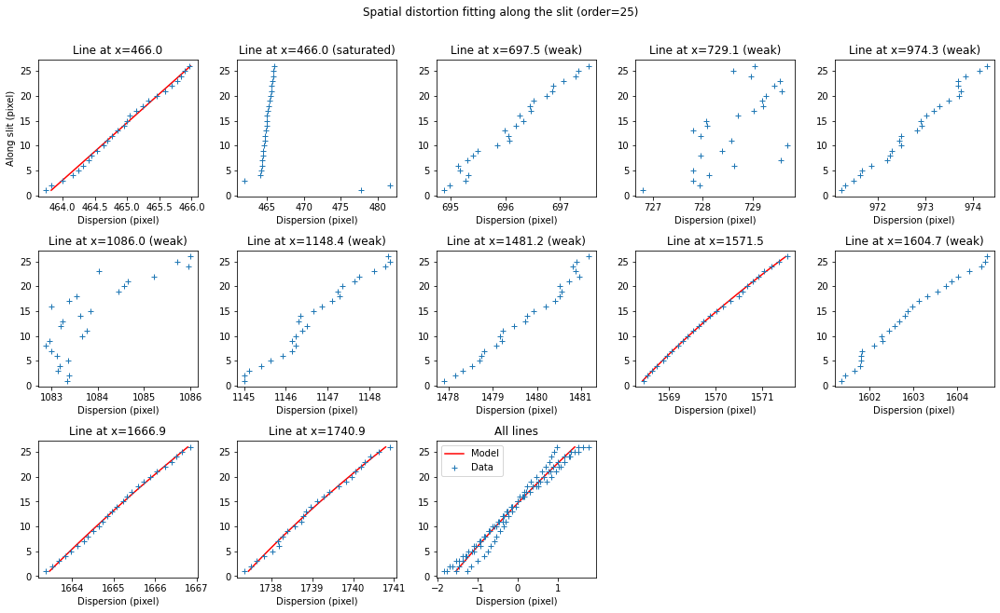

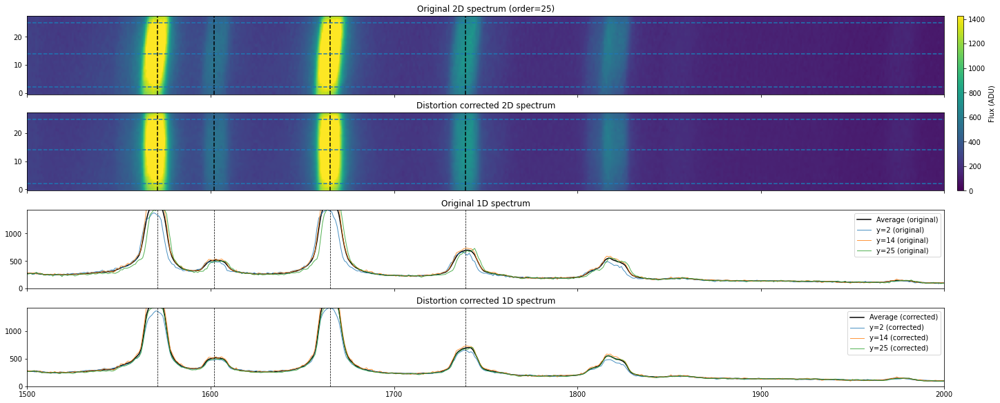

Working on order=26...
Excluding 0 saturated measurements (>500000.0)
Excluding 27 measurements below 5.0-sigma (<431.82)


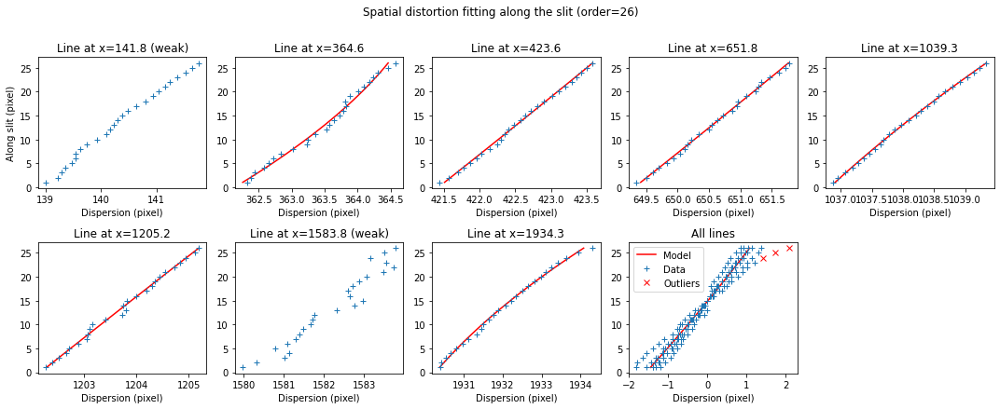

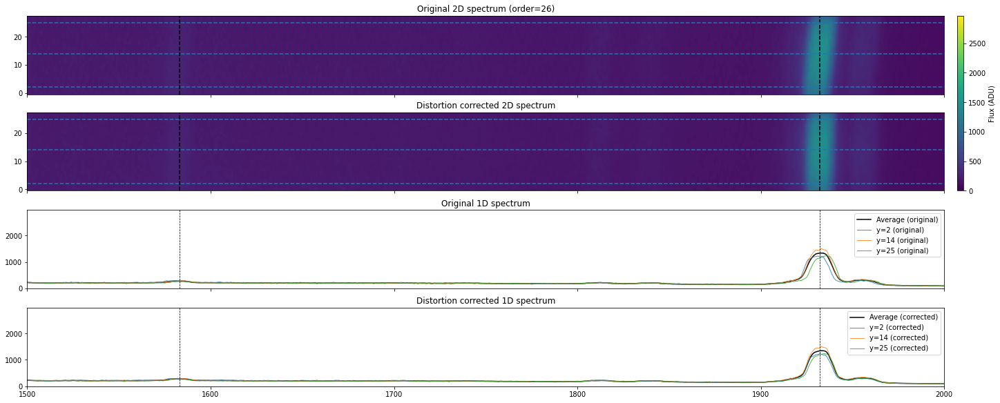

Working on order=27...
Excluding 0 saturated measurements (>500000.0)
Excluding 78 measurements below 5.0-sigma (<459.36)


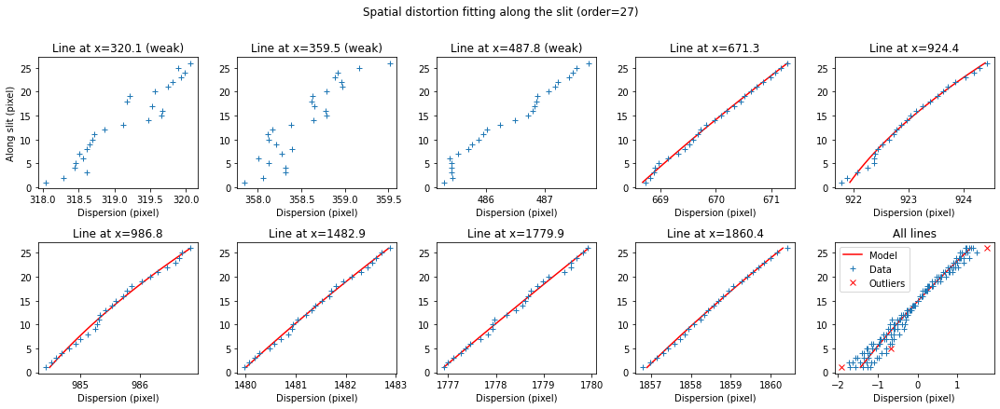

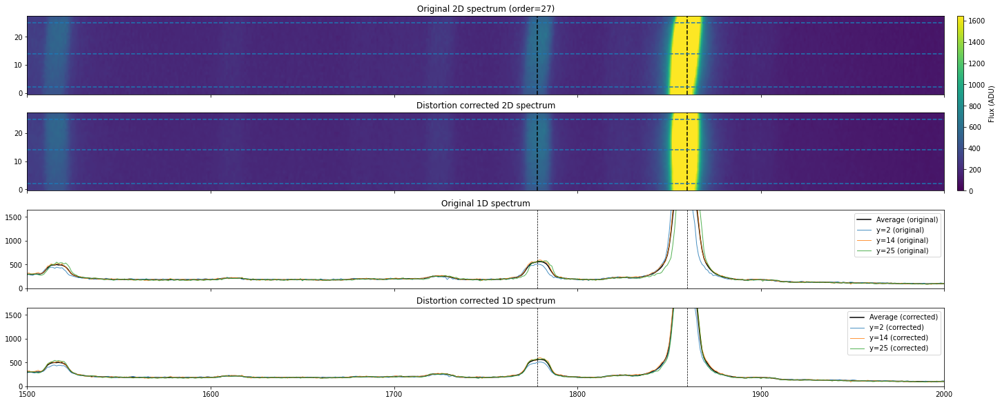

Working on order=28...


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


Excluding 50 saturated measurements (>500000.0)
Excluding 69 measurements below 5.0-sigma (<361.02)


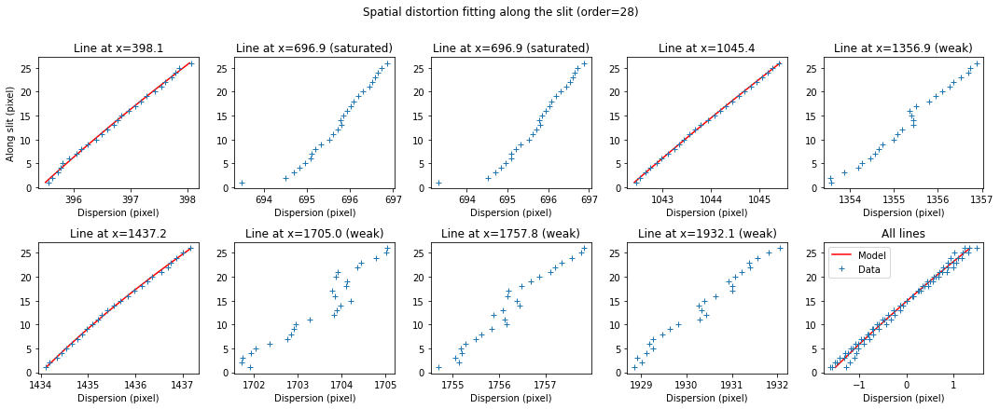

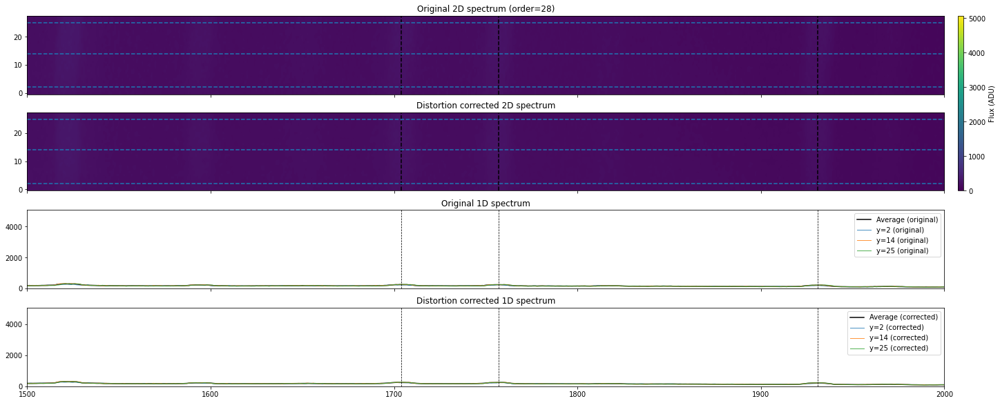

Working on order=29...
Fit failed near x=740
Excluding 0 saturated measurements (>500000.0)
Excluding 73 measurements below 5.0-sigma (<385.93)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


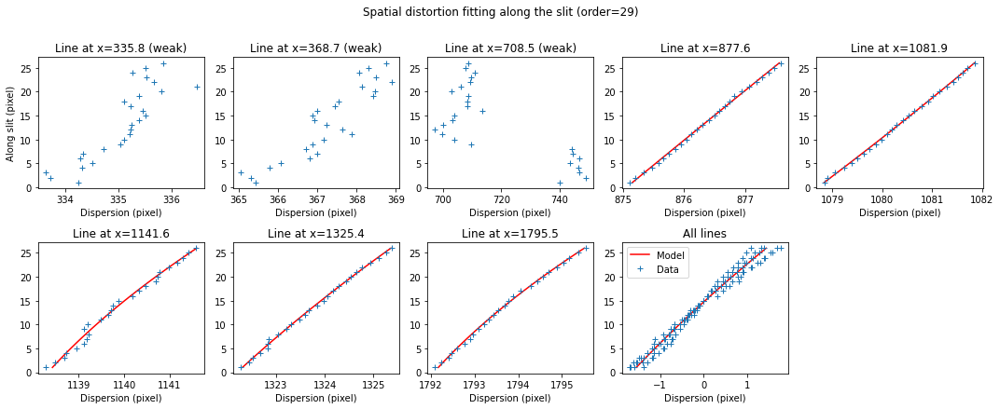

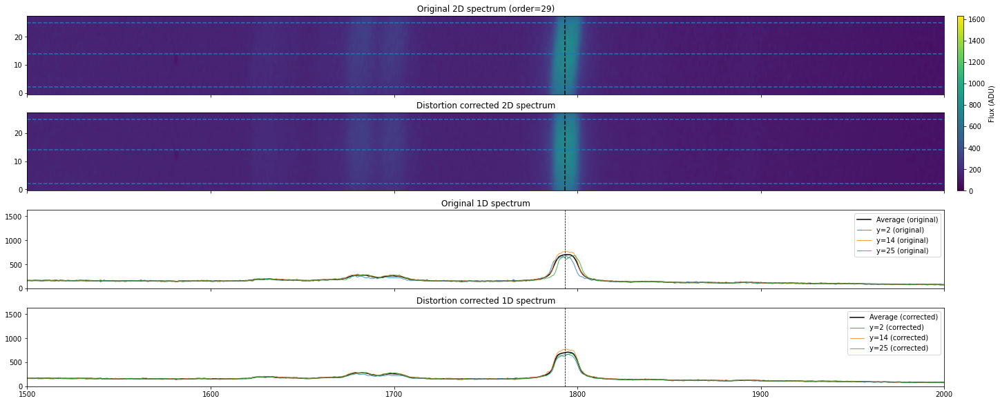

Working on order=30...
Excluding 10 saturated measurements (>500000.0)
Excluding 179 measurements below 5.0-sigma (<409.97)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


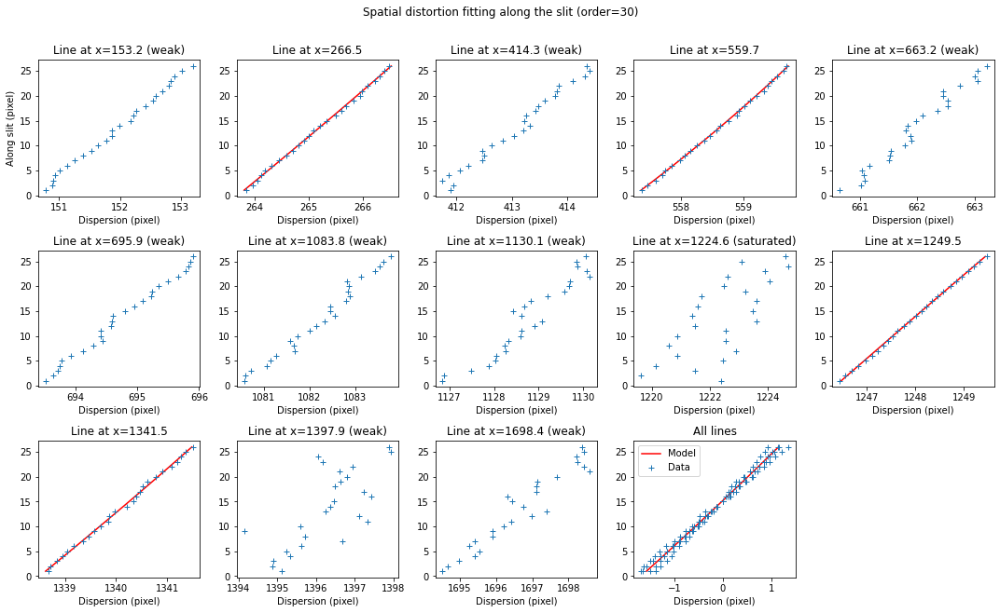

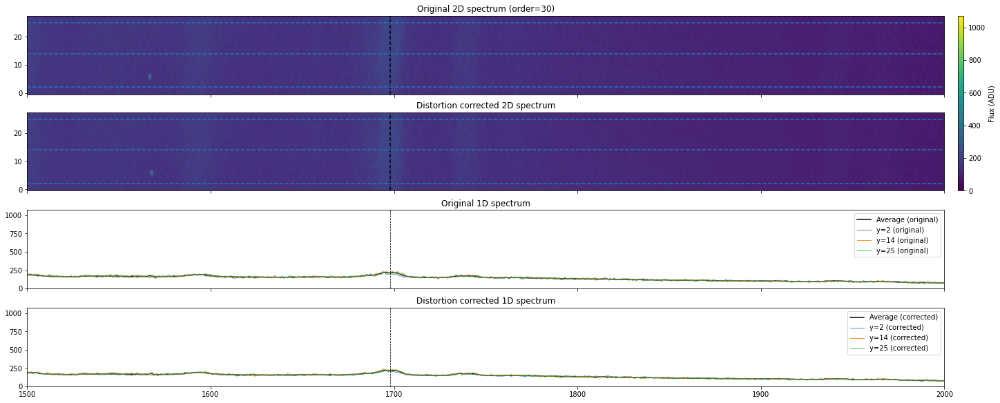

Working on order=31...


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


Excluding 24 saturated measurements (>500000.0)
Excluding 123 measurements below 5.0-sigma (<400.40)


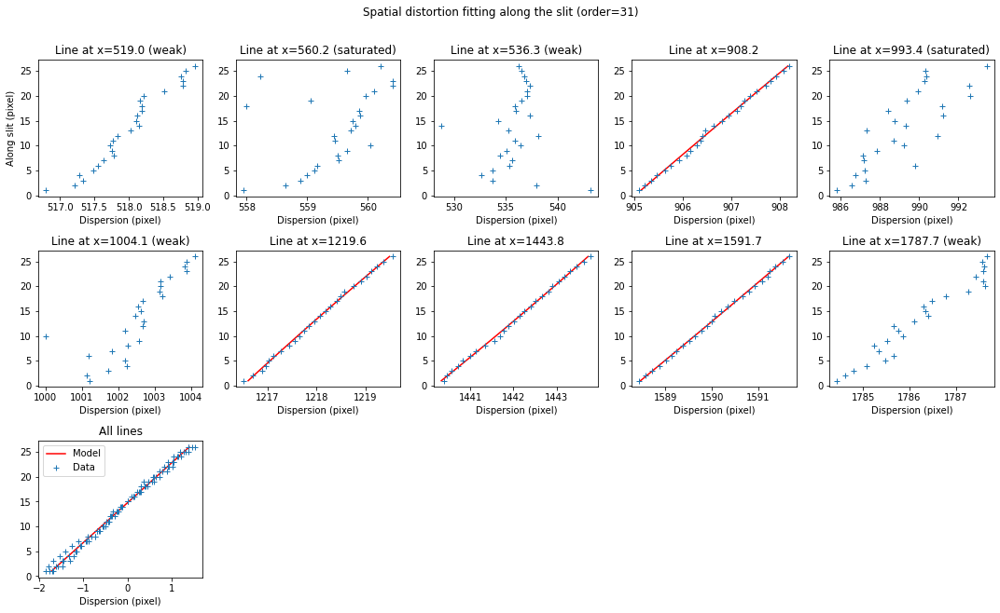

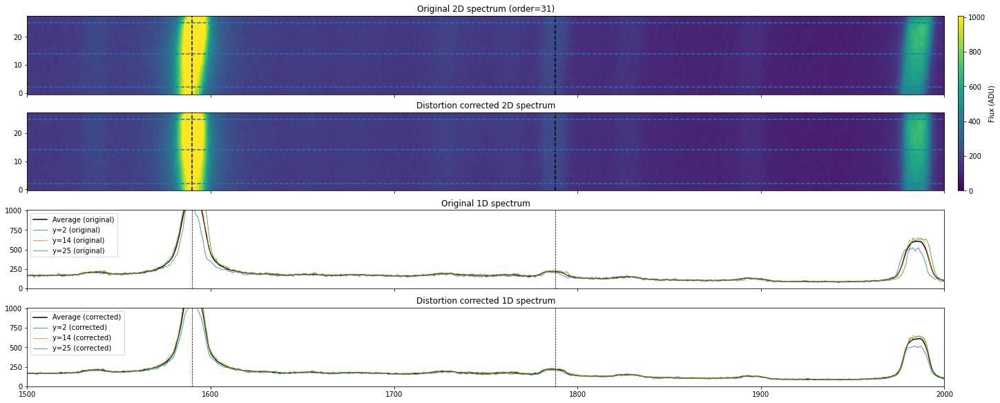

Working on order=32...
Excluding 4 saturated measurements (>500000.0)
Excluding 90 measurements below 5.0-sigma (<282.35)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


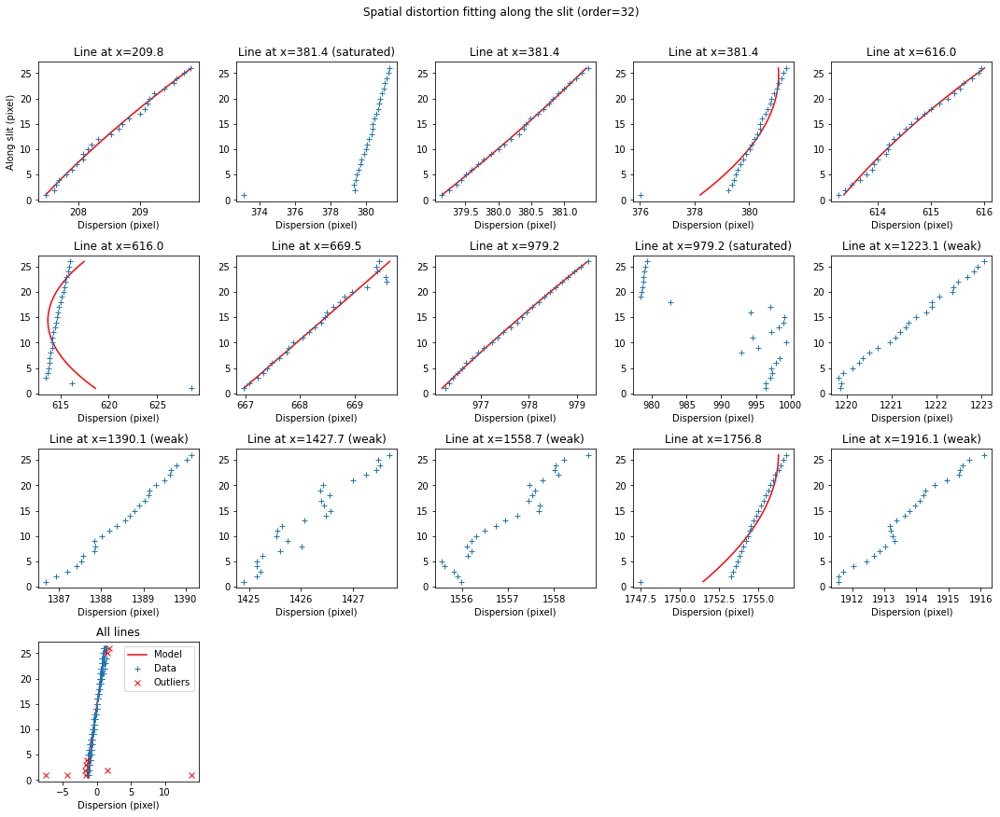

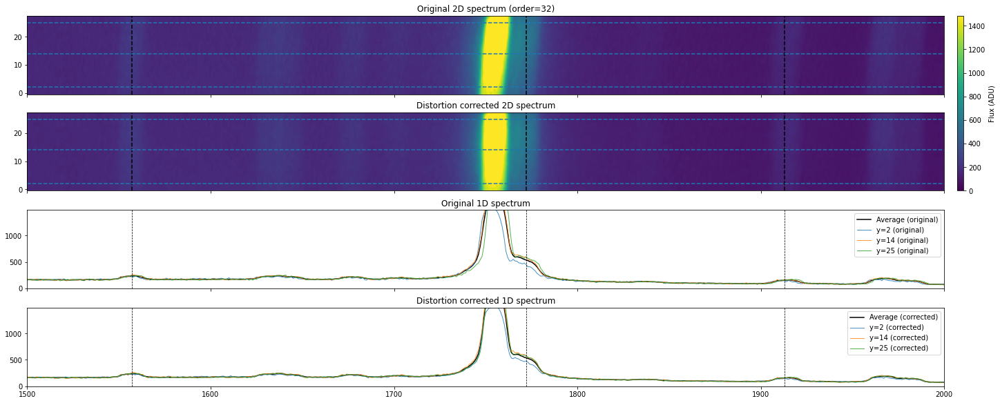

Working on order=33...
Excluding 6 saturated measurements (>500000.0)
Excluding 145 measurements below 5.0-sigma (<322.36)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


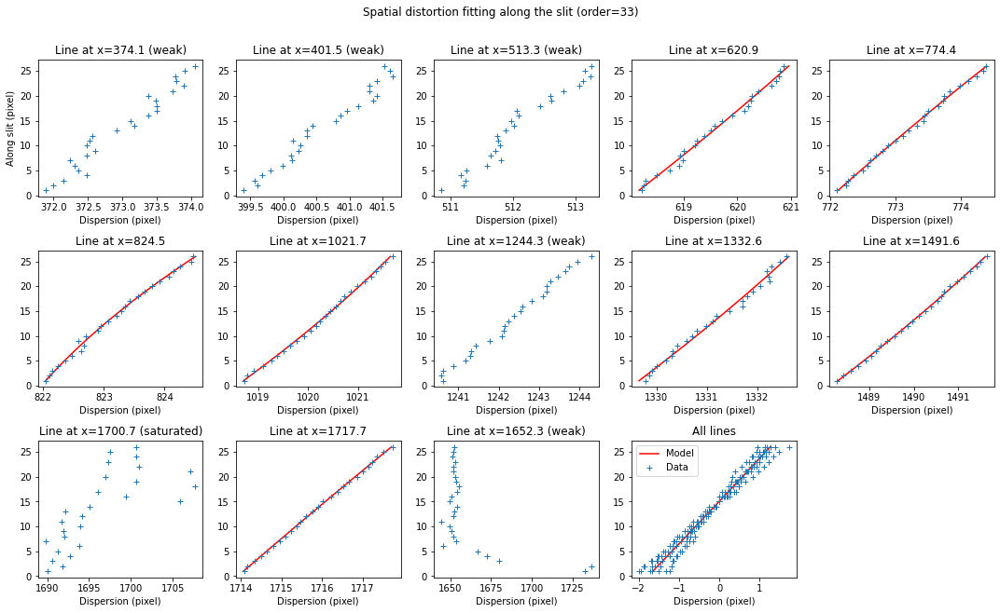

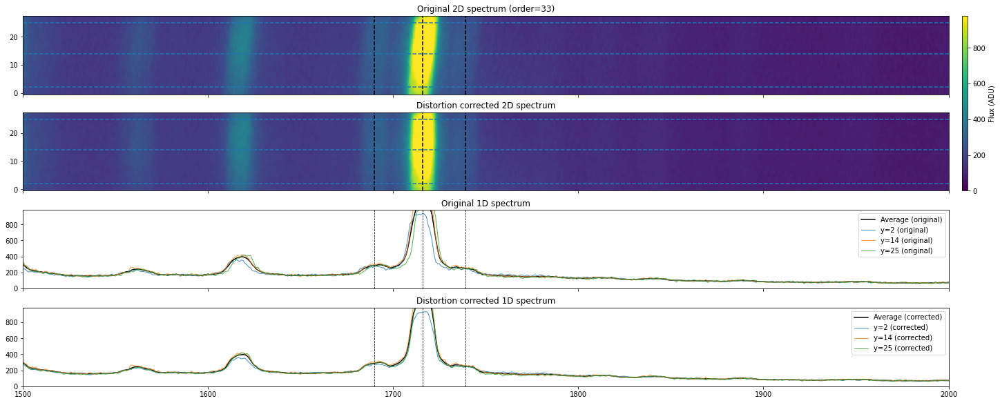

Working on order=34...
Fit failed near x=1302
Excluding 10 saturated measurements (>500000.0)
Excluding 118 measurements below 5.0-sigma (<256.72)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


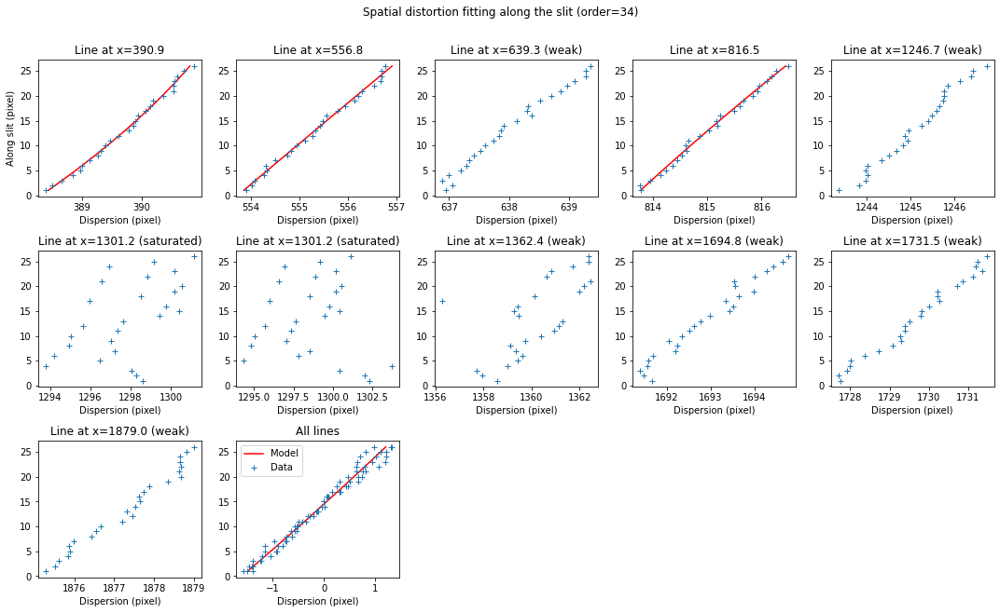

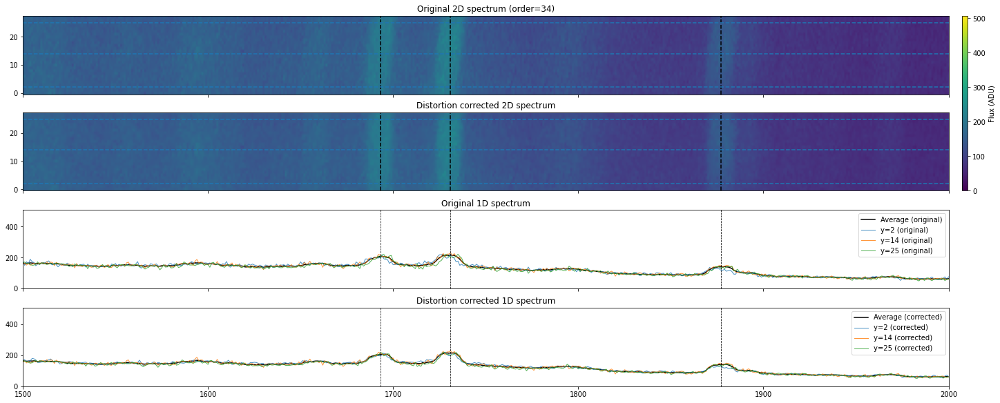

Working on order=35...
Excluding 0 saturated measurements (>500000.0)
Excluding 118 measurements below 5.0-sigma (<225.29)


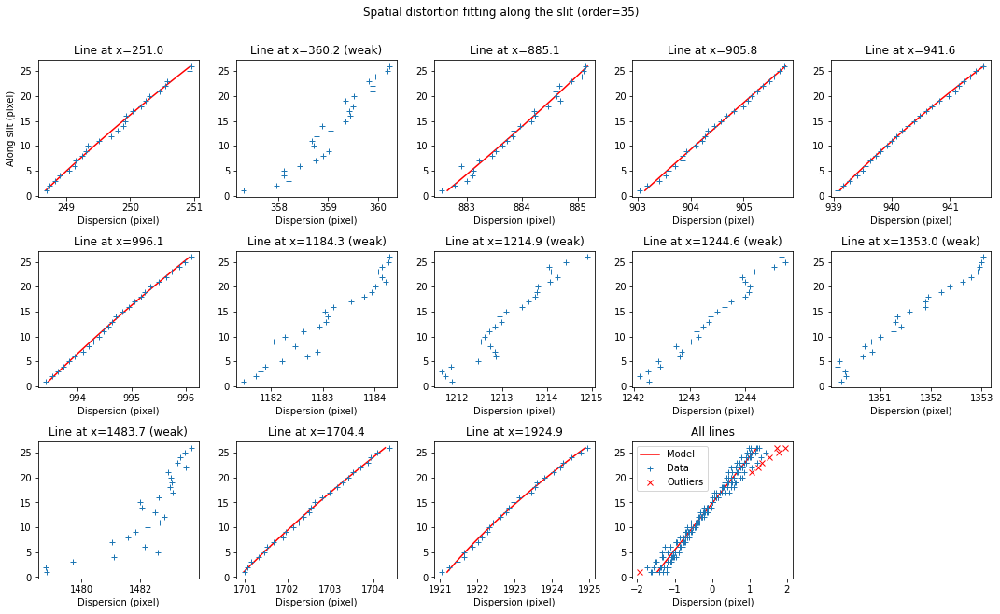

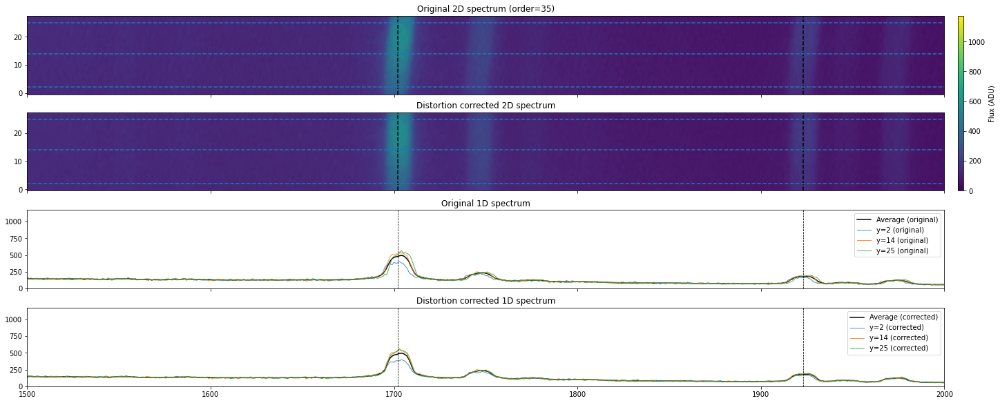

Working on order=36...
Excluding 1 saturated measurements (>500000.0)

C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)



Excluding 97 measurements below 5.0-sigma (<261.92)


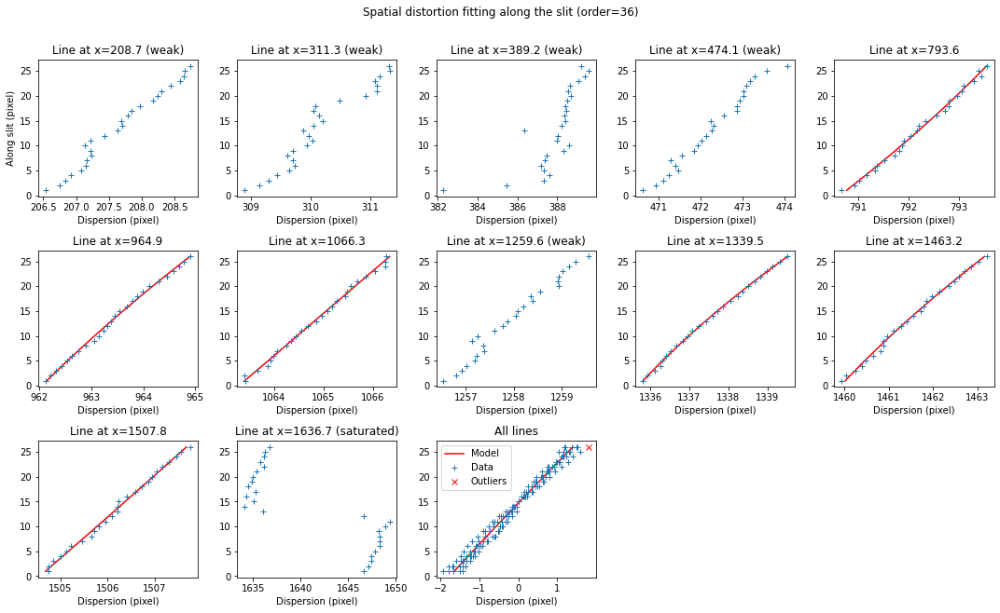

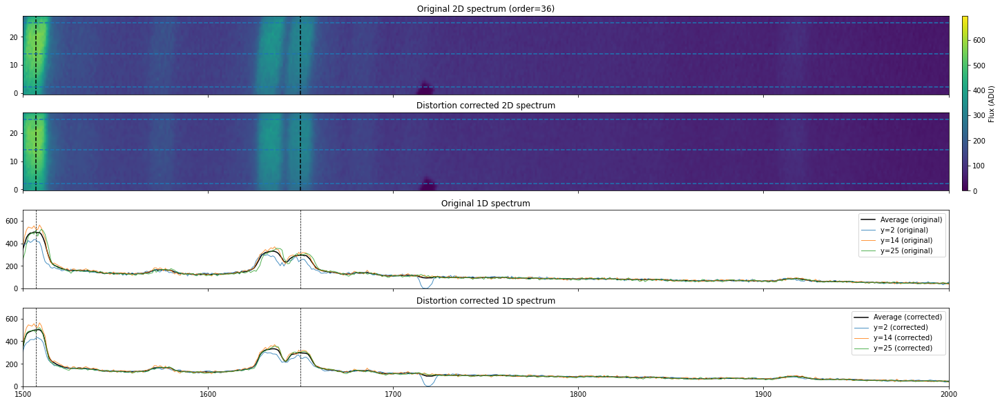

Working on order=37...
Excluding 0 saturated measurements (>500000.0)
Excluding 85 measurements below 5.0-sigma (<230.49)


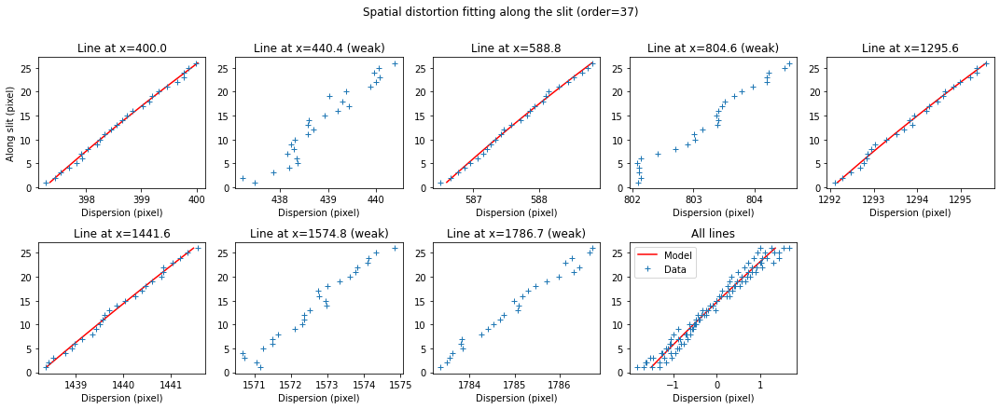

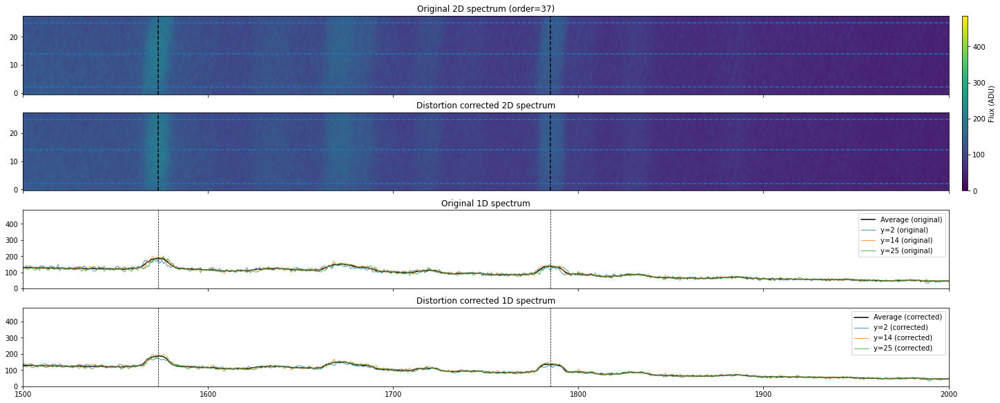

Working on order=38...
Excluding 0 saturated measurements (>500000.0)
Excluding 45 measurements below 5.0-sigma (<155.80)


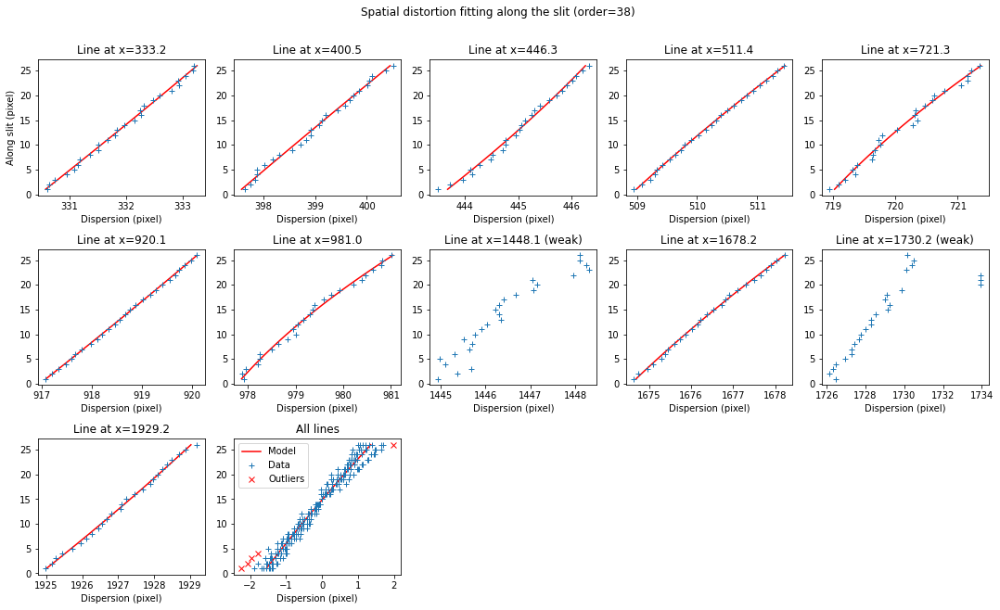

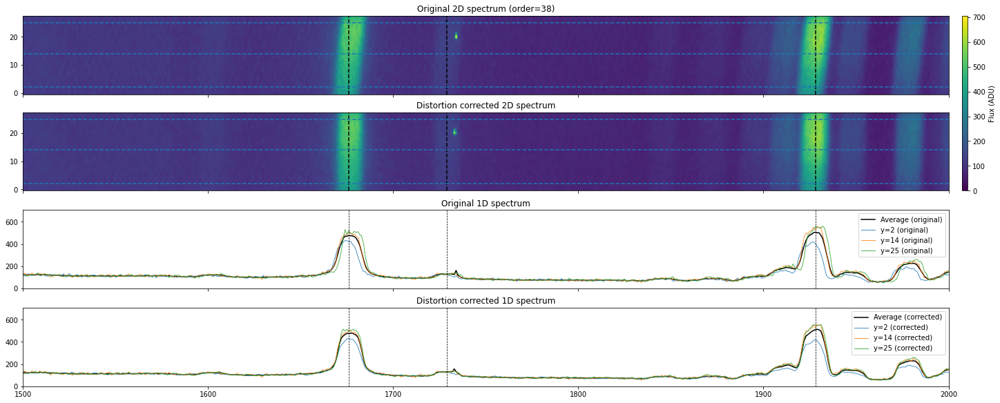

Working on order=39...
Excluding 0 saturated measurements (>500000.0)
Excluding 46 measurements below 5.0-sigma (<183.39)


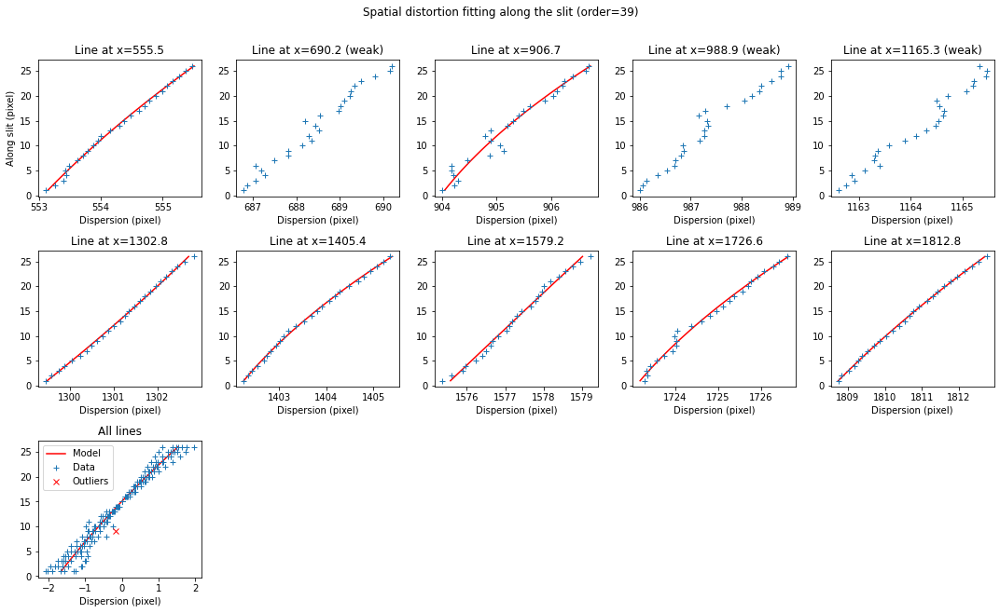

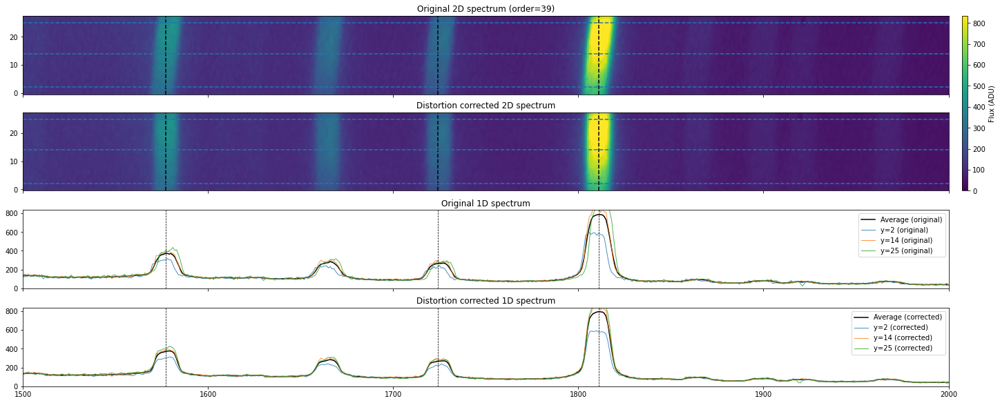

Working on order=40...
Excluding 0 saturated measurements (>500000.0)
Excluding 132 measurements below 5.0-sigma (<182.38)


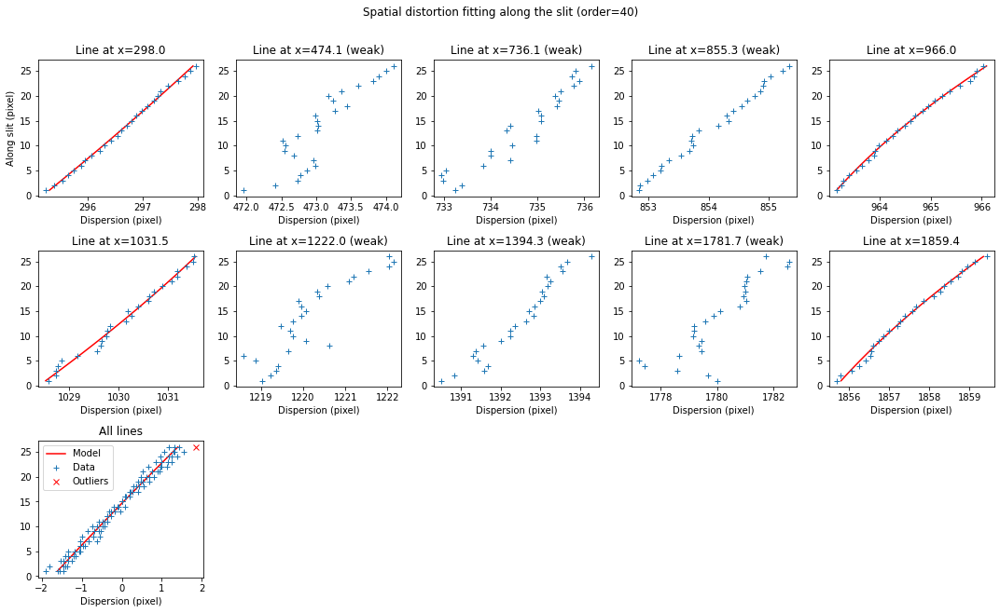

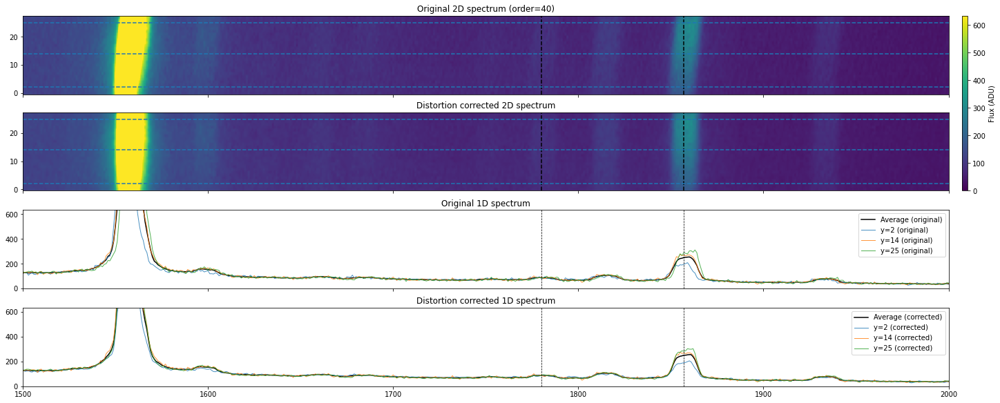

Working on order=41...
Excluding 0 saturated measurements (>500000.0)
Excluding 197 measurements below 5.0-sigma (<195.62)


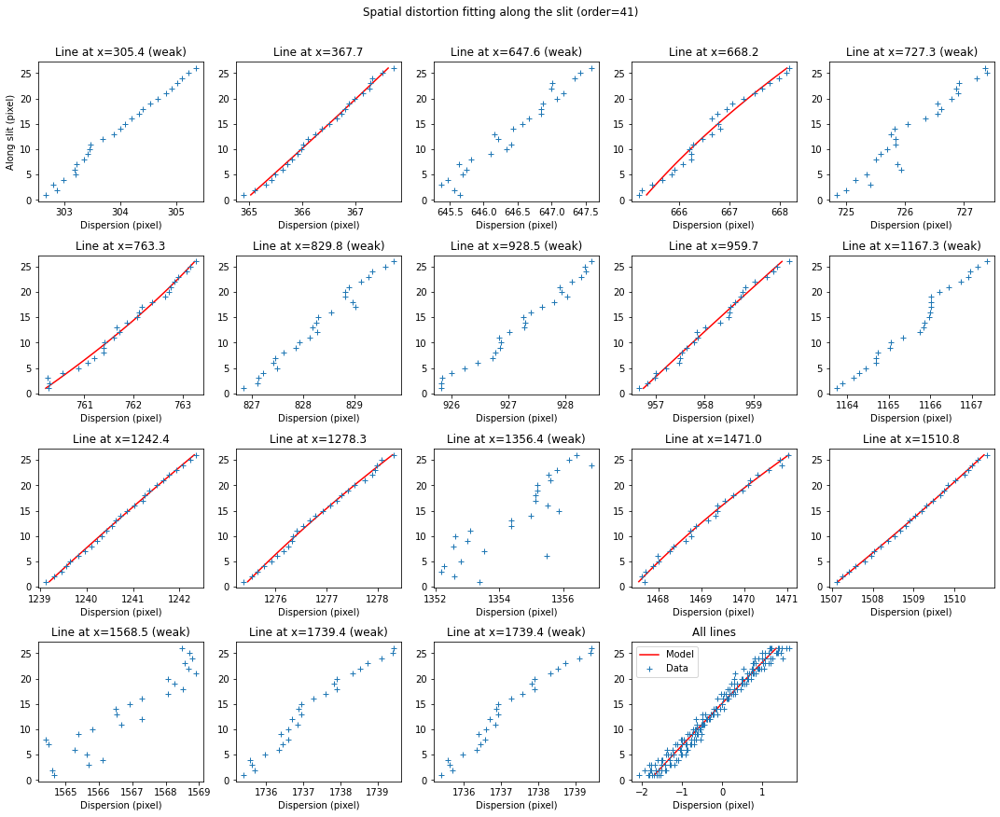

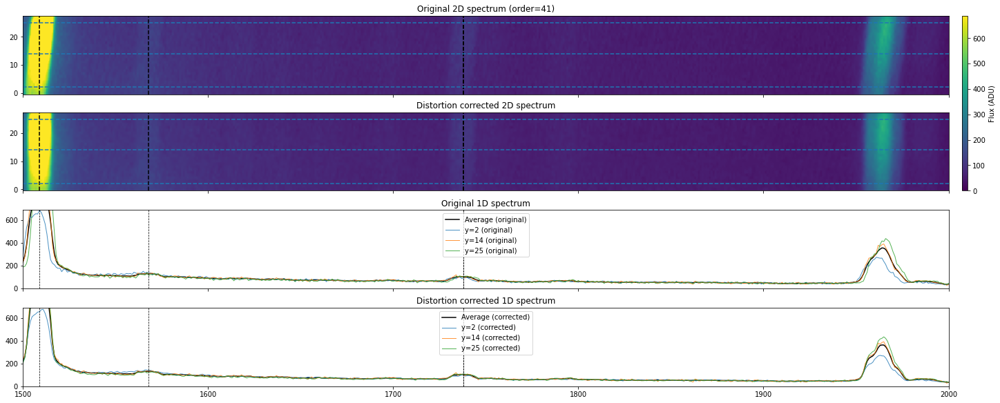

Working on order=42...
Fit failed near x=1341
Fit failed near x=1341
Fit failed near x=1341
Fit failed near x=1341
Fit failed near x=1341
Fit failed near x=1341
Fit failed near x=1341
Excluding 0 saturated measurements (>500000.0)
Excluding 84 measurements below 5.0-sigma (<174.57)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


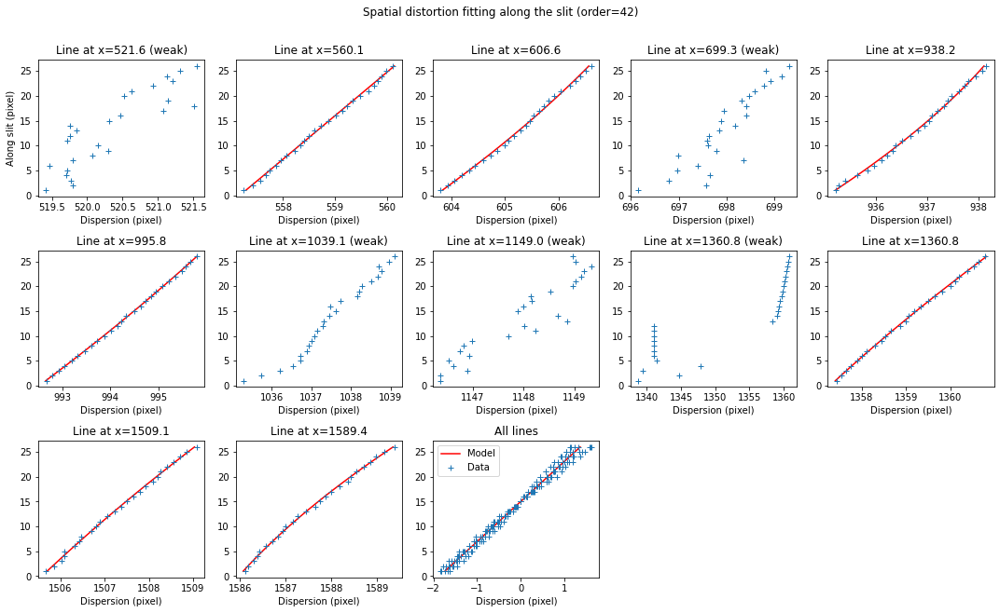

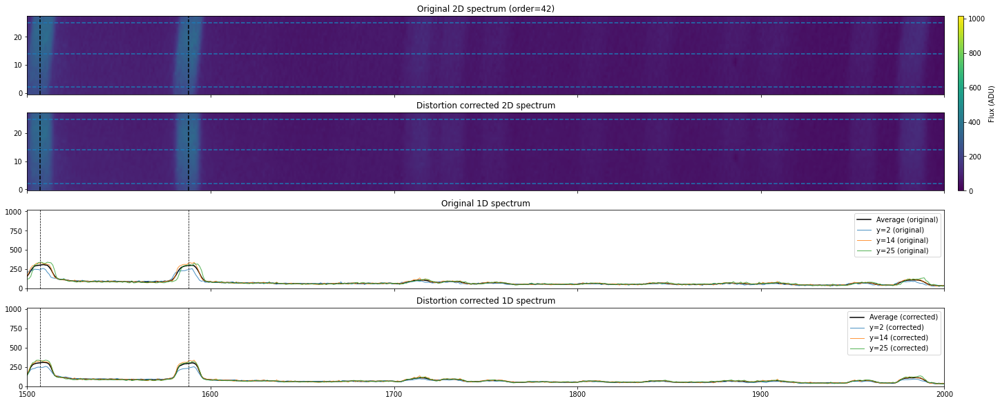

Working on order=43...
Excluding 0 saturated measurements (>500000.0)
Excluding 120 measurements below 5.0-sigma (<144.04)


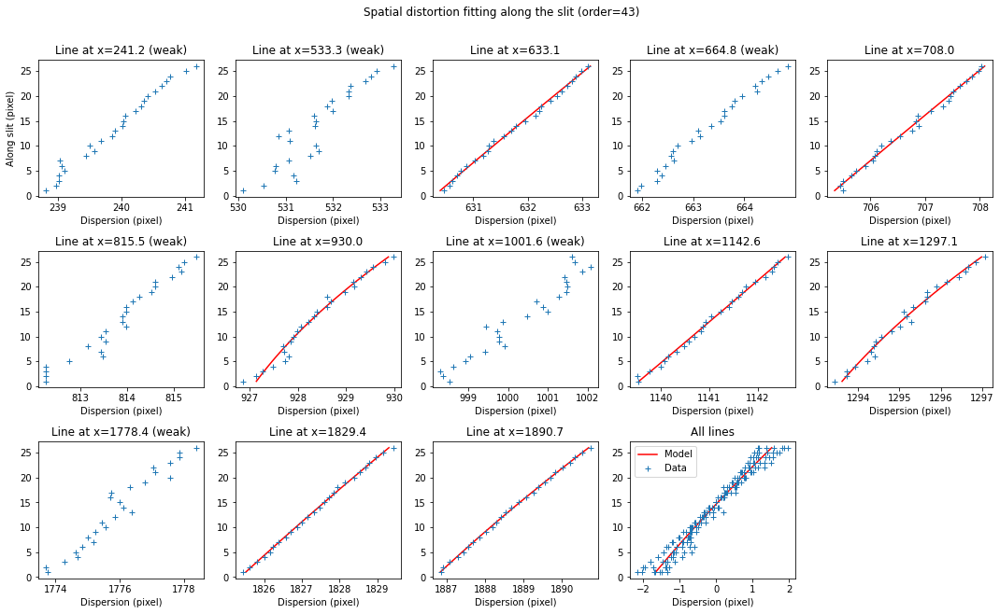

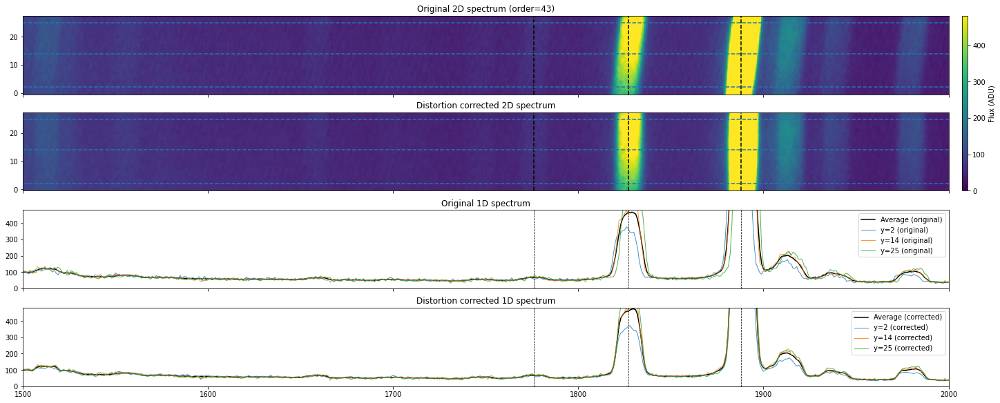

Working on order=44...
Excluding 0 saturated measurements (>500000.0)
Excluding 67 measurements below 5.0-sigma (<140.60)


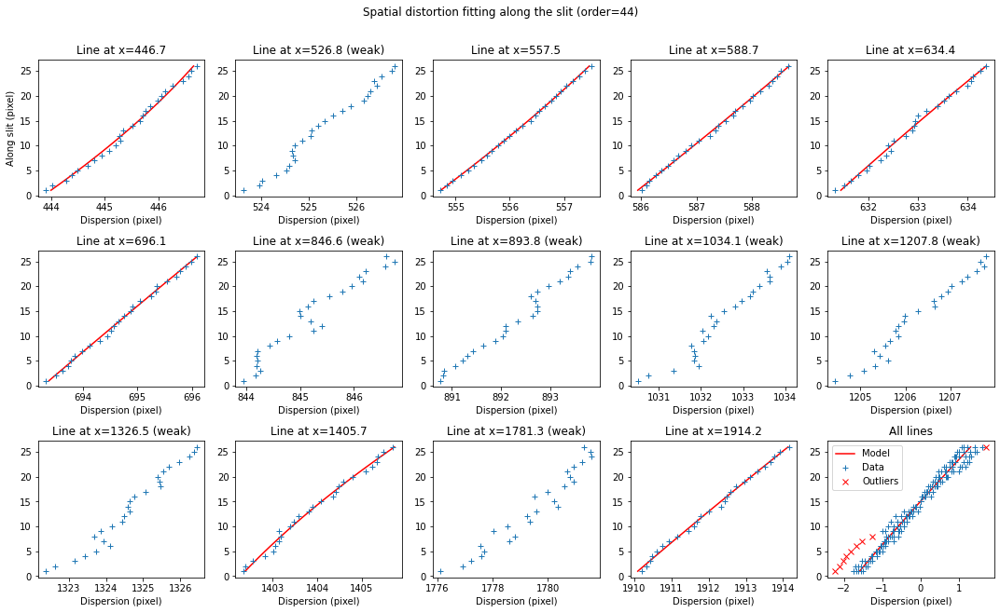

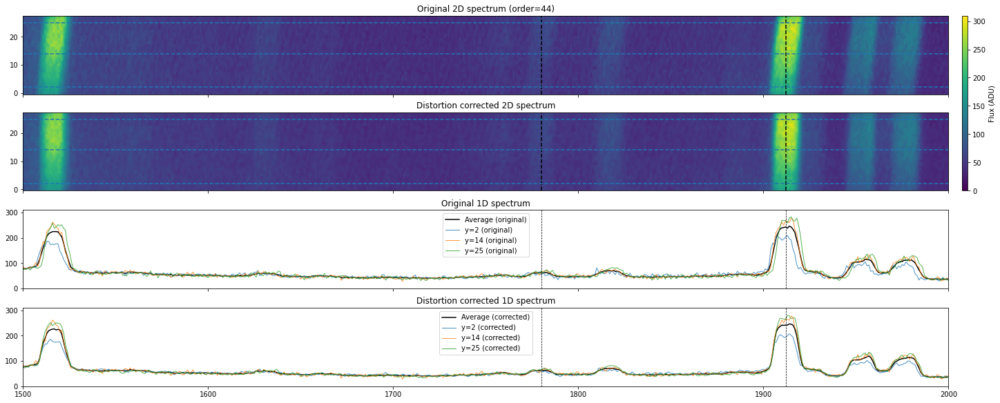

Working on order=45...
Excluding 0 saturated measurements (>500000.0)
Excluding 46 measurements below 5.0-sigma (<130.43)


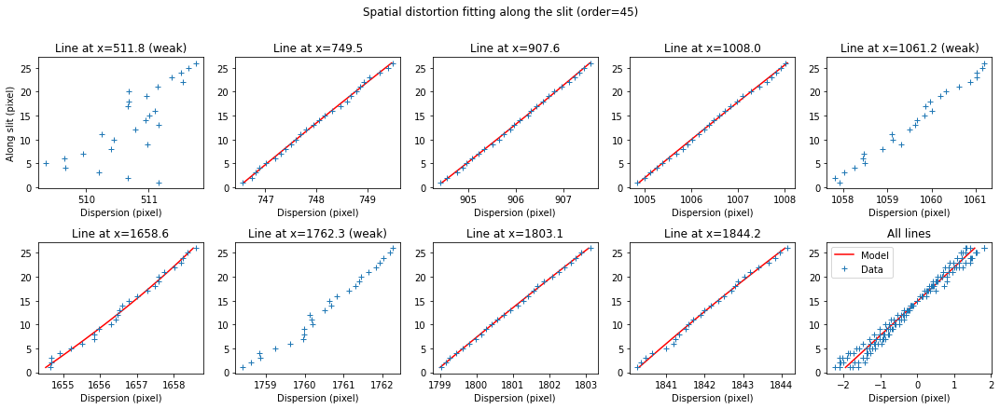

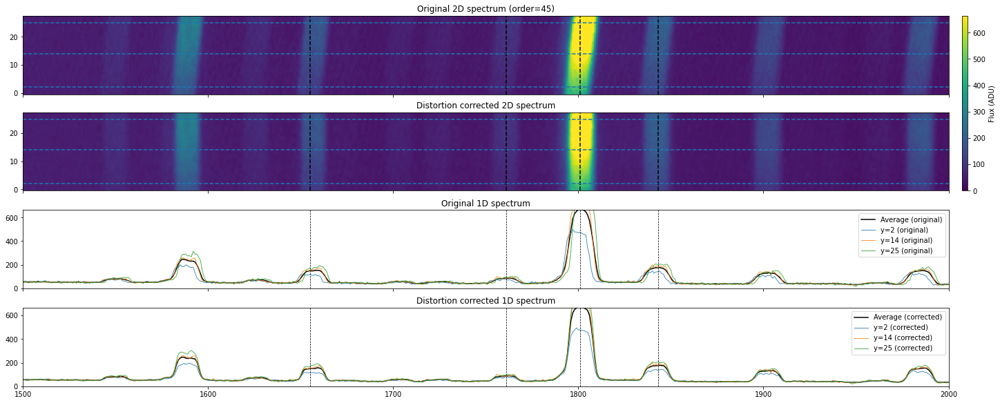

Working on order=46...
Excluding 0 saturated measurements (>500000.0)
Excluding 79 measurements below 5.0-sigma (<151.10)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


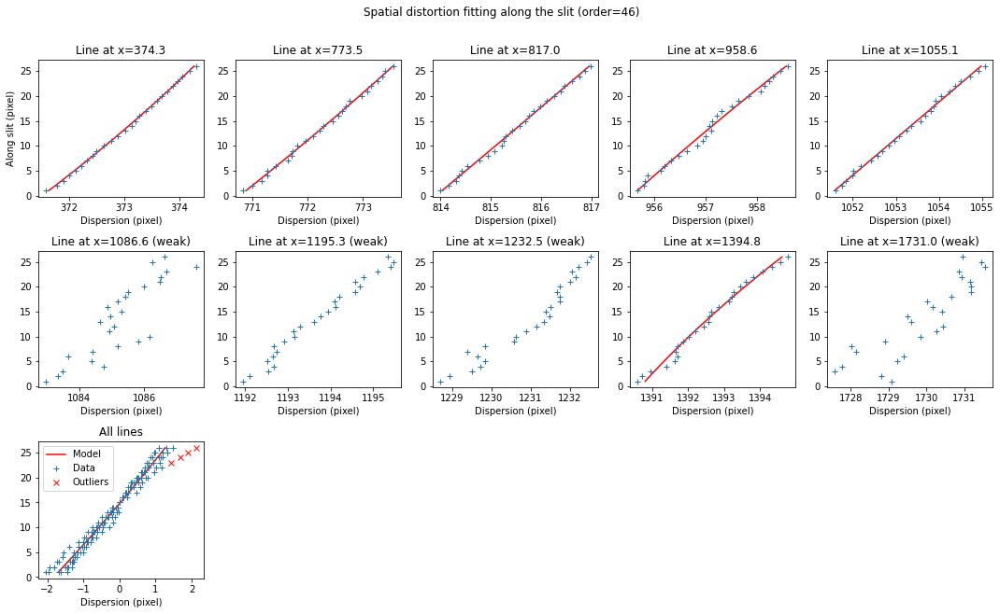

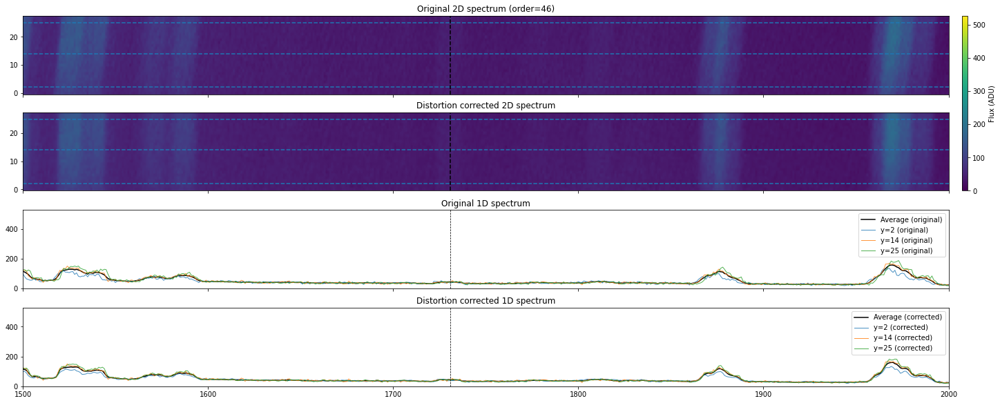

Working on order=47...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<118.11)


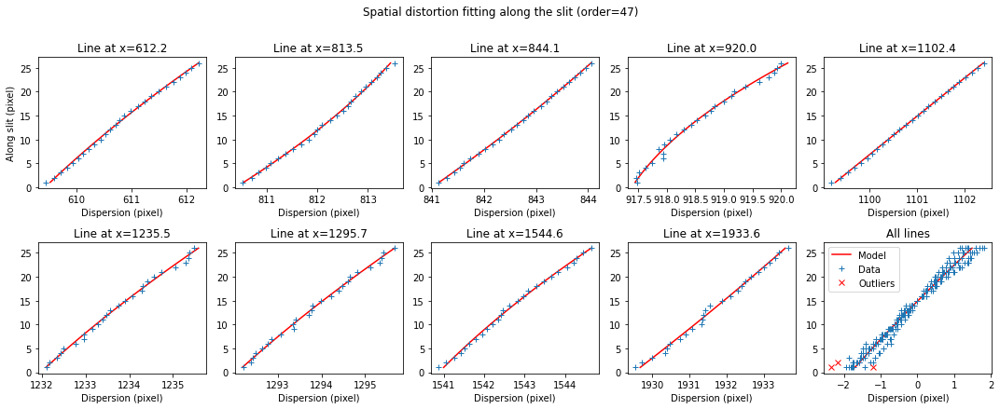

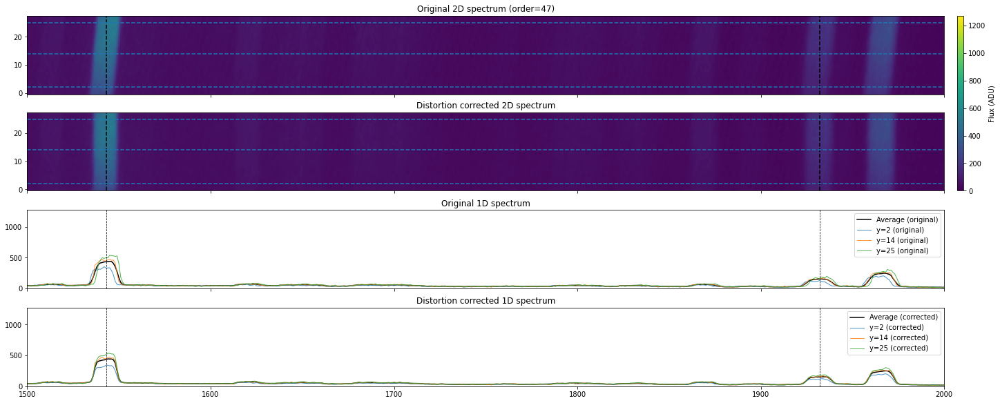

Working on order=48...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<133.60)


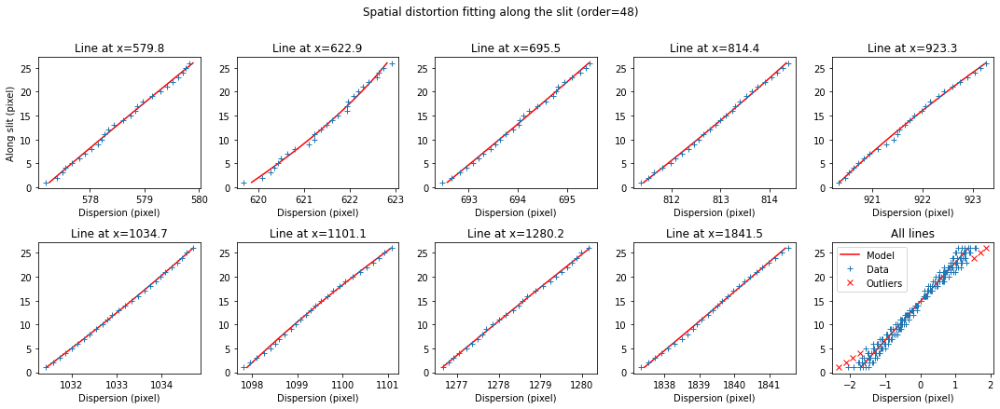

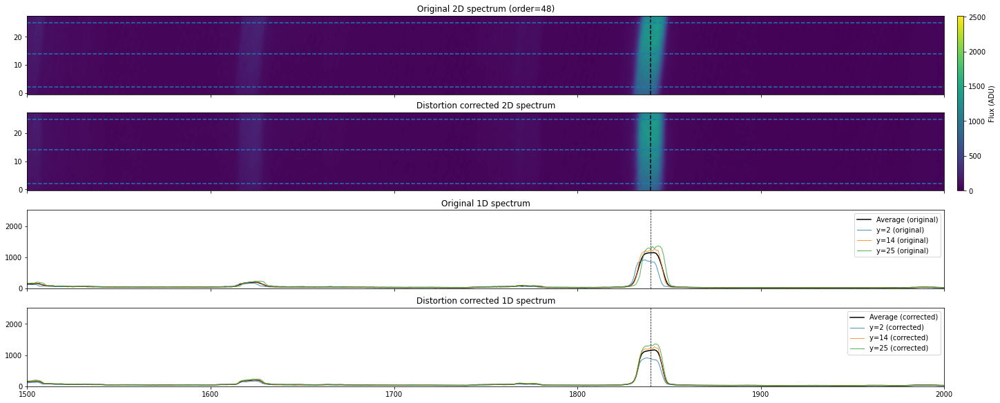

Working on order=49...


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


Excluding 27 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<112.75)


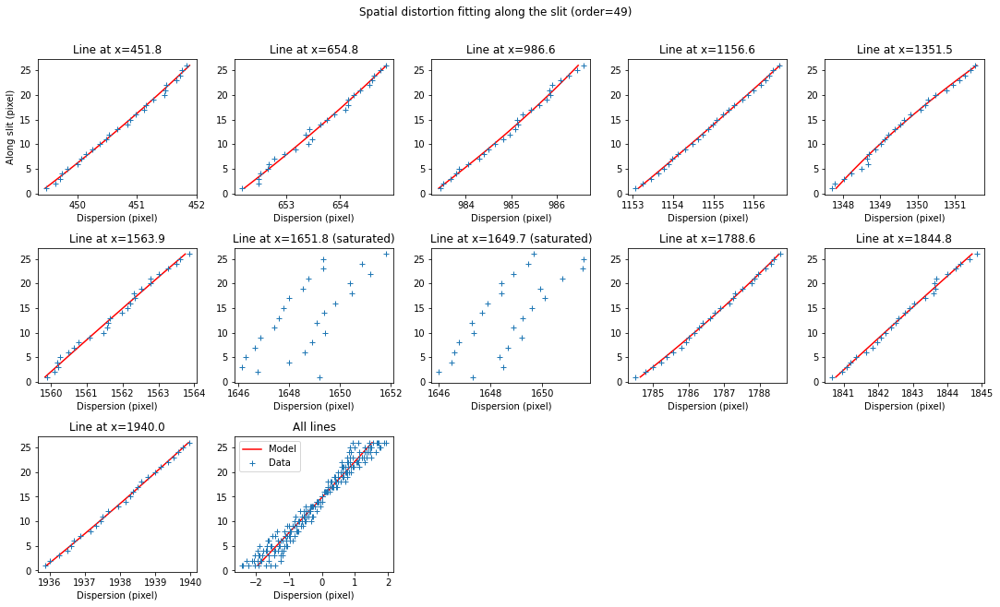

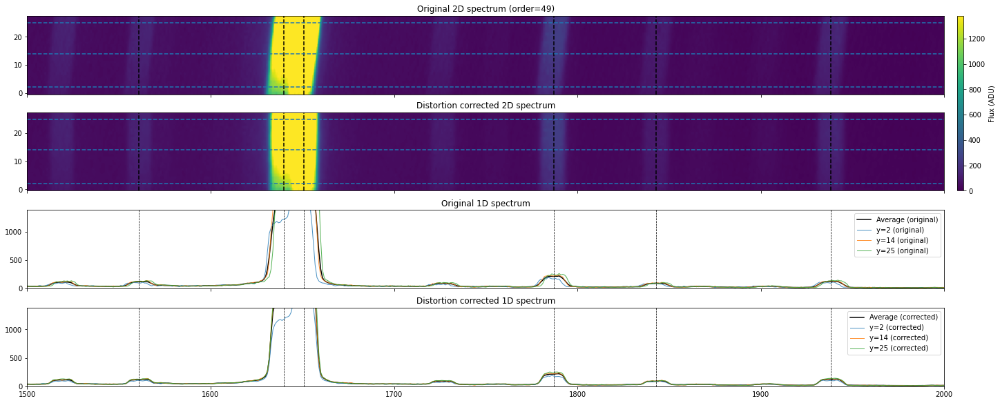

Working on order=50...
Excluding 0 saturated measurements (>500000.0)
Excluding 5 measurements below 5.0-sigma (<98.19)


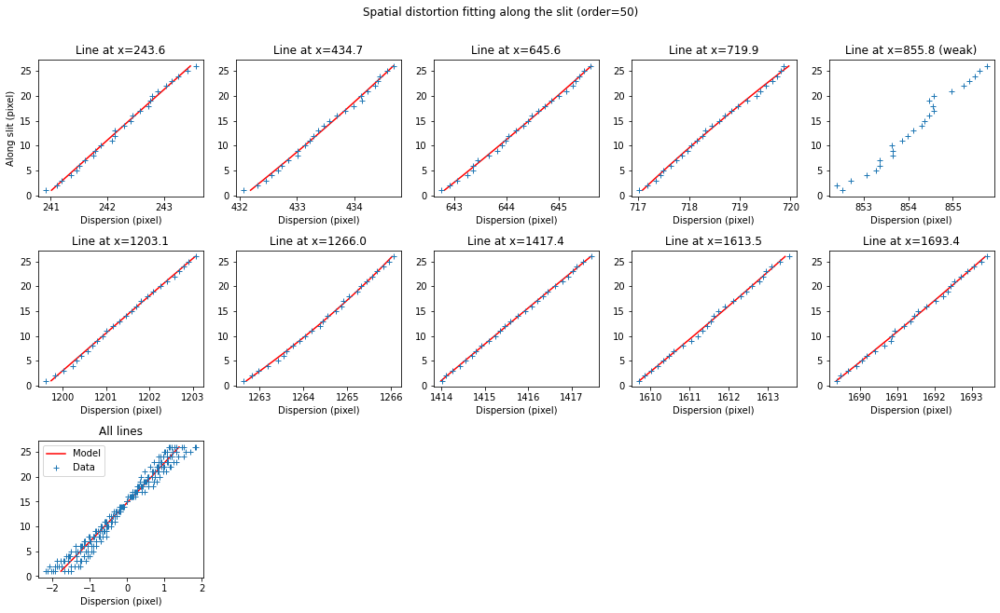

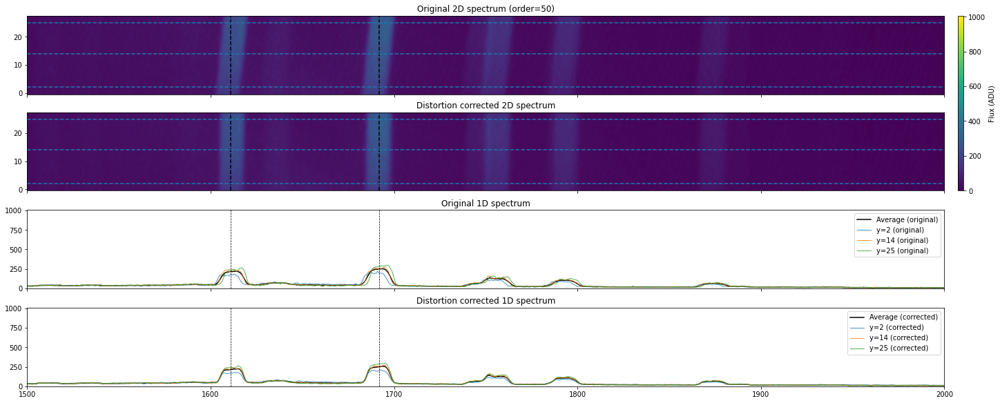

Working on order=51...
Excluding 0 saturated measurements (>500000.0)
Excluding 1 measurements below 5.0-sigma (<79.08)


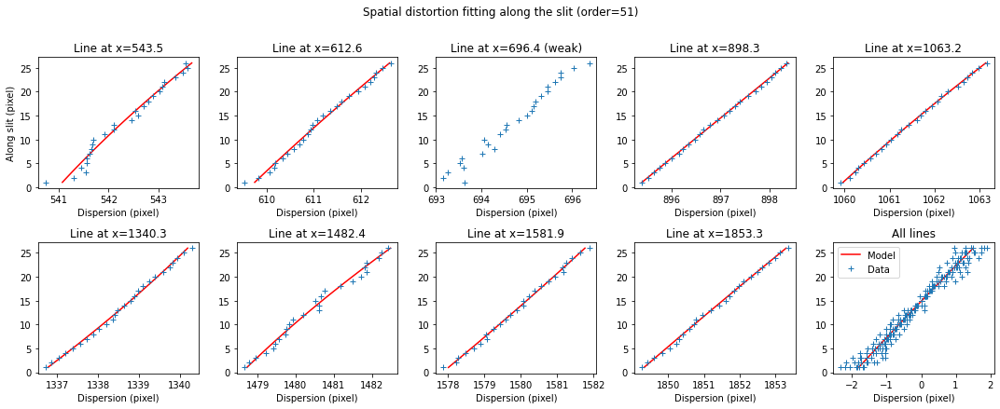

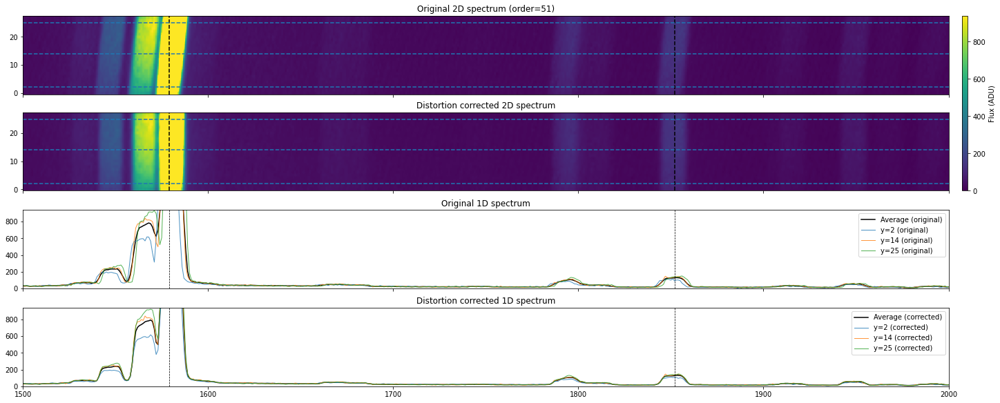

Working on order=52...
Excluding 0 saturated measurements (>500000.0)
Excluding 2 measurements below 5.0-sigma (<58.84)


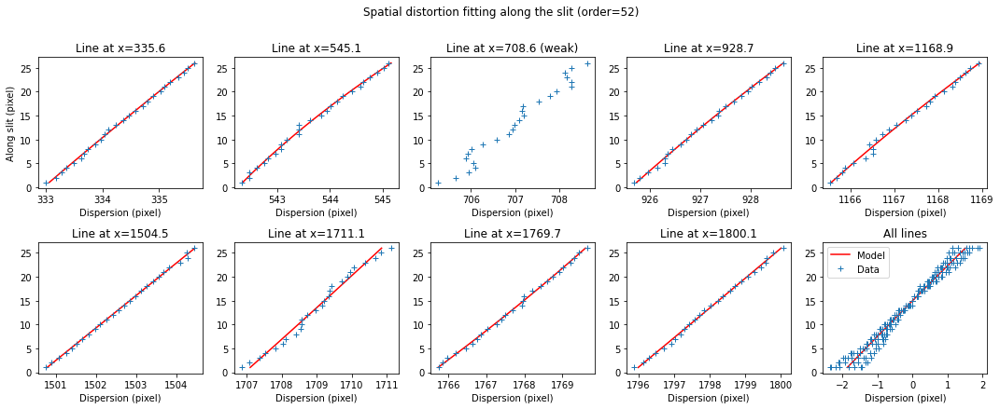

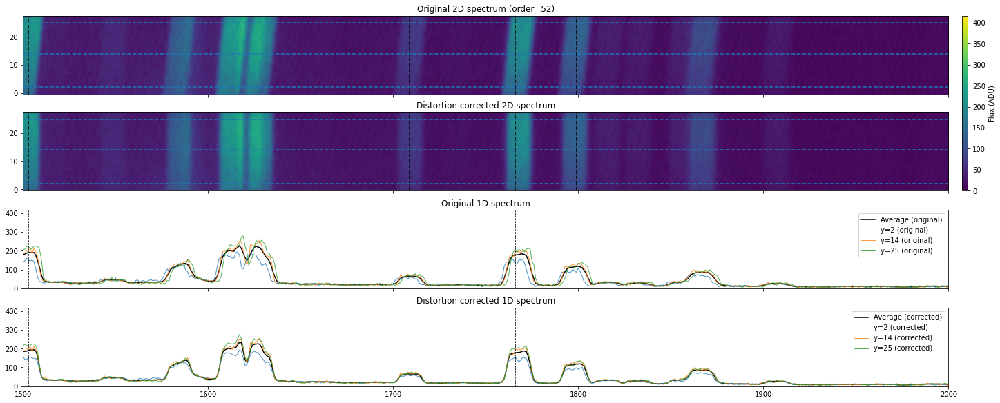

Working on order=53...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<49.67)


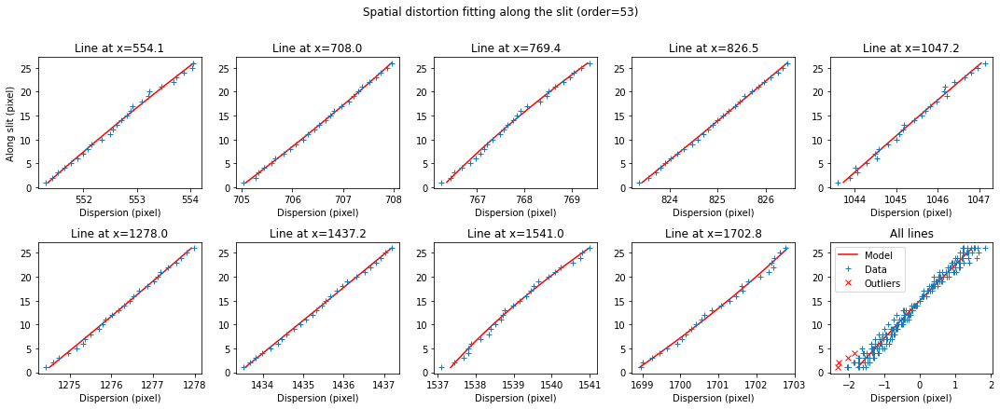

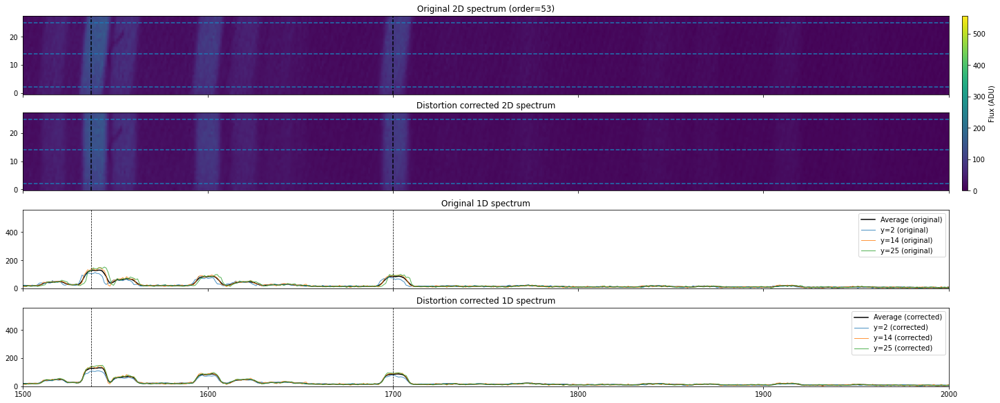

Working on order=54...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<37.50)


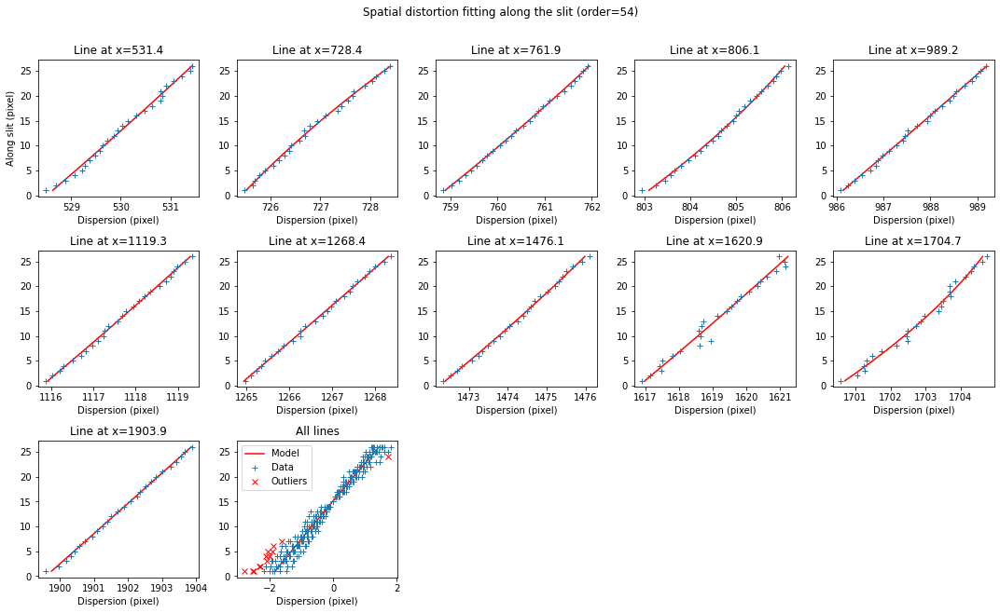

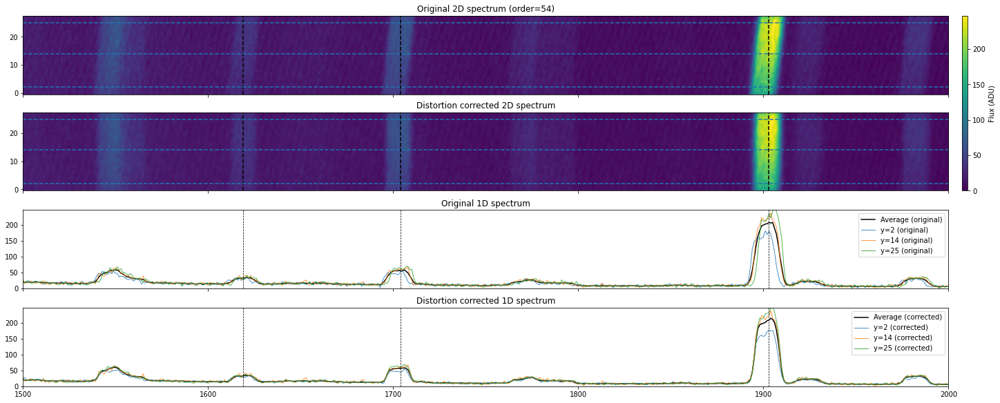

Working on order=55...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<30.68)


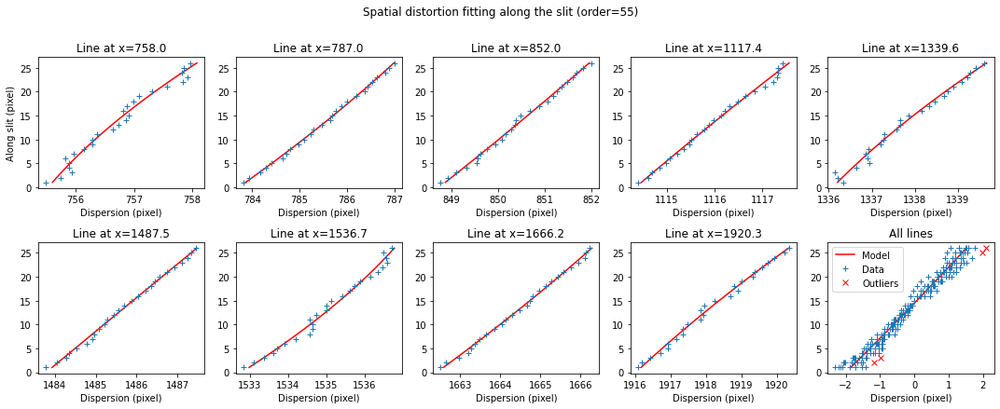

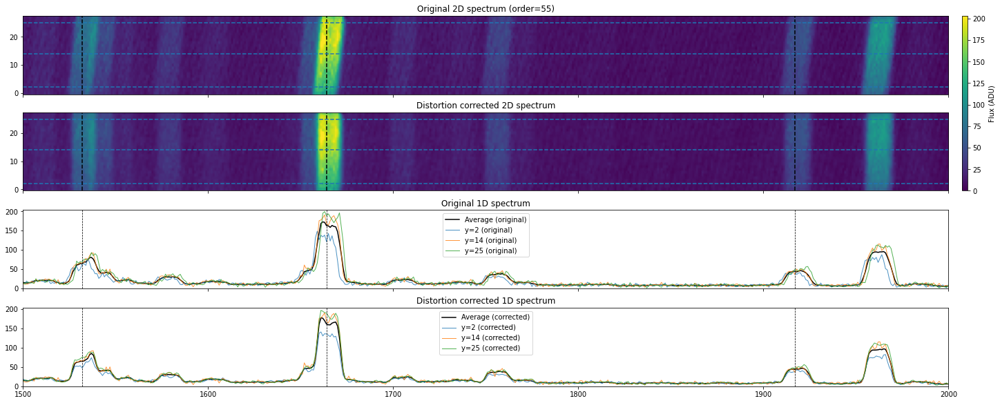

Working on order=56...
Excluding 0 saturated measurements (>500000.0)
Excluding 70 measurements below 5.0-sigma (<24.42)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


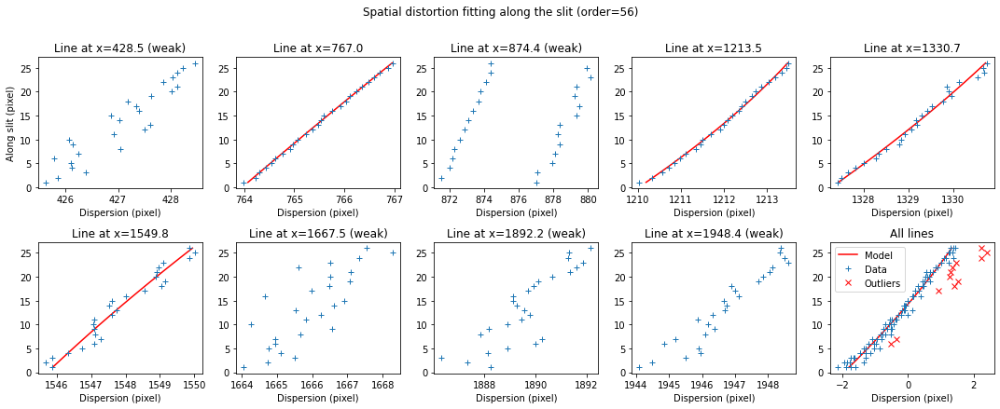

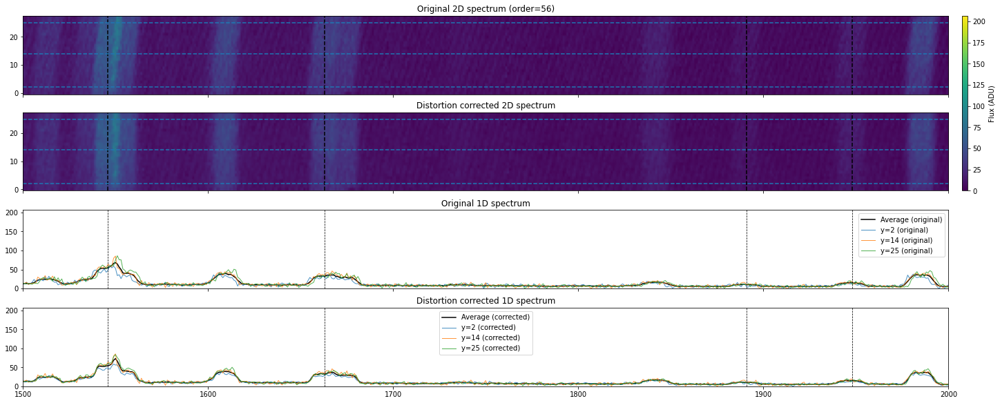

Working on order=57...
Excluding 0 saturated measurements (>500000.0)
Excluding 0 measurements below 5.0-sigma (<18.55)


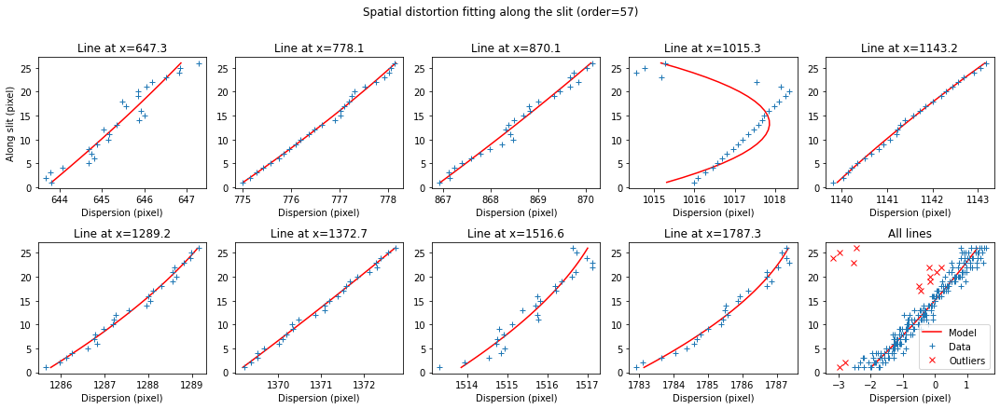

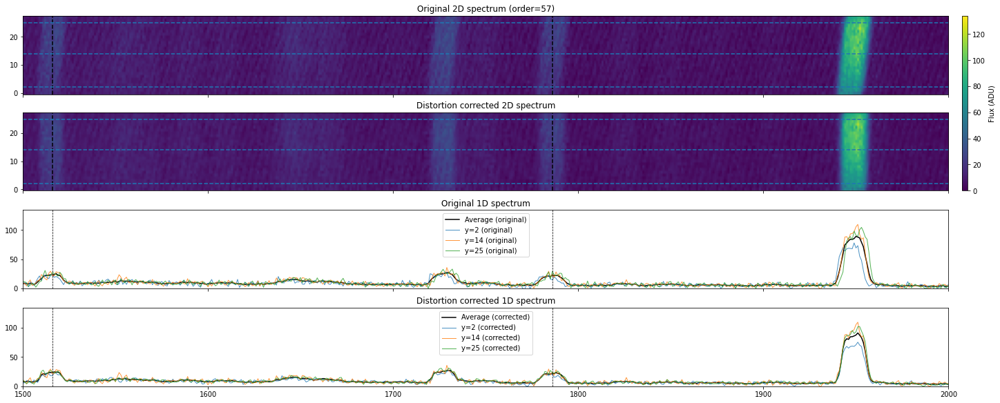

Working on order=58...
Excluding 0 saturated measurements (>500000.0)
Excluding 23 measurements below 5.0-sigma (<15.64)


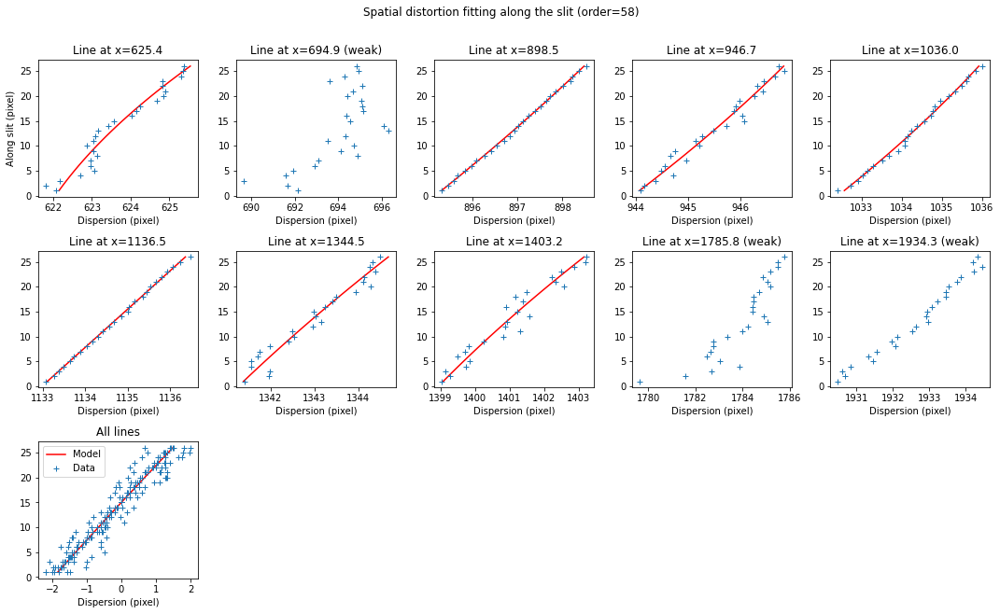

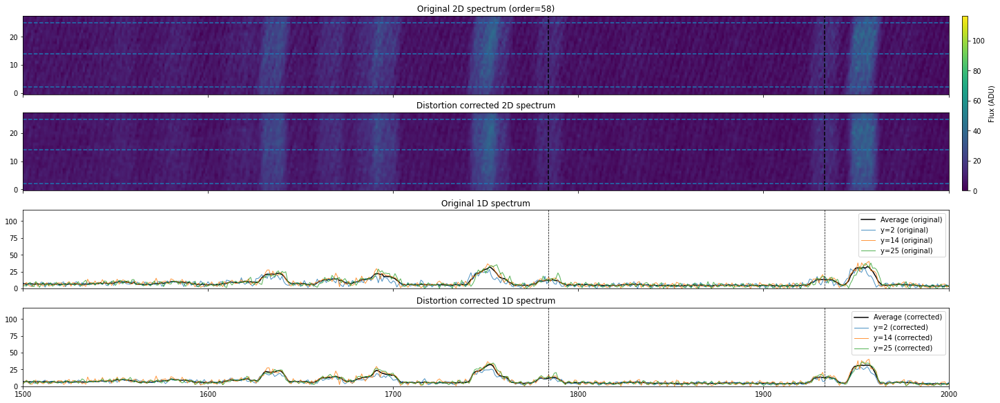

Working on order=59...
Excluding 0 saturated measurements (>500000.0)
Excluding 10 measurements below 5.0-sigma (<13.10)


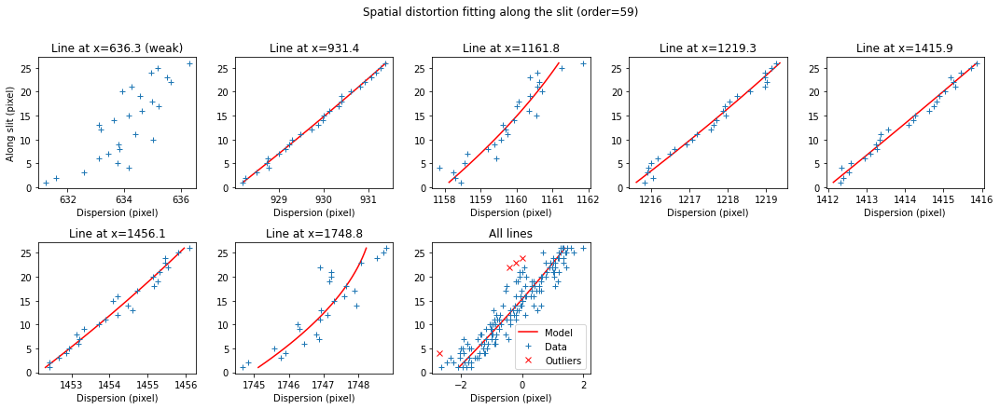

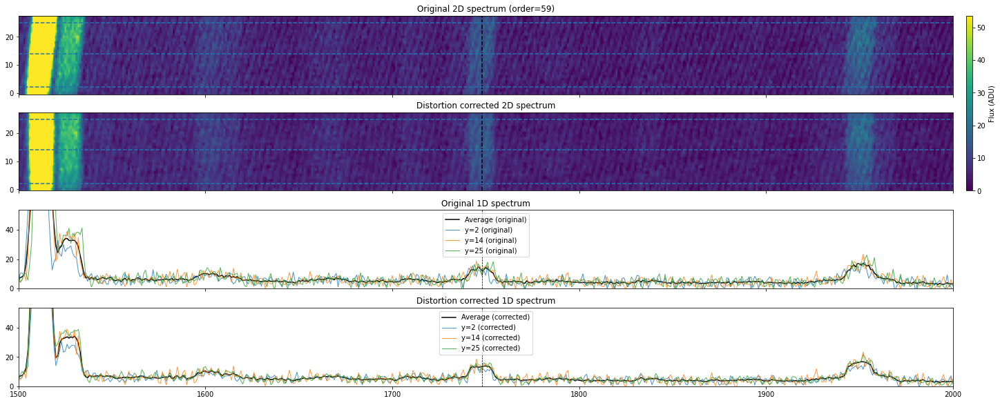

Working on order=60...
Fit failed near x=1692
Excluding 0 saturated measurements (>500000.0)
Excluding 60 measurements below 5.0-sigma (<11.93)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


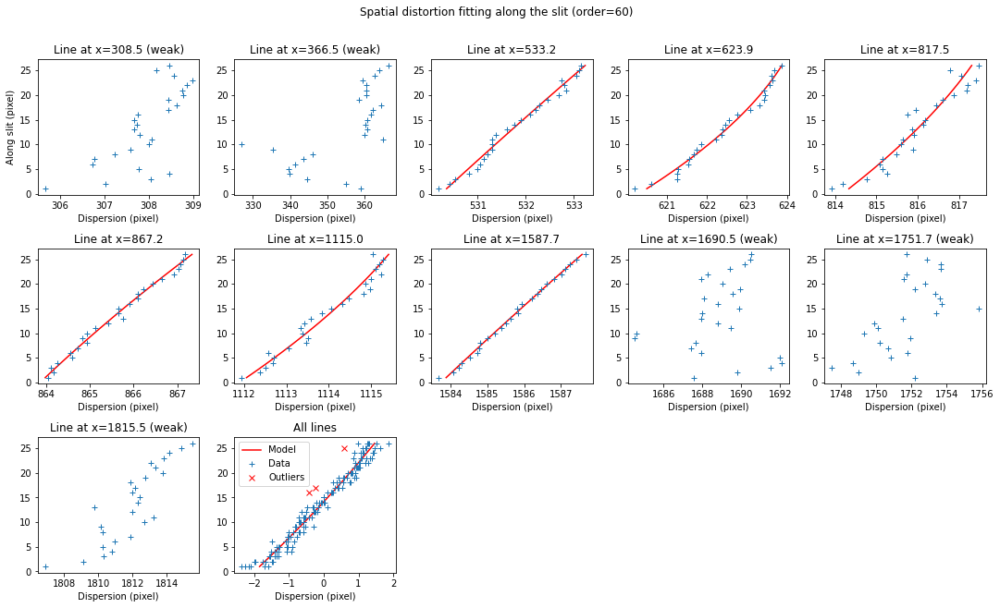

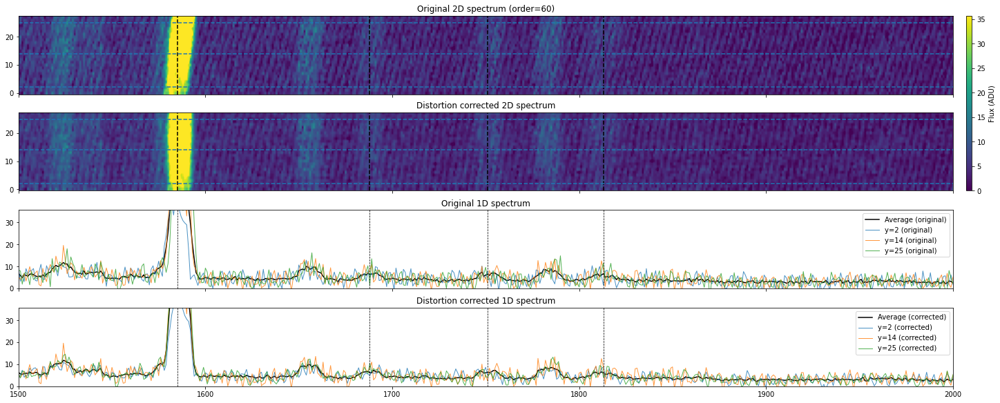

Working on order=61...
Excluding 0 saturated measurements (>500000.0)
Excluding 13 measurements below 5.0-sigma (<10.80)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


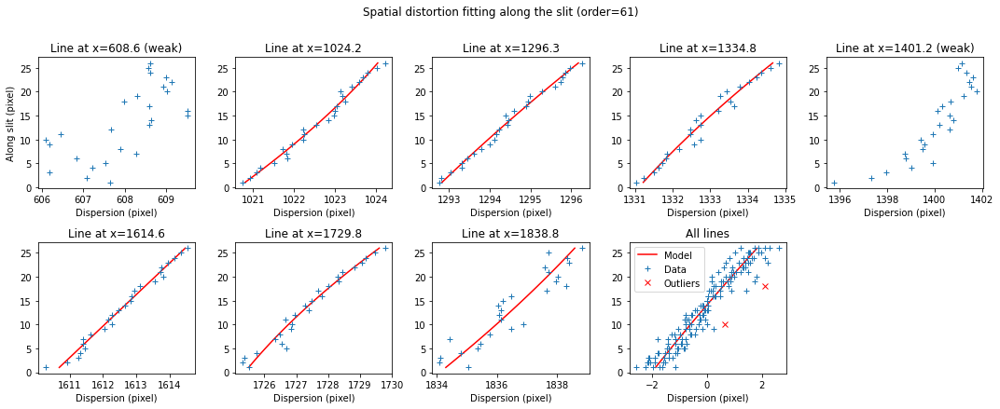

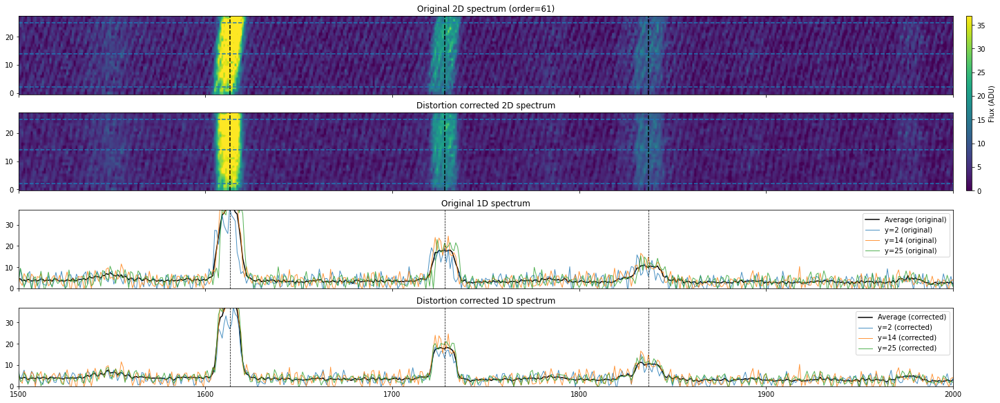

Working on order=62...
Fit failed near x=759


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


Excluding 0 saturated measurements (>500000.0)
Excluding 96 measurements below 5.0-sigma (<9.69)


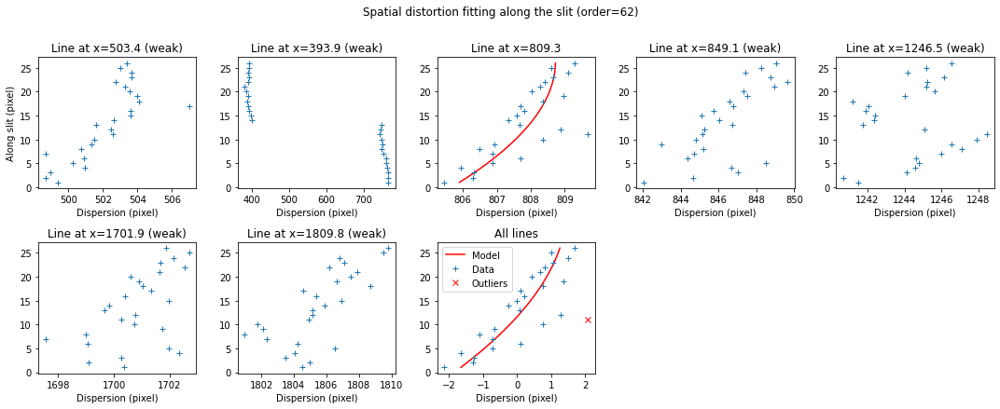

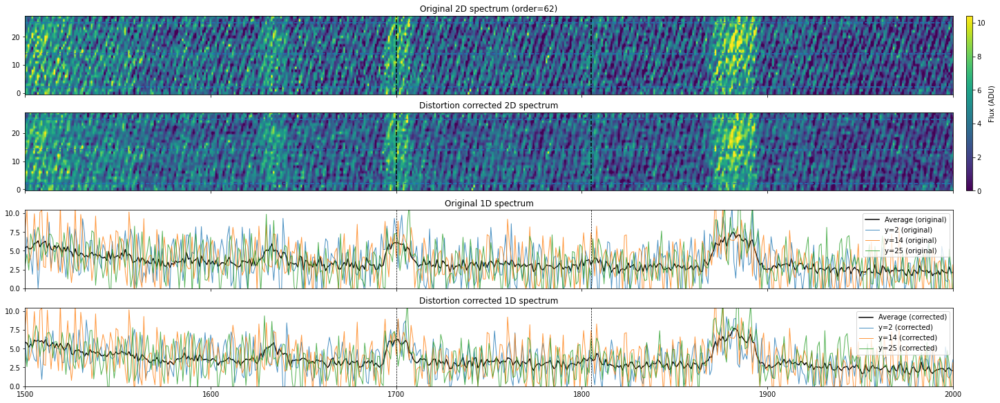

Working on order=63...
Excluding 0 saturated measurements (>500000.0)
Excluding 126 measurements below 5.0-sigma (<9.42)


C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\scipy\optimize\minpack.py:834: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)
C:\Users\navar\AppData\Roaming\Python\Python37\site-packages\astropy\modeling\fitting.py:770: RuntimeWarning: invalid value encountered in true_divide
  lacoef /= scl[:, np.newaxis] if scl.ndim < rhs.ndim else scl
 [astropy.modeling.fitting]


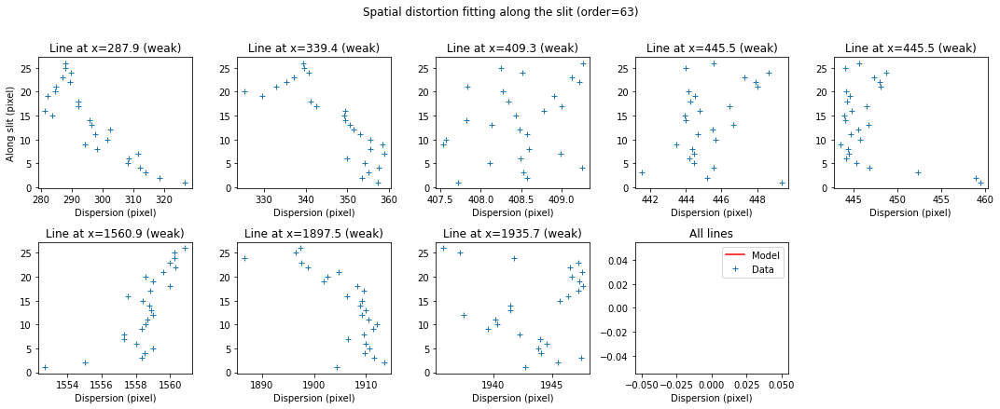

Working on order=64...
Excluding 0 saturated measurements (>500000.0)
Excluding 97 measurements below 5.0-sigma (<9.25)


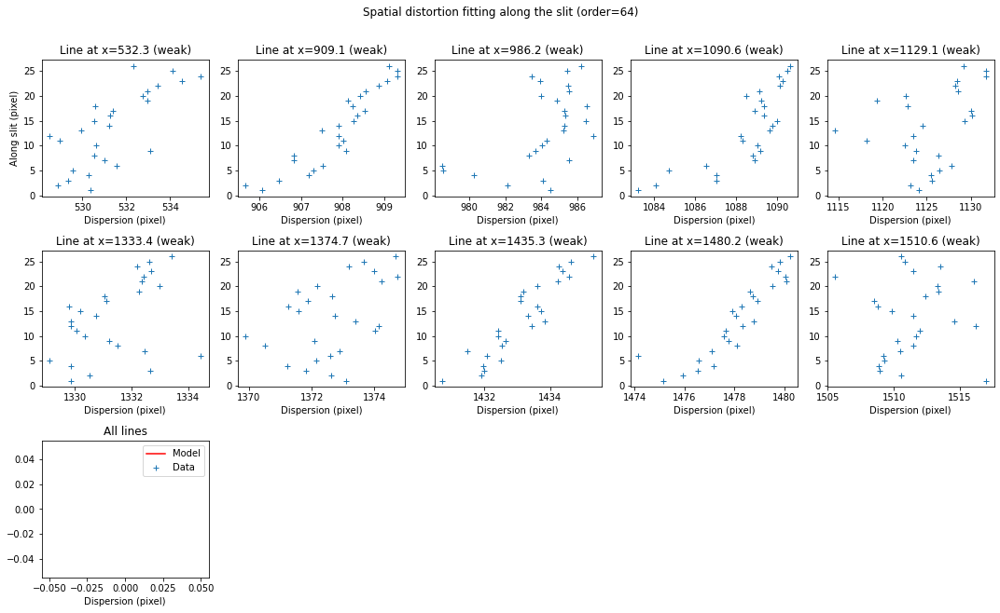

Working on order=65...
Excluding 0 saturated measurements (>500000.0)
Excluding 93 measurements below 5.0-sigma (<9.12)


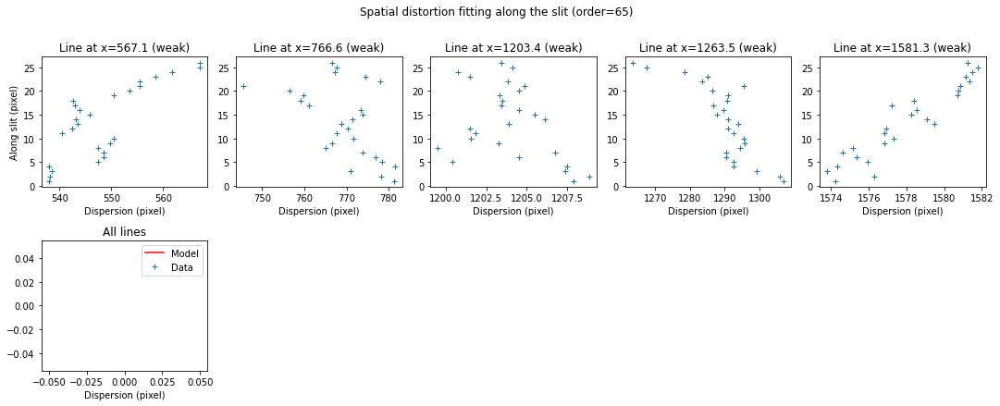

Working on order=66...
Fit failed near x=1498
Excluding 0 saturated measurements (>500000.0)
Excluding 107 measurements below 5.0-sigma (<9.19)


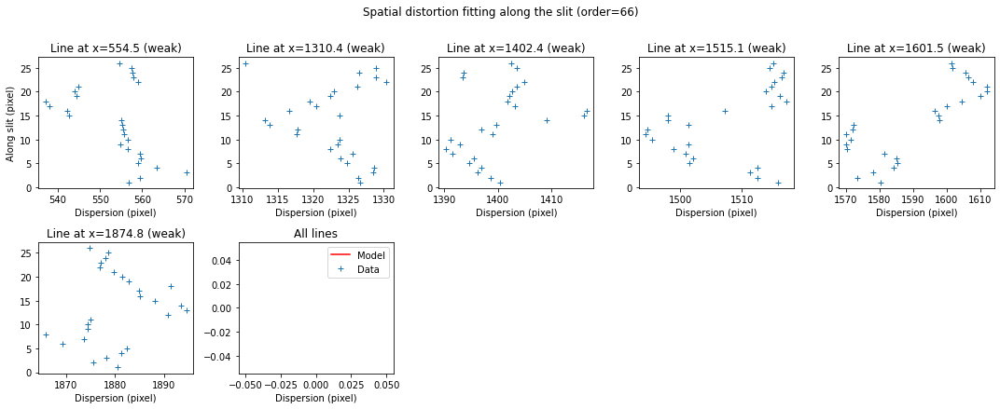

Working on order=67...
Fit failed near x=1579
Excluding 0 saturated measurements (>500000.0)
Excluding 63 measurements below 5.0-sigma (<8.94)


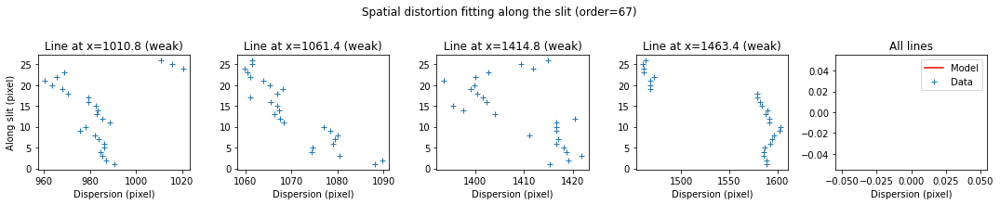

Working on order=68...
Fit failed near x=576
Fit failed near x=1899
Excluding 0 saturated measurements (>500000.0)
Excluding 93 measurements below 5.0-sigma (<8.71)


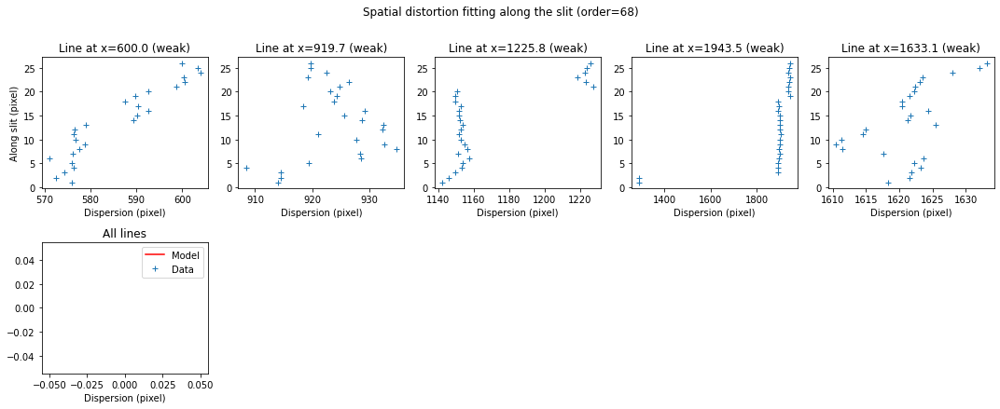

Working on order=69...
Working on order=70...
Working on order=71...
Working on order=72...
Working on order=73...
Working on order=74...
Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_thar_0015_linear_spatdist.fits
Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_thar_0015_linear_spatdist_1d.fits


In [21]:
# check if wave1d is already defined, if not, open the output file
try:
    wave1d
except:
    print("Opening Wavelength solution file")
    with fits.open(wavelength_solution_file) as hdu:
        wave1d = hdu[0].data

# 6.2 map spatial distortion along the slit (make it loop along the orders)
#     measure the distortion of the lines along the slit, and construct a grid of y axis for interpolation

# create new array for saving the corrected data
arc_spatdist_corrected = np.empty(arc2d.shape)

# start the loop
for order in np.arange(1,n_orders+1):

    print(f"Working on order={order}...")
    
    # now extract the data
    arc_spectrum = arc2d[order-1,:]
    
    # get information for wavelength solution 
    wave_info_order = wavelength_info[wavelength_info['order'] == order]

    # get central wavelength of the lines and the corresponding pixel position
    ThAr_peak_wavelengths = wave_info_order['wavelength'].to_numpy()
    ThAr_peak_pixels      = wave_info_order['pixel'].to_numpy()
    
    
    
    # if order has wavelength solution, evaluate it:
    if ~np.isnan(ThAr_peak_pixels).any():
        fit_spat_file = os.path.join(dist_directory,  arc_extracted.replace(file_extension,f"_n{order:02d}_spatial_fit{plot_extension}"))

        spat_rows, polyfits_x_along_y = steles.fit_spatial_distortion(arc2d[order-1,:,:], ThAr_peak_pixels, order, window=window_fit_peak,
                                                               saturation_threshold=saturation_threshold, sigma_threshold=sigma_threshold,
                                                               n_pix_step=n_pix_step, 
                                                               ndeg=ndeg_distortion, fitting_sigma_threshold=fitting_sigma_threshold, fitting_niter=fitting_niter,
                                                               n_col=5, single_fit=True,
                                                               output=fit_spat_file)

        # store the distortion coefficients on the database directory
        file_csv = spatdist_csv_prefix + f"_n{order:02d}.csv"

        # if the fitting was successful, save csv and apply correction
        if ~np.isnan(polyfits_x_along_y[0].c0.value).any():
            steles.save_polyfits_csv(ThAr_peak_pixels, polyfits_x_along_y, file_csv, show_messages=False)

            # 6.3 apply spatial distortion correction, plot the arc lamp to show the results.

            # This step is necessary to load the distortion coefficients to apply on OBJECT data
            ThAr_peak_pixels_load, polyfits_x_along_y = steles.read_polyfits_csv(file_csv)

            spat_corrected_file = os.path.join(dist_directory,  arc_extracted.replace(file_extension,f"_n{order:02d}_spatial_corrected{plot_extension}"))

            arc_corrected = steles.correct_spatial_distortion(arc2d[order-1,:,:], spat_rows, polyfits_x_along_y, ThAr_peak_pixels, order, y_ref=None,
                                                       show_plot=True, figsize=(20,8),
                                                       wave_pixel_reference = wave_pixel_reference, max_displ_percent=99, plot_x_limit=spectral_pixel_limits,
                                                       output=spat_corrected_file)

            arc_spatdist_corrected[order-1,:,:] = arc_corrected
            
        # if the fitting was NOT successful, just copy the original data
        else:    
            arc_spatdist_corrected[order-1,:,:] = arc2d[order-1,:,:]
        
    # if order has no wavelength solution, do nothing:
    else:    
        arc_spatdist_corrected[order-1,:,:] = arc2d[order-1,:,:]

arc2d_distcor_header = arc2d_header.copy()
arc2d_distcor_header.set("ST_SPATD", value=True, comment="Spatial distortion corrected")
arc2d_distcor_header.set("ST_FSPAT", value=arc_extracted, comment="Ref file for spatial distortion")
    

# save the extracted orders after correcting for spatial distortion
steles.save_spectrum_to_fits(arc_spatdist_corrected, spatdist_corrected_2d_file, header=arc2d_distcor_header, overwrite=True)

arc1d_distcor_header = arc2d_distcor_header.copy()
arc1d_distcor_header.set("ST_EXT1", value="Integrated Flux", comment="Extension 1")
arc1d_distcor_header.set("ST_EXT2", value="Wavelength",      comment="Extension 2")

# create a 1d spectrum to evaluate the wavelength solution
arc_spatdist_corrected_1d = steles.collapse_spectrum2d(arc_spatdist_corrected)

arc_spatdist_corrected_1d = np.array([arc_spatdist_corrected_1d,wave1d], dtype='float32')
steles.save_spectrum_to_fits(arc_spatdist_corrected_1d, spatdist_corrected_1d_file, header=arc1d_distcor_header, overwrite=True)


In [22]:


# check if wave1d is already defined, if not, open the output file
try:
    wave1d
except:
    print("Opening Wavelength solution file")
    with fits.open(wavelength_solution_file) as hdu:
        wave1d = hdu[0].data

# if spat_rows was defined before, ok; else create it.
try:
    spat_rows
except NameError:
    # set a new grid of spatial pixels, avoiding the borders
    spat_rows = np.arange(n_pix_step, n_spat-n_pix_step, n_pix_step)
       
# now apply the distortion correction and add the wavelength calibration information on the science data

    
# 6.2 map spatial distortion along the slit (make it loop along the orders)
#     measure the distortion of the lines along the slit, and construct a grid of y axis for interpolation


with fits.open(red_directory+flat_extracted) as hdul:
    flat2d   = hdul[0].data
    flat2d_header = hdul[0].header

steles.apply_wave_spat_correction(flat2d, flat2d_header, n_orders, wave1d, wavelength_info, spat_rows, wave_pixel_reference, 
                                  arc_extracted, spatdist_csv_prefix, os.path.join(red_directory, flat_extracted), 
                                  file_suffix="_spatdist", file_extension=file_extension)


No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_flat_0033_20250128_linear_spatdist.fits
Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_flat_0033_20250128_linear_spatdist_1d.fits


..\steles.py:2626: RuntimeWarning: divide by zero encountered in true_divide
  yarr /= np.percentile(yarr,99)
..\steles.py:2626: RuntimeWarning: invalid value encountered in true_divide
  yarr /= np.percentile(yarr,99)


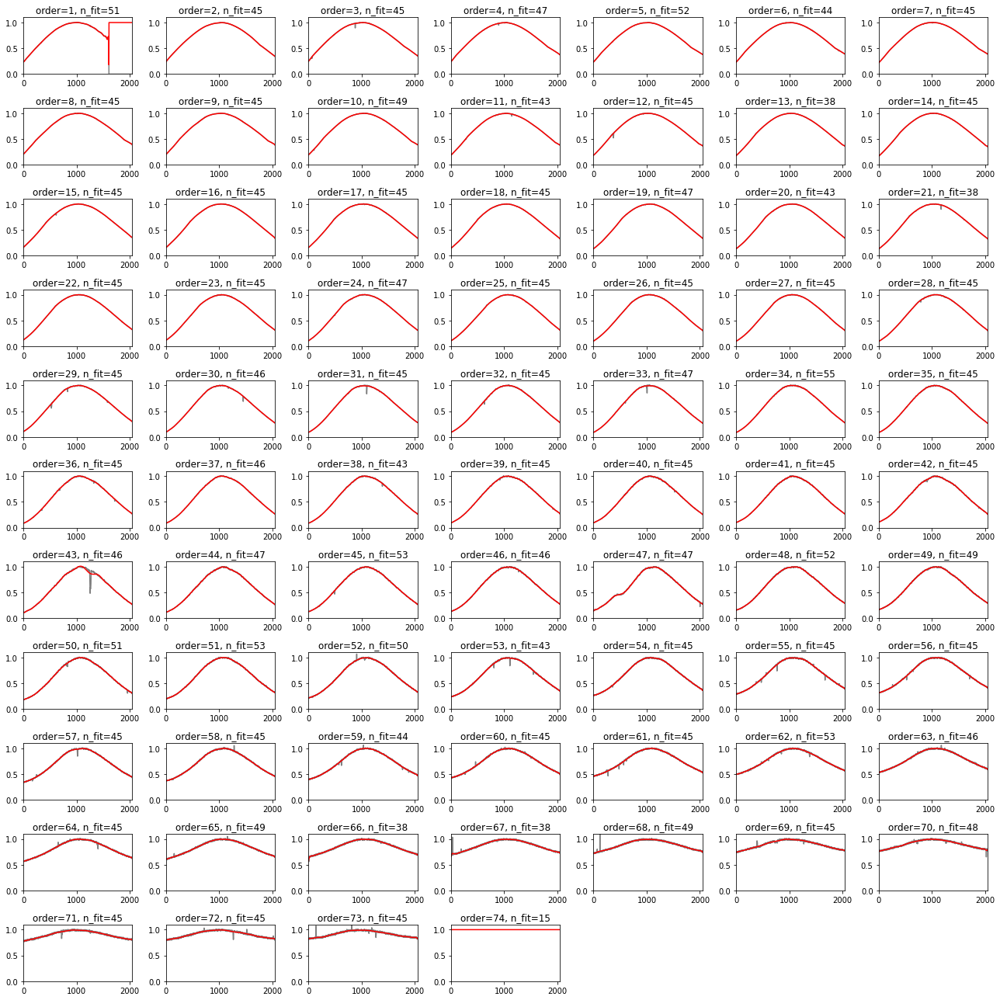

Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_flat_0033_20250128_linear_blaze_1d.fits


In [13]:

# fit the blaze using the 1D Quartz lamp spectrum
flat1d_file = os.path.join(red_directory, flat_extracted.replace(file_extension,"_spatdist_1d"+file_extension))

blaze1d = steles.fit_quartz(flat1d_file, nmin=blaze_polyfit_min_degree, nmax=blaze_polyfit_max_degree, sigma_clip_thresh=blaze_polyfit_sigma_thresh, n_cols=blaze_ncols)

# save the blaze fitting
blaze1d_out = np.array([blaze1d, wave1d], dtype='float32')
file_blaze1d_out = os.path.join(red_directory, flat_extracted.replace(file_extension,"_blaze_1d"+file_extension))
steles.save_spectrum_to_fits(blaze1d_out, file_blaze1d_out, header=flat2d_header, overwrite=True)


In [23]:

# now correct the science frame

with fits.open(red_directory+sci_extracted) as hdul:
    sci2d   = hdul[0].data
    sci2d_header = hdul[0].header

steles.apply_wave_spat_correction(sci2d, sci2d_header,n_orders, wave1d, wavelength_info, spat_rows, wave_pixel_reference, 
                                  arc_extracted, spatdist_csv_prefix, os.path.join(red_directory, sci_extracted), 
                                  file_suffix="_spatdist", file_extension=file_extension)


No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
No distortion coefficients on the database directory.
Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_HR1996_0056_linear_spatdist.fits
Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_HR1996_0056_linear_spatdist_1d.fits


In [24]:

# now correct the science frame

with fits.open(red_directory+sci_extracted) as hdul:
    sci2d   = hdul[0].data
    sci2d_header = hdul[0].header

steles.apply_wave_spat_correction(sci2d, sci2d_header,n_orders, wave1d, wavelength_info, spat_rows, wave_pixel_reference, 
                                  arc_extracted, spatdist_csv_prefix, os.path.join(red_directory, sci_extracted), 
                                  file_suffix="_spatdist", file_extension=file_extension)

# now, blaze correct the science frame
sci_file = os.path.join(red_directory, sci_extracted.replace(file_extension,"_spatdist_1d"+file_extension))
print(sci_file)
# read the header
with fits.open(sci_file) as hdul:
    sci_spatdist        = hdul[0].data
    sci_spatdist_header = hdul[0].header
flux = sci_spatdist[0,:,:]
wave = sci_spatdist[1,:,:]

# apply blaze
flux_corr = steles.apply_blaze(flux, blaze1d)

# Add Blaze and Flux_Corr to the original dataset - TODO - make extensions instead of multi-dimensional array
sci_corr = np.array([flux, wave, blaze1d, flux_corr], dtype='float32')

sci_blaze_header = sci_spatdist_header.copy()
sci_blaze_header.set("ST_BLAZE", value=True, comment="Blaze correction")
sci_blaze_header.set("ST_FBLAZ", value=flat_extracted.replace(file_extension,"_spatdist_1d"+file_extension), comment="File used for fitting the blaze")
sci_blaze_header.set("ST_EXT1", value="IntFlux",       comment="Extension 1", after="ST_FBLAZ")
sci_blaze_header.set("ST_EXT2", value="Wavelength",    comment="Extension 2", after="ST_EXT1")
sci_blaze_header.set("ST_EXT3", value="Blaze",         comment="Extension 3", after="ST_EXT2")
sci_blaze_header.set("ST_EXT4", value="BlazeCorrFlux", comment="Extension 4", after="ST_EXT3")

steles.save_spectrum_to_fits(sci_corr, os.path.join(red_directory, sci_extracted.replace(file_extension,"_spatdist_blaze_1d"+file_extension)), header=sci_blaze_header, overwrite=True)


D:/SOAR/Steles/2026-01-29_blue/RED/master_HR1996_0056_linear_spatdist_1d.fits
Saved: D:/SOAR/Steles/2026-01-29_blue/RED/master_HR1996_0056_linear_spatdist_blaze_1d.fits


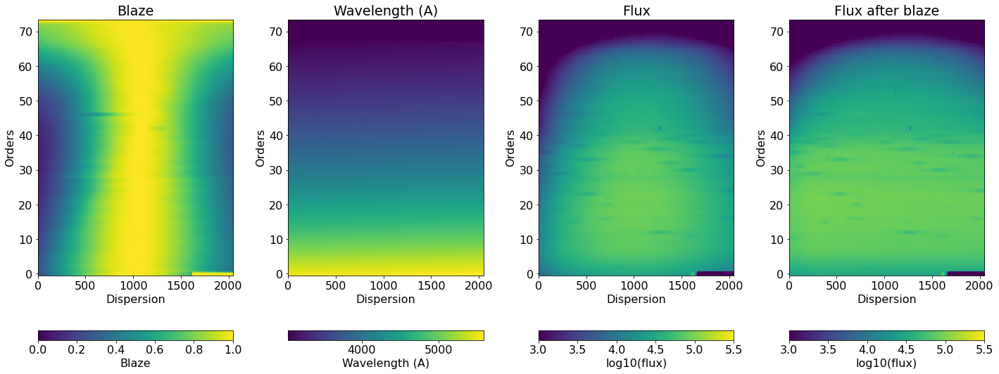

In [25]:
# display products

steles.plot_steles_spectra2d(sci_corr, wave_ext=1, flux_ext=0, blaze_ext=2, bflux_ext=3, 
                             flux_min_threshold=1, flux_lim=[3.0,5.5],
                             plot_vertical=True, plot_figsize=(20,8), plot_fontsize=16, plot_dpi=600, plot_output=None) #os.path.join(red_directory, sci_extracted.replace(file_extension,"_spatdist_blaze_2d"+plot_extension))

#steles.plot_steles_spectra(sci_corr, wave_ext=1, flux_ext=3, n_orders=n_orders, n_plots=5, wave_range=[5000,9050],
#                           flux_range_percentile=[17,99.], line_width=0.75, yscale_log=True,
#                           plot_figsize=(15,15), plot_fontsize=16, plot_dpi=600, plot_output=None) #os.path.join(red_directory, sci_extracted.replace(file_extension,"_spatdist_blaze_1d"+plot_extension))
            

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


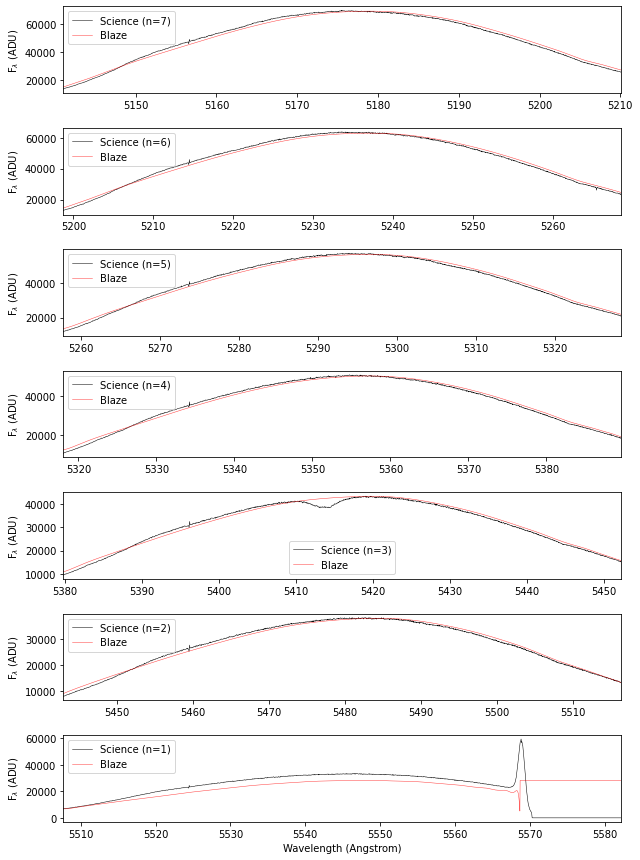

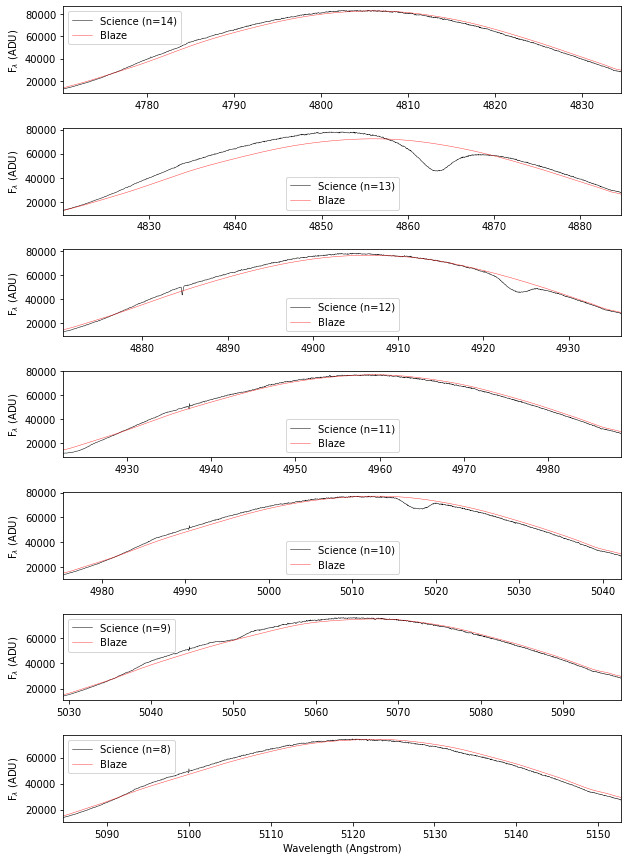

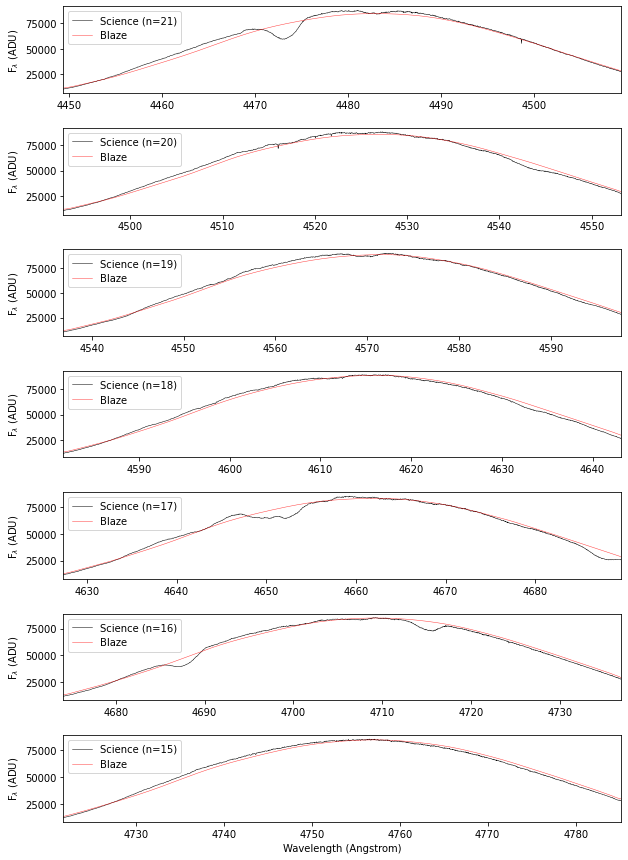

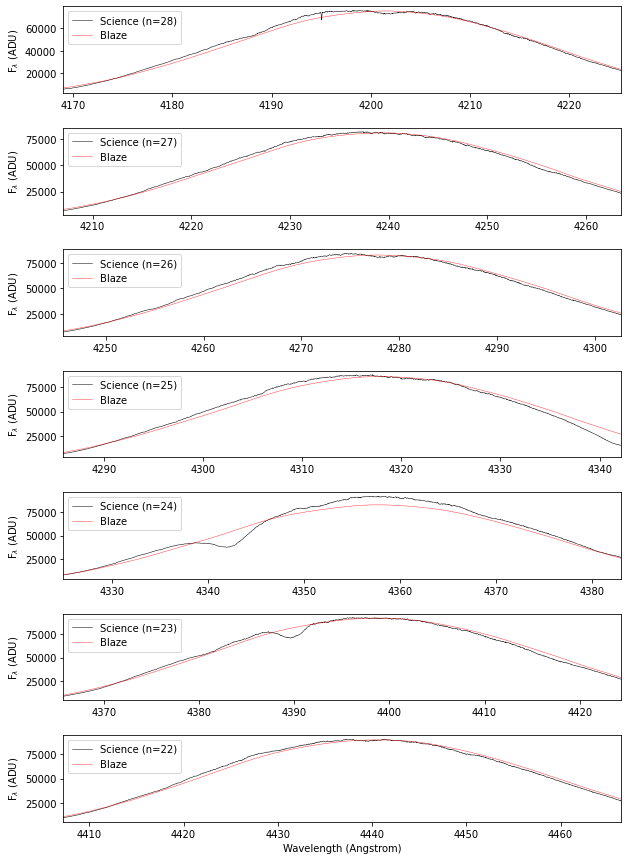

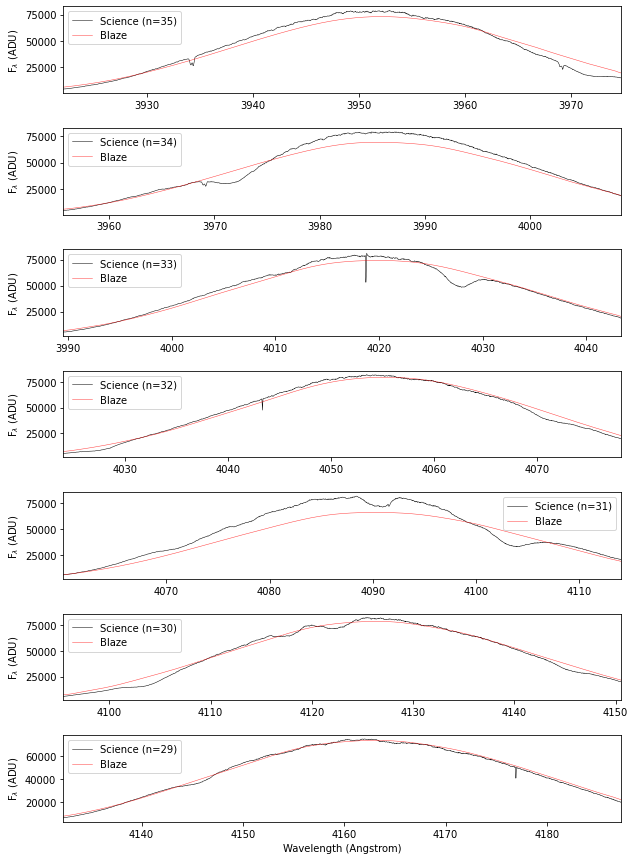

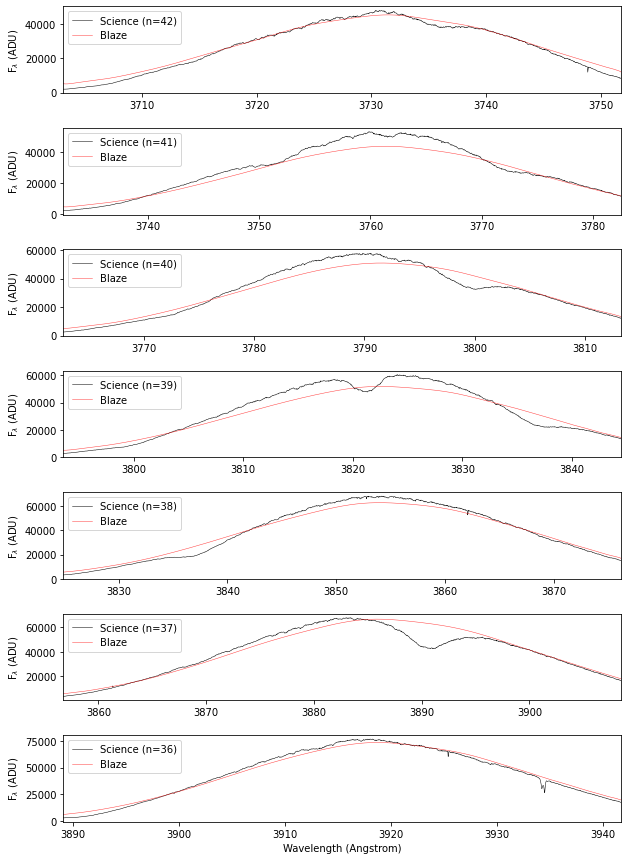

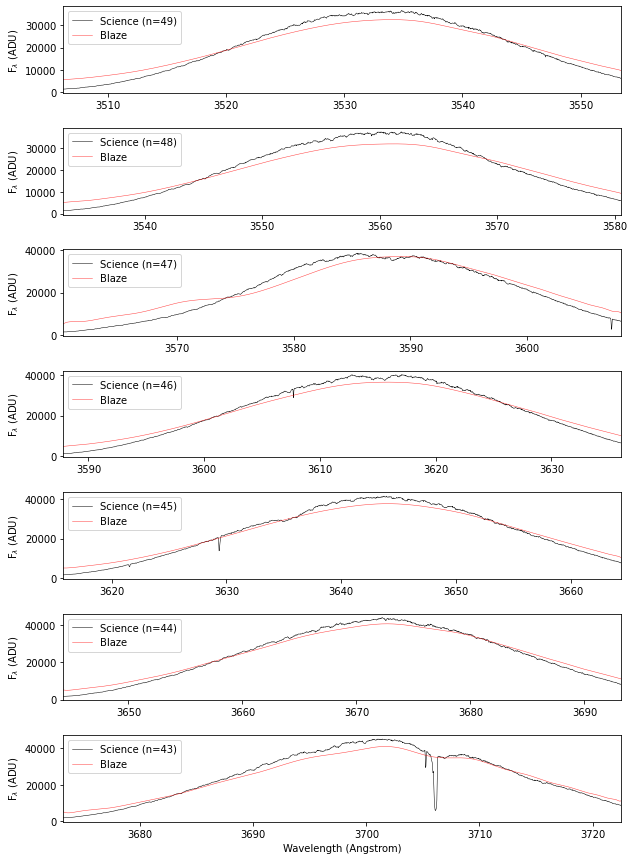

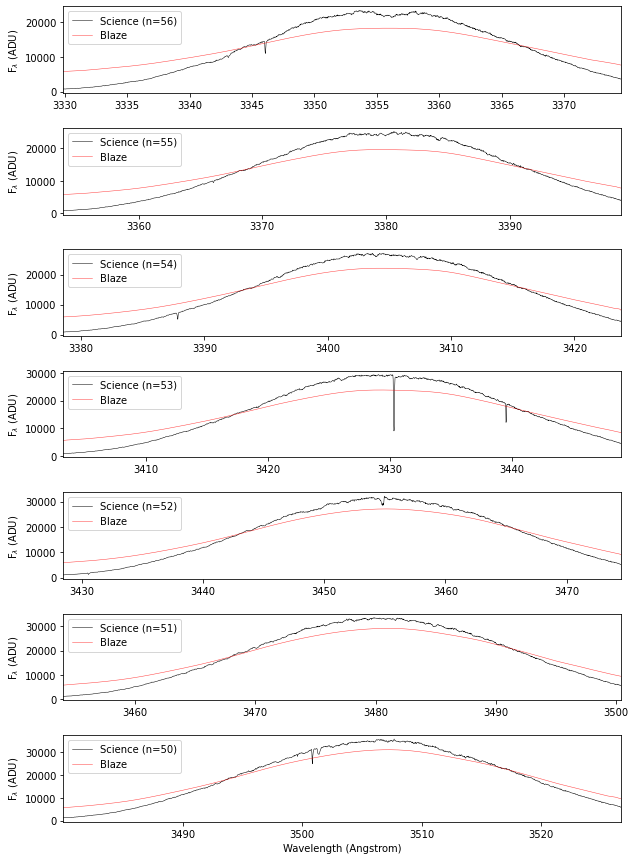

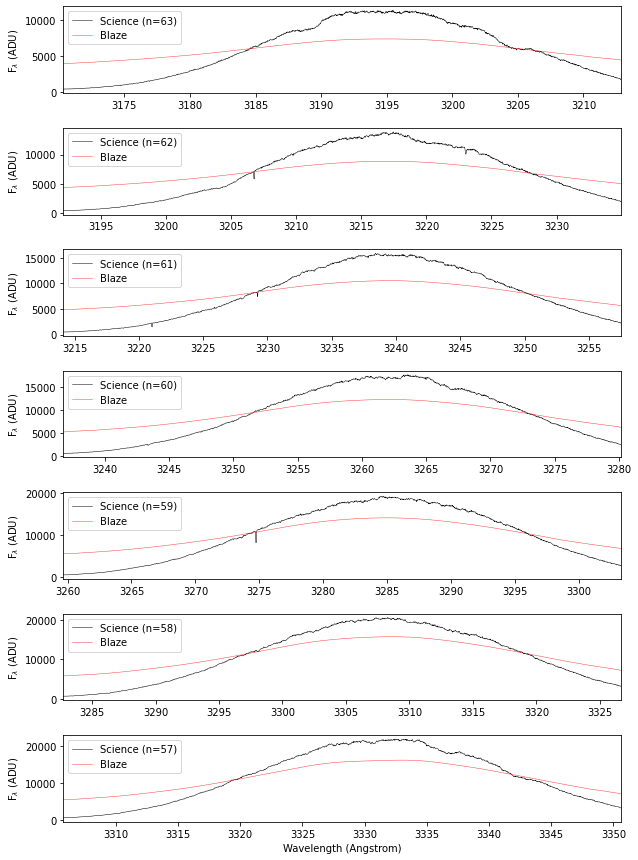

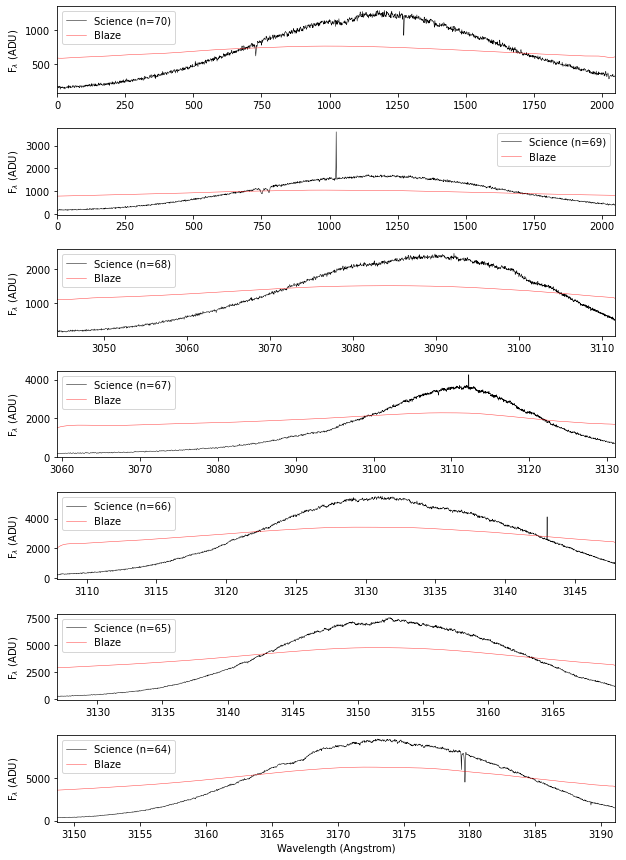

In [26]:

sci1d = np.array(sci_corr, dtype='float32')


figsize=(10, 15)

n_plots = 10

np_orders = int(n_orders / n_plots)


plot_spec=True
if plot_spec:
    
    for nps in range(n_plots):
        nps_range = np.arange(nps * np_orders, (nps+1) * np_orders)

        plt.rcParams.update({'font.size': 10})
        fig, axes = plt.subplots(np_orders, 1, figsize=figsize, gridspec_kw={"hspace": 0.4})
        title=True
        for n in nps_range:
            #print(f"Working n={n+1}")
            nn = (nps+1) * np_orders - n-1
            wave = sci1d[1,n,:]
            flux = sci1d[0,n,:]
            blaze = sci1d[2, n,:]

            factor = np.nanmedian(flux) / np.nanmedian(blaze)
            axes[nn].plot(wave,flux, color='black', lw=0.5, label=f'Science (n={n+1})')
            axes[nn].plot(wave, blaze * factor, color='red', alpha=0.75, lw=0.5, label='Blaze')
            axes[nn].set_xlim(np.nanmin(wave),np.nanmax(wave))
            axes[nn].legend()
            axes[nn].set_ylabel(r'F$_{\lambda}$ (ADU)')
            if title:
                axes[nn].set_xlabel("Wavelength (Angstrom)")
                title=False
        plt.tight_layout()
        plt.savefig(os.path.join(red_directory, sci_extracted.replace(file_extension,f"_extracted_{nps+1}.png")),dpi=600,format='png')
        plt.show()




plot_blaze_cor = False
if plot_blaze_cor:
    for nps in range(n_plots):
        nps_range = np.arange(nps * np_orders, (nps+1) * np_orders)

        plt.rcParams.update({'font.size': 10})
        fig, axes = plt.subplots(np_orders, 1, figsize=figsize, gridspec_kw={"hspace": 0.4})
        title=True
        for n in nps_range:
            #print(f"Working n={n+1}")
            nn = (nps+1) * np_orders - n-1
            wave = sci1d[1,n,:]
            flux = sci1d[3,n,:]
            #blaze = sci1d[2, n,:]

            #factor = np.nanmedian(flux) / np.nanmedian(blaze)
            axes[nn].plot(wave,flux, color='black', lw=0.5, label=f'Science (n={n+1})')
            #axes[nn].plot(wave, blaze * factor, color='red', alpha=0.75, lw=0.5, label='Blaze')
            axes[nn].set_xlim(np.nanmin(wave),np.nanmax(wave))
            axes[nn].legend()
            axes[nn].set_ylabel(r'F$_{\lambda}$/F$_{Blaze}$')
            if title:
                axes[nn].set_xlabel("Wavelength (Angstrom)")
                title=False
        plt.tight_layout()
        plt.savefig(os.path.join(red_directory, sci_extracted.replace(file_extension,f"_blazecor_{nps+1}.png")),dpi=600,format='png')
        plt.show()
    

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


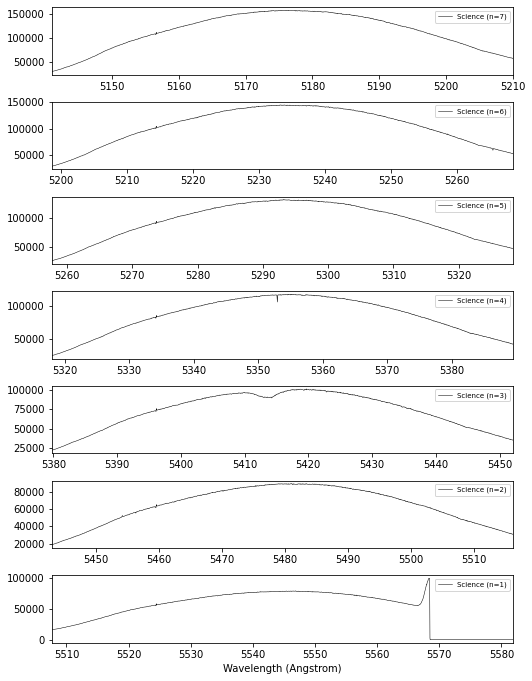

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


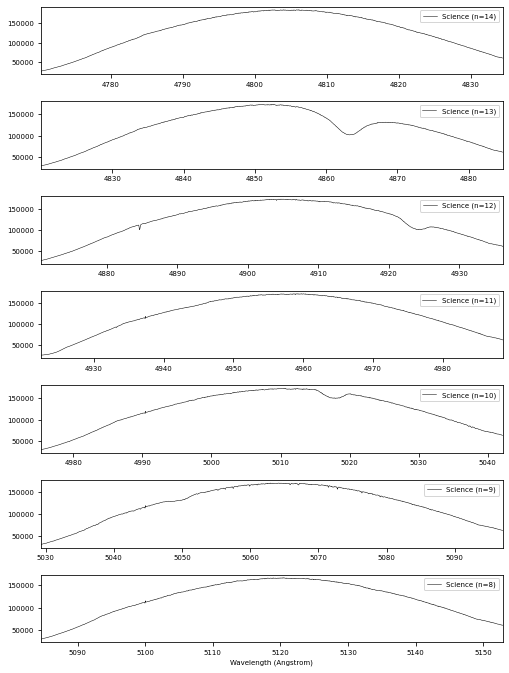

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


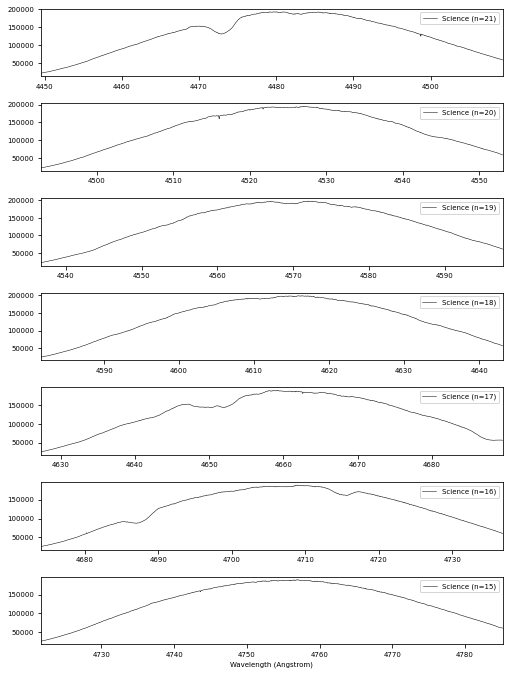

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


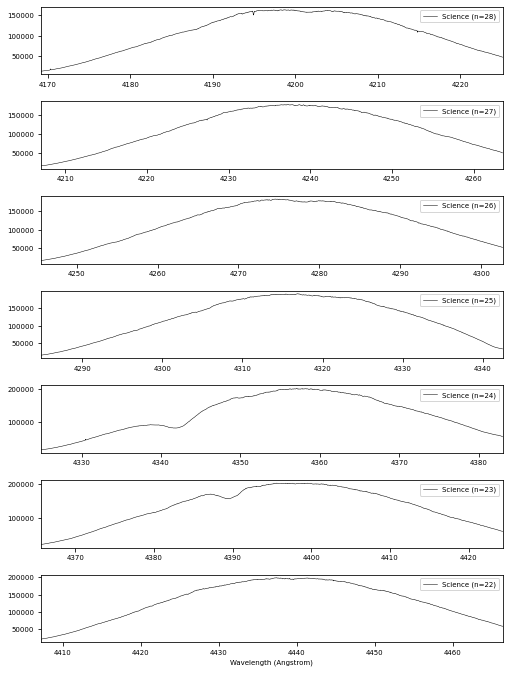

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


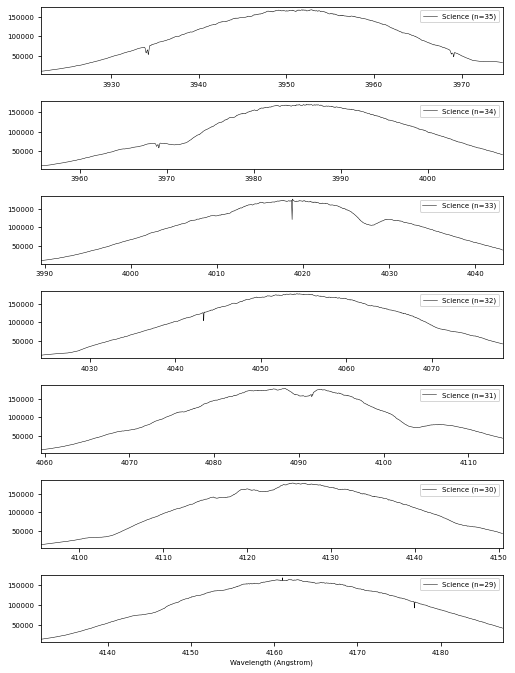

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


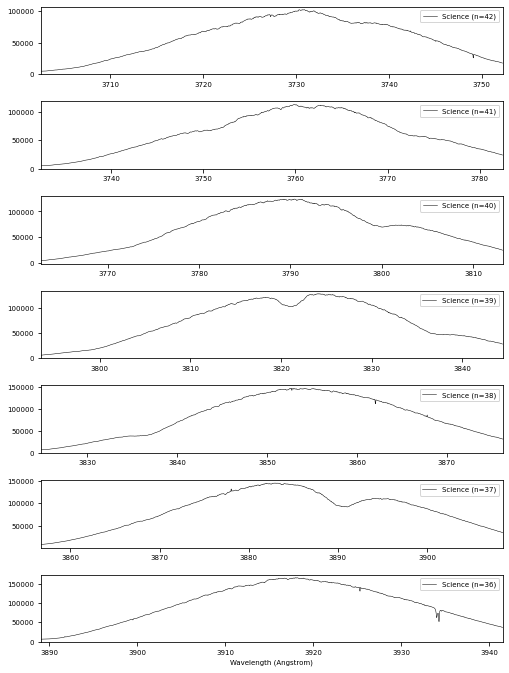

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


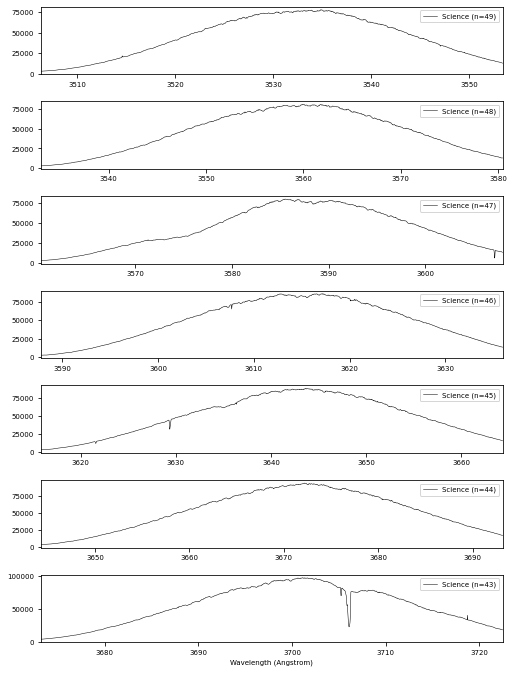

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


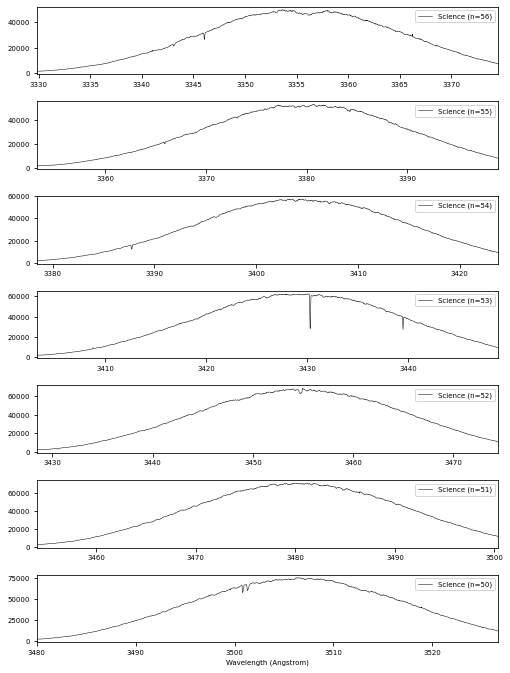

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


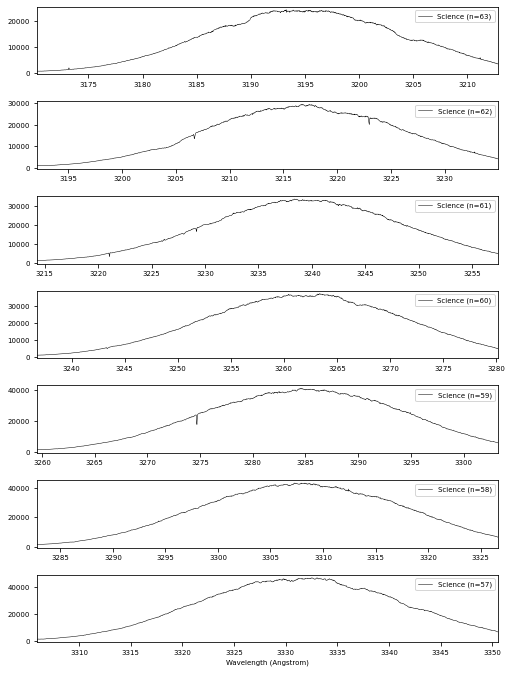

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


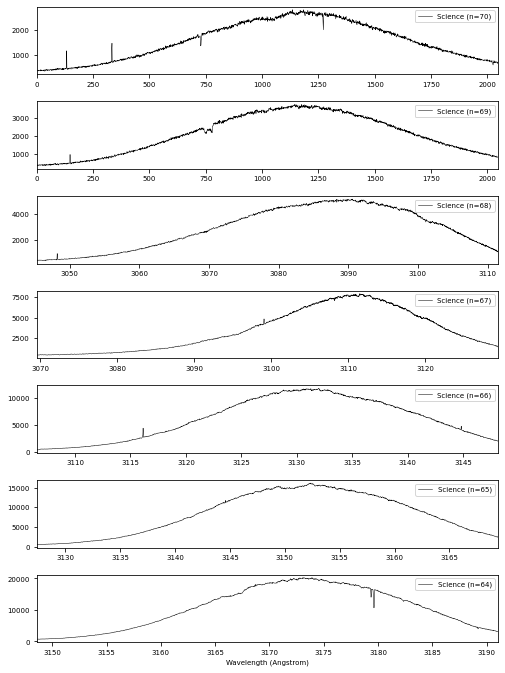

In [11]:

sci1d = np.array(sci_corr, dtype='float32')


cm = 1/2.54
figsize=(21.0*cm,29.7*cm)

n_plots = 10

np_orders = int(n_orders / n_plots)

for nps in range(n_plots):
    nps_range = np.arange(nps * np_orders, (nps+1) * np_orders)

    fig, axes = plt.subplots(np_orders, 1, figsize=figsize, gridspec_kw={"hspace": 0.4})
    plt.rcParams.update({'font.size': 7})
    title=True
    for n in nps_range:
        #print(f"Working n={n+1}")
        nn = (nps+1) * np_orders - n-1
        wave = sci1d[1,n,:]
        flux = sci1d[0,n,:]
        #blaze = blaze_orders[n,:]

        #factor = np.nanmedian(flux) / np.nanmedian(blaze)
        #axes[nn].plot(wave, blaze * factor, color='red', alpha=0.75, lw=0.5, label='Blaze')
        axes[nn].plot(wave,flux, color='black', lw=0.5, label=f'Science (n={n+1})')
        axes[nn].set_xlim(np.nanmin(wave),np.nanmax(wave))
        axes[nn].legend()
        if title:
            axes[nn].set_xlabel("Wavelength (Angstrom)")
            title=False
    plt.tight_layout()
    plt.savefig(os.path.join(red_directory, sci_extracted.replace(".fits",f"_spatdist_blaze_1d_plot_{nps+1}.pdf")),dpi=600,format='pdf')
    plt.show()

In [ ]:
"""
    Created on Jan 14 2026
    
    Description: This routine extracts STELES spectrum
    
    @author: Eder Martioli <emartioli@lna.br>
    
    Laboratório Nacional de Astrofísica, Brazil
    
    Simple usage example:
    
    python steles_extract_spectrum.py --input=master_AUMic_0096_linear_spatdist.fits -p -v
    
    """

__version__ = "1.0"

__copyright__ = """
    Copyright (c) ...  All rights reserved.
    """

from optparse import OptionParser
import os,sys
import glob
import numpy as np
import astropy.io.fits as fits

import matplotlib.pyplot as plt
from scipy import optimize
from copy import deepcopy
import warnings

from scipy import signal
import scipy.interpolate as sint

from PyAstronomy import pyasl

def get_profile(spec2d_data, use_median=True, plot=False) :

    loc = {}

    norders, nprof, nspix = len(spec2d_data), len(spec2d_data[0]), len(spec2d_data[0][0])

    midpoint = np.floor(nprof / 2)
    xpix = np.linspace(0,nprof,nprof,endpoint=False)
    profile = np.zeros(nprof)
    profile_orders = []
    for order in range(norders) :
        img = spec2d_data[order]

        with warnings.catch_warnings(record=True) as _:
            if use_median :
                tmp_profile = np.nanmedian(img,axis=1)
            else :
                tmp_profile = np.nanmean(img,axis=1)
                
            nans = np.isnan(tmp_profile)
            tmp_profile[nans] = 0.
            profile_orders.append(tmp_profile)
            profile += tmp_profile

    xmax = np.nanargmax(profile)
    xmin = np.nanargmin(profile)

    if plot :
        nprofile = profile/np.nanmax(profile)
        plt.plot(np.array([xmax]), np.array([nprofile[xmax]]), 'o', color='g')
        plt.hlines(nprofile[xmin], 0, np.max(xpix), ls='--', color='g')
        plt.plot(xpix, nprofile, ':', color='k')
        plt.legend()
        plt.xlabel("x-coord (pixel)")
        plt.ylabel("normalized flux")
        plt.show()
    
    loc["x"] = xpix
    loc["y"] = profile
    loc["profile_orders"] = profile_orders
    return loc


def fit_profile(img, var, f, prof, function='polynomial', fitorder=2, plot=False) :
    
    nprof, nspix = len(prof), len(f)

    x = np.linspace(0,nspix,nspix,endpoint=False)
    ydata, yvar = deepcopy(img), deepcopy(var)
        
    for i in range(nspix) :
        good = ydata[:,i] >= 0

        with warnings.catch_warnings(record=True) as _:
            median = np.nanmedian(ydata[good,i])
            medsig = np.nanmedian(np.abs(ydata[good,i] - median)) / 0.67449

            good &= np.sqrt(yvar[:,i]) < 2.0*medsig
            ydata[~good,i] *= np.nan

            ydata[:,i] /= f[i]
            yvar[:,i] /= f[i]*f[i]
    
    prof2D = np.zeros_like(img)

    for i in range(nprof) :
        if len(x[np.isfinite(ydata[i])]) :
            with warnings.catch_warnings(record=True) as _:
                # First fit a low order polynomial fora first iteration
                if function == 'polynomial' or function == 'spline' :
                    prof2D[i] = fit_continuum(x, ydata[i], function=function, order=fitorder, nit=5, rej_low=2.5, rej_high=2.5, grow=3, med_filt=0, percentile_low=0.,percentile_high=100.,min_points=300, xlabel="spectral pixels", ylabel="flux fraction", plot_fit=False, silent=True)
                else :
                    prof2D[i] = np.nanmedian(ydata[i])
                
                medsig = np.nanmedian(np.abs(ydata[i] - prof2D[i])) / 0.67449
                good = ydata[i] > prof2D[i] - 5*medsig
                good &= ydata[i] < prof2D[i] + 5*medsig
                good &= np.sqrt(yvar[i]) < 2.0*medsig
        
                ydata[i,~good] *= np.nan
            
                if len(x[np.isfinite(ydata[i])]) == 0 :
                    prof2D[i] *= np.nan
        
        if len(x[np.isfinite(ydata[i])]) :
            with warnings.catch_warnings(record=True) as _:
                if function == 'polynomial' or function == 'spline' :
                    prof2D[i] = fit_continuum(x, ydata[i], function=function, order=fitorder, nit=2, rej_low=3.0, rej_high=3.0, grow=3, med_filt=0, percentile_low=0.,percentile_high=100.,min_points=300, xlabel="spectral pixels", ylabel="flux fraction", plot_fit=False, silent=True)
                else :
                    prof2D[i] = np.nanmedian(ydata[i])

                sig = np.nanstd(ydata[i] - prof2D[i])
                good = ydata[i] > prof2D[i] - 3*sig
                good &= ydata[i] < prof2D[i] + 3*sig
                ydata[i,~good] *= np.nan
            
                if len(x[np.isfinite(ydata[i])]) == 0 :
                    prof2D[i] *= np.nan
                
        first_j, last_j = 0, nspix
        
        for j in range(nspix) :
            if np.isfinite(ydata[i][j]) and  ydata[i][j] > 0 :
                first_j = j
                break
        for j in range(nspix) :
            if np.isfinite(ydata[i][nspix-j-1]) and  ydata[i][nspix-j-1] > 0 :
                last_j = nspix-j-1
                break
                
        with warnings.catch_warnings(record=True) as _:
            prof2D[i][:first_j] *= np.nan
            prof2D[i][last_j:] *= np.nan

        if plot :
            plt.errorbar(x+i*nspix, ydata[i], yerr=np.sqrt(yvar[i]), fmt='.', alpha=0.3)
            plt.plot(x+i*nspix, prof2D[i],'k-', lw=2)
       
            
    if plot :
        plt.show()
    
    return prof2D


def fit_continuum(wav, spec, function='polynomial', order=3, nit=5, rej_low=2.0,
    rej_high=2.5, grow=1, med_filt=0, percentile_low=0., percentile_high=100.,
                  min_points=10, xlabel="", ylabel="", plot_fit=False, verbose=False, silent=False):
    """
    Continuum fitting re-implemented from IRAF's 'continuum' function
    in non-interactive mode only but with additional options.

    :Parameters:
    
    wav: array(float)
        abscissa values (wavelengths, velocities, ...)

    spec: array(float)
        spectrum values

    function: str
        function to fit to the continuum among 'polynomial', 'spline3'

    order: int
        fit function order:
        'polynomial': degree (not number of parameters as in IRAF)
        'spline3': number of knots

    nit: int
        number of iteractions of non-continuum points
        see also 'min_points' parameter

    rej_low: float
        rejection threshold in unit of residul standard deviation for point
        below the continuum

    rej_high: float
        same as rej_low for point above the continuum

    grow: int
        number of neighboring points to reject

    med_filt: int
        median filter the spectrum on 'med_filt' pixels prior to fit
        improvement over IRAF function
        'med_filt' must be an odd integer

    percentile_low: float
        reject point below below 'percentile_low' percentile prior to fit
        improvement over IRAF function
        "percentile_low' must be a float between 0. and 100.

    percentile_high: float
        same as percentile_low but reject points in percentile above
        'percentile_high'
        
    min_points: int
        stop rejection iterations when the number of points to fit is less than
        'min_points'

    plot_fit: bool
        if true display two plots:
            1. spectrum, fit function, rejected points
            2. residual, rejected points

    verbose: bool
        if true fit information is printed on STDOUT:
            * number of fit points
            * RMS residual
    """
    if silent :
        import warnings
        warnings.simplefilter('ignore', np.RankWarning)
    
    mspec = np.ma.masked_array(spec, mask=np.zeros_like(spec))
    # mask 1st and last point: avoid error when no point is masked
    # [not in IRAF]
    mspec.mask[0] = True
    mspec.mask[-1] = True
    
    mspec = np.ma.masked_where(np.isnan(spec), mspec)
    
    # apply median filtering prior to fit
    # [opt] [not in IRAF]
    if int(med_filt):
        fspec = signal.medfilt(spec, kernel_size=med_filt)
    else:
        fspec = spec
    # consider only a fraction of the points within percentile range
    # [opt] [not in IRAF]
    mspec = np.ma.masked_where(fspec < np.percentile(fspec, percentile_low),
        mspec)
    mspec = np.ma.masked_where(fspec > np.percentile(fspec, percentile_high),
        mspec)
    # perform 1st fit
    if function == 'polynomial':
        coeff = np.polyfit(wav[~mspec.mask], spec[~mspec.mask], order)
        cont = np.poly1d(coeff)(wav)
    elif function == 'spline3':
        knots = wav[0] + np.arange(order+1)[1:]*((wav[-1]-wav[0])/(order+1))
        spl = sint.splrep(wav[~mspec.mask], spec[~mspec.mask], k=3, t=knots)
        cont = sint.splev(wav, spl)
    else:
        raise(AttributeError)
    # iteration loop: reject outliers and fit again
    if nit > 0:
        for it in range(nit):
            res = fspec-cont
            sigm = np.std(res[~mspec.mask])
            # mask outliers
            mspec1 = np.ma.masked_where(res < -rej_low*sigm, mspec)
            mspec1 = np.ma.masked_where(res > rej_high*sigm, mspec1)
            # exlude neighbors cf IRAF's continuum parameter 'grow'
            if grow > 0:
                for sl in np.ma.clump_masked(mspec1):
                    for ii in range(sl.start-grow, sl.start):
                        if ii >= 0:
                            mspec1.mask[ii] = True
                    for ii in range(sl.stop+1, sl.stop+grow+1):
                        if ii < len(mspec1):
                            mspec1.mask[ii] = True
            # stop rejection process when min_points is reached
            # [opt] [not in IRAF]
            if np.ma.count(mspec1) < min_points:
                if verbose:
                    print("  min_points %d reached" % min_points)
                break
            mspec = mspec1
            if function == 'polynomial':
                coeff = np.polyfit(wav[~mspec.mask], spec[~mspec.mask], order)
                cont = np.poly1d(coeff)(wav)
            elif function == 'spline3':
                knots = wav[0] + np.arange(order+1)[1:]*((wav[-1]-wav[0])/(order+1))
                spl = sint.splrep(wav[~mspec.mask], spec[~mspec.mask], k=3, t=knots)
                cont = sint.splev(wav, spl)
            else:
                raise(AttributeError)
    # compute residual and rms
    res = fspec-cont
    sigm = np.std(res[~mspec.mask])
    if verbose:
        print("  nfit=%d/%d" %  (np.ma.count(mspec), len(mspec)))
        print("  fit rms=%.3e" %  sigm)
    # compute residual and rms between original spectrum and model
    # different from above when median filtering is applied
    ores = spec-cont
    osigm = np.std(ores[~mspec.mask])
    if int(med_filt) and verbose:
        print("  unfiltered rms=%.3e" %  osigm)
    # plot fit results
    if plot_fit:
        # overplot spectrum and model + mark rejected points
        fig1 = plt.figure(1)
        ax1 = fig1.add_subplot(111)
        ax1.plot(wav[~mspec.mask], spec[~mspec.mask],
            c='tab:blue', lw=1.0)
        # overplot median filtered spectrum
        if int(med_filt):
            ax1.plot(wav[~mspec.mask], fspec[~mspec.mask],
                c='tab:cyan', lw=1.0)
        ax1.scatter(wav[mspec.mask], spec[mspec.mask], s=20., marker='d',
        edgecolors='tab:gray', facecolors='none', lw=0.5)
        ax1.plot(wav, cont, ls='--', c='tab:orange')
        if nit > 0:
            # plot residuals and rejection thresholds
            fig2 = plt.figure(2)
            ax2 = fig2.add_subplot(111)
            ax2.axhline(0., ls='--', c='tab:orange', lw=1.)
            ax2.axhline(-rej_low*sigm, ls=':')
            ax2.axhline(rej_high*sigm, ls=':')
            ax2.scatter(wav[mspec.mask], res[mspec.mask],
                s=20., marker='d', edgecolors='tab:gray', facecolors='none',
                lw=0.5)
            ax2.scatter(wav[~mspec.mask], ores[~mspec.mask],
                marker='o', s=10., edgecolors='tab:blue', facecolors='none',
                lw=.5)
            # overplot median filtered spectrum
            if int(med_filt):
                ax2.scatter(wav[~mspec.mask], res[~mspec.mask],
                    marker='s', s=5., edgecolors='tab:cyan', facecolors='none',
                    lw=.2)
        if xlabel != "" :
            plt.xlabel(xlabel)
        if ylabel != "" :
            plt.ylabel(ylabel)
        plt.show()
    return cont


def extract_flux(spec2d_data, var2d_data, profile, optimal_extraction=True, niter=3, nsigclip=3, fit_profile_function='polynomial', plot_fit_profile=False, plot=False, verbose=False) :

    norders, nspix = len(spec2d_data), len(spec2d_data[0][0])

    flux, variance = [], []
    spix = np.linspace(0,nspix,nspix,endpoint=False)
    
    for order in range(norders) :
        prof = profile["y"]
        prof[prof<0] = 0.
        prof = prof / np.nansum(prof)
        
        img = spec2d_data[order]
        var = var2d_data[order]

        f = np.nansum(img,axis=0)
        v = np.nansum(var,axis=0)
        if plot :
            plt.errorbar(spix+order*nspix, f, yerr=np.sqrt(v), fmt='o', color='darkgrey', alpha=0.5)

        # First fit to profile
        try :
            print("Fitting instrument profile for order {}".format(order))
            prof2D = fit_profile(img, var, f, prof, function=fit_profile_function, fitorder=2, plot=False)
        except :
            prof2D = np.zeros_like(img)
            for i in range(nspix) :
                prof2D[:,i] = prof
        
        if optimal_extraction :
            for iter in range(niter) :
                if verbose :
                    print("Optimal extraction of order={} iter={}".format(order,iter))
                
               # try :
                if iter == niter-1 :
                    prof2D = fit_profile(img, var, f, prof, function=fit_profile_function, fitorder=5, plot=plot_fit_profile)
                else :
                    prof2D = fit_profile(img, var, f, prof, function=fit_profile_function, fitorder=3, plot=False)
                #except :
                #    print("WARNING: could not fit profile, skipping ...")
                    
                num, den = np.zeros_like(spix), np.zeros_like(spix)
            
                for i in range(len(prof)) :
                    mask = (img[i] - f * prof2D[i])**2 < nsigclip * nsigclip * v

                    num[mask] += img[i][mask] * prof2D[i][mask] / var[i][mask]
                    den[mask] += prof2D[i][mask] * prof2D[i][mask] / var[i][mask]
    
                den[den==0] = np.nan

                f = num / den
                v = 1. / den
            if plot :
                plt.errorbar(spix+order*nspix, f, yerr=np.sqrt(v), fmt='.', color='darkgreen')

        flux.append(f)
        variance.append(v)

    if plot :
        plt.ylabel("flux")
        plt.xlabel("pixel + npix x order number")
        plt.show()
     
    return flux, variance


def extract_spectrum(spec2d_file, wave=None, optimal_extraction=True, output="", plot=False, verbose=False) :
    
    hdul = fits.open(spec2d_file)
    
    spec2d_data = hdul[0].data
    var2d_data = hdul[0].data
    
    profile = get_profile(spec2d_data, use_median=True, plot=plot)

    flux, variance = extract_flux(spec2d_data, var2d_data, profile, optimal_extraction=optimal_extraction, niter=3, nsigclip=5, fit_profile_function='median', plot_fit_profile=False, plot=plot, verbose=verbose)
    
    return flux, variance

    
def optimal_extraction(input_fits, output_fits, wave=None, optimal_extraction=True, plot=True, verbose=True):

    # Exctract flux sum pectrum
    #flux, variance = extract_spectrum(options.input, wave=None, optimal_extraction=False, output=options.output, plot=options.plot, verbose=options.verbose)
    flux, variance = extract_spectrum(input_fits, wave=wave, optimal_extraction=optimal_extraction, output=output_fits, plot=plot, verbose=verbose)
    norders, nspix = len(flux), len(flux[0])
    spix = np.linspace(0,nspix,nspix,endpoint=False)
    plt.figure(figsize=(25,10))
    for order in range(norders) :
        plt.plot(spix+order*nspix, flux[order], '-', lw=1, color='darkblue',label="optimal flux")
        #plt.errorbar(spix+order*nspix, flux[order], yerr=np.sqrt(variance[order]), fmt='.', color='darkblue')

    plt.ylabel("flux")
    plt.xlabel("pixel + npix x order number")
    #plt.legend()
    plt.show()
    print("DONE")


# now, blaze correct the science frame
sci_file = os.path.join(red_directory, sci_extracted.replace(file_extension,"_spatdist"+file_extension))
out_file = os.path.join(red_directory, sci_extracted.replace(file_extension,"_spatdist_optimal1d"+file_extension))



#optimal_extraction(sci_file, out_file, plot=True, verbose=True)
optimal_extraction(sci_file, out_file, plot=True, verbose=False)

